# IMDb sentiment: n-gram, Linear/RBF SVM và Kaggle 2 GPU

## 1. Kiểm tra dependency
Ưu tiên GPU stack có sẵn nếu probe trong subprocess thành công. Nếu thiếu,
tự nhận CUDA toolkit/driver rồi cài wheel cuML/CuPy đúng họ CUDA 12/13 vào venv
riêng dưới `/kaggle/working/.svm_gpu_runtime`. Cài bằng đúng Python runtime hiện
tại, kể cả Python 3.13; pip phải tìm được binary wheel tương thích.

Worker giữ cùng scikit-learn/joblib với kernel để đọc vectorizer nhất quán,
nhưng tự giải quyết NumPy/SciPy theo yêu cầu cuML. Không thay NumPy đã nạp trong
kernel và không cần restart giữa Run All. Cần Internet. Nếu resolver/CUDA probe
lỗi, dừng trước train và in log cài đặt; không chuyển sang CPU ngầm.

Nguồn cài đặt: [RAPIDS](https://docs.nvidia.com/datascience/install/),
[CuPy CUDA wheels](https://docs.cupy.dev/en/stable/install.html).

In [1]:
import importlib.util
import subprocess
import sys

packages = {"datasets": "datasets", "sklearn": "scikit-learn", "pandas": "pandas",
            "scipy": "scipy", "matplotlib": "matplotlib", "joblib": "joblib",
            "ipywidgets": "ipywidgets"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

BOOTSTRAP_SOURCE = '"""Prepare isolated GPU workers without replacing a running notebook\'s NumPy."""\nimport hashlib\nimport importlib.metadata\nimport json\nimport os\nfrom pathlib import Path\nimport re\nimport subprocess\nimport sys\nimport venv\n\n\nRAPIDS_RELEASE = "26.10.*"\n\n\ndef choose_cuda_major(nvcc_output, nvidia_smi_output, override=None):\n    """Prefer installed toolkit; nvidia-smi reports driver capability, not toolkit."""\n    if override is not None:\n        if str(override) not in {"12", "13"}:\n            raise ValueError("SVM_CUDA_MAJOR must be 12 or 13")\n        return int(override), "explicit override"\n    match = re.search(r"release\\s+(12|13)\\.\\d+", nvcc_output)\n    if match:\n        return int(match.group(1)), "installed nvcc toolkit"\n    match = re.search(r"CUDA Version:\\s*(\\d+)\\.\\d+", nvidia_smi_output)\n    if match and int(match.group(1)) >= 12:\n        # CUDA component wheels provide the toolkit when nvcc is absent.\n        return min(int(match.group(1)), 13), "driver capability + CUDA component wheels"\n    raise RuntimeError("Cannot detect supported CUDA 12/13. Check Kaggle GPU/driver settings.")\n\n\ndef gpu_package_specs(major, sklearn_version, joblib_version):\n    if major not in (12, 13):\n        raise ValueError("Only CUDA 12/13 wheels are supported")\n    return [f"cuml-cu{major}=={RAPIDS_RELEASE}", f"cupy-cuda{major}x[ctk]",\n            f"scikit-learn=={sklearn_version}", f"joblib=={joblib_version}"]\n\n\nPROBE = r\'\'\'\nimport json, sys\nimport numpy, scipy, sklearn, joblib\nimport cupy as cp\nimport cuml\nfrom cuml.svm import SVC\ncount = cp.cuda.runtime.getDeviceCount()\nif count < 2:\n    raise RuntimeError(f"Need two visible GPUs, found {count}")\nassert int(cp.arange(4, dtype=cp.int32).sum().get()) == 6\nprint(json.dumps({"python":sys.executable,"python_version":sys.version,\n                  "devices":count,"cupy":cp.__version__,"cuml":cuml.__version__,\n                  "numpy":numpy.__version__,"scipy":scipy.__version__,\n                  "sklearn":sklearn.__version__,"joblib":joblib.__version__}))\n\'\'\'\n\n\ndef runtime_environment(python):\n    environment = os.environ.copy()\n    if str(python) != sys.executable:\n        environment.pop("PYTHONPATH", None)\n        environment.pop("PYTHONHOME", None)\n    return environment\n\n\ndef probe_runtime(python, timeout=180):\n    result = subprocess.run([str(python), "-c", PROBE], text=True,\n                            capture_output=True, timeout=timeout, env=runtime_environment(python))\n    if result.returncode:\n        return None, (result.stdout + "\\n" + result.stderr).strip()\n    for line in reversed(result.stdout.splitlines()):\n        try:\n            return json.loads(line), ""\n        except json.JSONDecodeError:\n            continue\n    return None, "GPU probe produced no valid environment JSON: " + result.stdout\n\n\ndef select_worker_python(root=None):\n    """Reuse working host cuML, or install GPU wheels in a private Python venv."""\n    try:\n        inventory = subprocess.check_output(\n            ["nvidia-smi", "--query-gpu=uuid,name", "--format=csv,noheader"],\n            text=True, stderr=subprocess.STDOUT)\n        smi = subprocess.check_output(["nvidia-smi"], text=True, stderr=subprocess.STDOUT)\n    except (FileNotFoundError, subprocess.CalledProcessError) as error:\n        raise RuntimeError("No working NVIDIA GPU runtime. Select GPU T4 x2 on Kaggle first.") from error\n    rows = [line for line in inventory.splitlines() if line.strip()]\n    visible = os.environ.get("CUDA_VISIBLE_DEVICES", "").strip()\n    if len(rows) < 2 or visible == "-1" or (visible and len(visible.split(",")) < 2):\n        raise RuntimeError("This notebook needs two visible GPUs. Select Kaggle GPU T4 x2.")\n    print("GPU inventory:\\n" + inventory, flush=True)\n    print("Notebook Python:", sys.version, flush=True)\n    host_info, host_error = probe_runtime(sys.executable)\n    if host_info is not None:\n        print("Existing GPU runtime passed:", json.dumps(host_info), flush=True)\n        return sys.executable, {"mode": "existing", "environment": host_info}\n    print("Existing GPU stack unavailable; preparing isolated workers.\\n" + host_error[-2000:], flush=True)\n    try:\n        nvcc = subprocess.check_output(["nvcc", "--version"], text=True, stderr=subprocess.STDOUT)\n    except (FileNotFoundError, subprocess.CalledProcessError):\n        nvcc = ""\n    major, reason = choose_cuda_major(nvcc, smi, os.environ.get("SVM_CUDA_MAJOR"))\n    sklearn_version = importlib.metadata.version("scikit-learn")\n    joblib_version = importlib.metadata.version("joblib")\n    packages = gpu_package_specs(major, sklearn_version, joblib_version)\n    identity = {"python": list(sys.version_info[:2]), "packages": packages}\n    suffix = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:10]\n    root = Path(root) if root else Path("/kaggle/working/.svm_gpu_runtime")\n    prefix = root / f"cuda{major}_py{sys.version_info.major}{sys.version_info.minor}_{suffix}"\n    python = prefix / "bin" / "python"\n    print(f"CUDA {major} selected from {reason}; worker environment: {prefix}", flush=True)\n    if python.exists():\n        info, _ = probe_runtime(python)\n        if info is not None:\n            return str(python), {"mode": "cached_isolated", "environment": info,\n                                 "cuda_major": major, "selection_reason": reason,\n                                 "requested_packages": packages}\n    prefix.parent.mkdir(parents=True, exist_ok=True)\n    if not python.exists():\n        venv.EnvBuilder(with_pip=True, system_site_packages=False).create(prefix)\n    command = [str(python), "-m", "pip", "install", "--no-cache-dir",\n               "--only-binary=:all:", "--extra-index-url", "https://pypi.nvidia.com", *packages]\n    print("Installing GPU wheels; the notebook kernel\'s scientific packages stay unchanged.", flush=True)\n    try:\n        subprocess.run(command, check=True, env=runtime_environment(python))\n    except subprocess.CalledProcessError as error:\n        raise RuntimeError(\n            f"GPU package installation failed for Python {sys.version_info.major}.{sys.version_info.minor} "\n            f"and CUDA {major}. Check Internet and the pip resolver output above. "\n            "No training has started and no CPU fallback was used.") from error\n    info, diagnostic = probe_runtime(python)\n    if info is None:\n        raise RuntimeError("GPU dependencies installed but CUDA probe failed:\\n" + diagnostic)\n    metadata = {"mode": "installed_isolated", "environment": info, "cuda_major": major,\n                "selection_reason": reason, "requested_packages": packages}\n    (prefix / "runtime_state.json").write_text(json.dumps(metadata, indent=2))\n    print("GPU worker runtime passed:", json.dumps(info), flush=True)\n    return str(python), metadata\n'
bootstrap_namespace = {'__name__': 'kaggle_gpu_bootstrap'}
exec(compile(BOOTSTRAP_SOURCE, 'kaggle_gpu_bootstrap.py', 'exec'), bootstrap_namespace)
WORKER_PYTHON, GPU_BOOTSTRAP_INFO = bootstrap_namespace['select_worker_python']()
print('Worker Python:', WORKER_PYTHON)

GPU inventory:
GPU-ea66ab83-fd9e-db5c-e900-f48d6c697f64, Tesla T4
GPU-ce6d381e-3c6d-6965-b550-98e4e60e4ce8, Tesla T4

Notebook Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Existing GPU runtime passed: {"python": "/usr/bin/python3", "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]", "devices": 2, "cupy": "14.0.1", "cuml": "26.06.00", "numpy": "2.1.3", "scipy": "1.16.3", "sklearn": "1.6.1", "joblib": "1.6.0"}
Worker Python: /usr/bin/python3


## 2. Cấu hình nghiên cứu
`full`: 20.000 train, 6.000 holdout mới, 3-fold, grid C/gamma như thí nghiệm cũ.
`smoke`: dữ liệu nhỏ, một C/gamma, để kiểm tra luồng trước.
Không dùng kết quả smoke làm kết quả cuối kì. Bộ nền có 8 nhóm:
3 n-gram × 2 kernel + cleaning × 2 kernel.
Bật `RUN_VOCAB_ABLATION` để thêm bigram 30.000 features × 2 kernel.
Mặc định thêm hai ablation movie/film × hai kernel (tổng cộng 12 nhóm).
`RUN_MAX_DF_ABLATION` thêm phép loại feature có DF > 80% trong training fold.

Mỗi run tạo thư mục riêng. Có thể điền `RESUME_RUN_DIR` để tiếp tục đúng run đã
ngắt trong cùng session/storage; config phải trùng. Cần tải/Save Version các output
trước khi Kaggle xóa session. Nếu kernel bị kill cứng, chỉ xóa file `.running`
của stage sau khi chắc chắn mọi worker cũ đã dừng.

In [ ]:
import csv
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import re
import sys
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

MODE = "full"                      
RUN_CLEANING_ABLATION = True
RUN_VOCAB_ABLATION = False
RUN_COMMON_WORD_ABLATION = True
RUN_MAX_DF_ABLATION = False
RUN_LABEL_SHUFFLE_CONTROL = True
RUN_NEAR_DUPLICATE_AUDIT = True
REQUIRE_TWO_GPUS = True
RESUME_RUN_DIR = None                
LOCAL_DATASET_DIR = None          
DATASET_REVISION = "main"           
MANUAL_ANNOTATIONS_CSV = None        

assert MODE in {"full", "smoke"}
CONFIG = {
    "mode": MODE, "seed": 42, "backend": "cuml", "tol": 1e-3,
    "worker_python": WORKER_PYTHON,
    "n_train_per_class": 10000 if MODE == "full" else 200,
    "n_test_per_class": 3000 if MODE == "full" else 100,
    "n_folds": 3 if MODE == "full" else 2,
    "C_grid": [0.5, 2, 8] if MODE == "full" else [2],
    "gamma_grid": ["scale", 0.1, 1] if MODE == "full" else [1],
    "kernel_cache_mb": 512, "predict_batch_size": 512,
    "cleaning_ablation": RUN_CLEANING_ABLATION,
    "vocab_ablation": RUN_VOCAB_ABLATION,
    "common_word_ablation": RUN_COMMON_WORD_ABLATION,
    "max_df_ablation": RUN_MAX_DF_ABLATION,
    "label_shuffle_control": RUN_LABEL_SHUFFLE_CONTROL,
    "near_duplicate_audit": RUN_NEAR_DUPLICATE_AUDIT,
    "near_duplicate_cosine_threshold": 0.98,
    "local_dataset_dir": LOCAL_DATASET_DIR, "dataset_revision": DATASET_REVISION,
    "notebook_build_sha": "9990f1573d29ed7f0422d640ea3add3a2b2bd06ba241d93dc31dfcd63f472ba1",
}
OUTPUT_ROOT = (Path("/kaggle/working/sentiment_svm") if Path("/kaggle/working").exists()
               else Path.cwd() / "output" / "kaggle_runs")
RUN_DIR = (Path(RESUME_RUN_DIR) if RESUME_RUN_DIR else
           OUTPUT_ROOT / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
RUN_DIR.mkdir(parents=True, exist_ok=True)
SPECS = [{"id": f"raw_w{n}", "max_ngram": n, "max_features": 12000,
          "min_df": 2, "clean": False} for n in (1, 2, 3)]
if RUN_CLEANING_ABLATION:
    SPECS.append({"id": "clean_w2", "max_ngram": 2, "max_features": 12000,
                  "min_df": 2, "clean": True})
if RUN_VOCAB_ABLATION:
    SPECS.append({"id": "raw_w2_30k", "max_ngram": 2, "max_features": 30000,
                  "min_df": 2, "clean": False})
if RUN_COMMON_WORD_ABLATION:
    for mode in ("unigram", "containing"):
        SPECS.append({"id": f"raw_w2_drop_{mode}", "max_ngram": 2,
                      "max_features": 12000, "min_df": 2, "clean": False,
                      "drop_terms": ["movie", "film"], "drop_mode": mode})
if RUN_MAX_DF_ABLATION:
    SPECS.append({"id": "raw_w2_df80", "max_ngram": 2, "max_features": 12000,
                  "min_df": 2, "clean": False, "drop_above_df": 0.8})
CONFIG["representations"] = SPECS
config_path = RUN_DIR / "config.json"
if config_path.exists() and json.loads(config_path.read_text()) != CONFIG:
    raise ValueError("Resume config/build differs. Restore the original config or start a new run.")
config_path.write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print("RUN_DIR:", RUN_DIR)
display(pd.DataFrame(SPECS))

RUN_DIR: /kaggle/working/sentiment_svm/20261105T152007_994011Z


,id,max_ngram,max_features,min_df,clean,drop_terms,drop_mode
0,raw_w1,1,12000,2,False,NaN,NaN
1,raw_w2,2,12000,2,False,NaN,NaN
2,raw_w3,3,12000,2,False,NaN,NaN
3,clean_w2,2,12000,2,True,NaN,NaN
4,raw_w2_drop_unigram,2,12000,2,False,"[movie, film]",unigram
5,raw_w2_drop_containing,2,12000,2,False,"[movie, film]",containing


## 3. Worker tự chứa trong notebook
CUDA chỉ được khởi tạo trong worker sau khi đã
gắn GPU. Dense float32 dùng cho SVC để tương thích API cuML qua các phiên bản;
ma trận sparse chỉ được chuyển dense trên GPU, có kiểm tra bộ nhớ và predict batch.
Giảm `max_features`/sample size nếu GPU báo thiếu bộ nhớ; không âm thầm đổi mô hình.

In [3]:
WORKER_SOURCE = r'''
"""Experiment helpers embedded verbatim in the standalone Kaggle notebook.

CUDA libraries are imported only inside isolated worker processes. The explicit
sklearn_test backend exists for local integration tests, not GPU benchmarking.
"""

import argparse
import csv
import gc
import hashlib
import json
import os
from pathlib import Path
import subprocess
import sys
import time
import traceback
import zipfile

import joblib
import numpy as np
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score,
)
from sklearn.preprocessing import normalize


def feature_keep_indices(vectorizer, train_matrix, spec):
    """Ablate existing columns, never rejoin tokens or refill the vocabulary."""
    names = vectorizer.get_feature_names_out()
    keep = np.ones(len(names), dtype=bool)
    terms = set(spec.get("drop_terms", []))
    mode = spec.get("drop_mode")
    if mode == "unigram":
        keep &= np.array([name not in terms for name in names])
    elif mode == "containing":
        keep &= np.array([not terms.intersection(name.split()) for name in names])
    elif mode is not None:
        raise ValueError(f"Unknown drop_mode: {mode}")
    if "drop_above_df" in spec:
        # Learned only from the current training fold, including for CV.
        df = train_matrix.getnnz(axis=0) / train_matrix.shape[0]
        keep &= df <= spec["drop_above_df"]
    indices = np.flatnonzero(keep)
    if not len(indices):
        raise ValueError("Feature filtering removed the entire vocabulary")
    return indices


def filter_features(matrix, indices):
    if len(indices) == matrix.shape[1] and np.array_equal(indices, np.arange(matrix.shape[1])):
        result = matrix.tocsr(copy=True)
        result.sort_indices()
        return result
    matrix = matrix[:, indices].tocsr(copy=True)
    # Removing coordinates changes vector length; restore the L2 convention.
    matrix = normalize(matrix, norm="l2", copy=False)
    matrix.sort_indices()
    return matrix


def transform_bundle_features(bundle, preprocessed_texts):
    """Apply vectorizer AND stored feature mask; caller applies spec cleaning."""
    matrix = bundle["vectorizer"].transform(preprocessed_texts).tocsr()
    indices = bundle.get("feature_keep_indices", list(range(matrix.shape[1])))
    return filter_features(matrix, indices)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False,
                                     allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()[:16]


def vectorizer_for(spec):
    return TfidfVectorizer(
        ngram_range=(1, spec["max_ngram"]), min_df=spec.get("min_df", 2),
        max_features=spec["max_features"], sublinear_tf=True,
        lowercase=True, stop_words=None, dtype=np.float32,
    )


def prepare_features(directory, key, spec, train_text, evaluations, y_train):
    """Fit on this training partition ONLY; evaluations never affect vocabulary."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    vectorizer = vectorizer_for(spec)
    start = time.perf_counter()
    train_base = vectorizer.fit_transform(train_text).tocsr()
    if len(y_train) != train_base.shape[0]:
        raise ValueError("Training feature/label row count mismatch")
    indices = feature_keep_indices(vectorizer, train_base, spec)
    train = filter_features(train_base, indices)
    fit_seconds = time.perf_counter() - start
    train_path = directory / f"{key}_train.npz"
    sparse.save_npz(train_path, train, compressed=False)
    y_path = directory / f"{key}_y.npy"
    np.save(y_path, np.asarray(y_train, dtype=np.int32))
    vectorizer_path = directory / f"{key}_vectorizer.joblib"
    joblib.dump(vectorizer, vectorizer_path)
    evaluation_paths = {}
    for name, texts in evaluations.items():
        start = time.perf_counter()
        matrix = filter_features(vectorizer.transform(texts), indices)
        path = directory / f"{key}_{name}.npz"
        sparse.save_npz(path, matrix, compressed=False)
        evaluation_paths[name] = {
            "matrix": str(path.resolve()),
            "tfidf_transform_seconds": time.perf_counter() - start,
        }
    reference = {
        "train": str(train_path.resolve()), "y_train": str(y_path.resolve()),
        "vectorizer": str(vectorizer_path.resolve()), "evaluations": evaluation_paths,
        "n_features": int(train.shape[1]), "tfidf_fit_seconds": fit_seconds,
        "base_n_features": int(train_base.shape[1]),
        "feature_keep_indices": indices.tolist(),
        "removed_features": vectorizer.get_feature_names_out()[
            np.setdiff1d(np.arange(train_base.shape[1]), indices)].tolist(),
    }
    return reference, vectorizer, train


def vocabulary_audit(vectorizer, matrix, spec_id, keep_indices=None):
    all_names = vectorizer.get_feature_names_out()
    names = all_names if keep_indices is None else all_names[keep_indices]
    orders = np.array([name.count(" ") + 1 for name in names])
    rows = []
    for order in (1, 2, 3):
        selected = np.flatnonzero(orders == order)
        coverage = (float(np.mean(matrix[:, selected].getnnz(axis=1) > 0))
                    if len(selected) else 0.0)
        rows.append({"representation": spec_id, "ngram_order": order,
                     "n_features": int(len(selected)),
                     "train_document_coverage": coverage,
                     "matrix_density": matrix.nnz / np.prod(matrix.shape)})
    probes = ["not good", "not worth watching", "very good", "a waste of"]
    retained_names = set(names)
    presence = [{"representation": spec_id, "phrase": p,
                 "in_vocabulary": p in retained_names} for p in probes]
    return rows, presence


def common_term_statistics(vectorizer, base_matrix, y, spec_id, keep_indices):
    """Training-only DF/IDF and normalized TF-IDF, including movie/film."""
    names = vectorizer.get_feature_names_out()
    keep = set(keep_indices)
    df = base_matrix.getnnz(axis=0)
    unigram_indices = [i for i, name in enumerate(names) if " " not in name]
    frequent = sorted(unigram_indices, key=lambda i: (-int(df[i]), names[i]))[:20]
    requested = list(dict.fromkeys(["movie", "film", "not", "good", "bad", "boring",
                                   "excellent"] + [names[i] for i in frequent]))
    rows = []
    y = np.asarray(y)
    csc = base_matrix.tocsc()
    for term in requested:
        index = vectorizer.vocabulary_.get(term)
        row = {"representation": spec_id, "term": term,
               "in_base_vocabulary": index is not None,
               "retained_by_model": index is not None and index in keep}
        if index is not None:
            column = csc[:, index]
            row.update({
                "train_document_frequency": int(df[index]),
                "train_document_fraction": float(df[index] / len(y)),
                "idf": float(vectorizer.idf_[index]),
                "mean_base_l2_tfidf_all_documents": float(column.sum() / len(y)),
                "mean_base_l2_tfidf_when_present": float(column.sum() / max(1, df[index])),
                "document_fraction_negative": float(column[y == 0].getnnz() / np.sum(y == 0)),
                "document_fraction_positive": float(column[y == 1].getnnz() / np.sum(y == 1)),
            })
        rows.append(row)
    return rows


def diagnostic_cases():
    """144 template-authored sentences, 72 pairs; provisional labels, not IMDb."""
    rows = []
    for target_index, target in enumerate(("film", "movie", "story", "performance")):
        for adjective_index, (positive, negative) in enumerate((
                ("good", "bad"), ("enjoyable", "boring"),
                ("impressive", "disappointing"))):
            cases = {
                "local_negation": (
                    (f"The {target} was {positive}.", 1),
                    (f"The {target} was not {positive}.", 0)),
                "longer_negation": (
                    (f"I think the {target} was {positive}.", 1),
                    (f"I do not think the {target} was {positive}.", 0)),
                "contrast_explicit_overall": (
                    (f"Some parts of the {target} were {negative}, but overall I liked it.", 1),
                    (f"Some parts of the {target} were {positive}, but overall I disliked it.", 0)),
                "reported_speech": (
                    (f"Others said the {target} was {negative}, but I disagree: "
                     f"I found it {positive}.", 1),
                    (f"Others said the {target} was {positive}, but I disagree: "
                     f"I found it {negative}.", 0)),
                "typo_invariance": (
                    (f"The {target} was {positive}.", 1),
                    (f"The {target} was {positive[:-1] + positive[-1] * 2}.", 1)),
                "name_invariance": (
                    (f"The {target} called Orion was {positive}.", 1),
                    (f"The {target} called Vega was {positive}.", 1)),
            }
            for group, pair in cases.items():
                pair_id = f"{group}_{target_index}_{adjective_index}"
                for position, (text, label) in enumerate(pair):
                    rows.append({"case_id": f"{pair_id}_{position}", "pair_id": pair_id,
                                 "group": group, "position": position,
                                 "split": "development" if target_index < 2 else "locked",
                                 "text": text, "label": label,
                                 "label_status": "template_expected_review_required"})
    return rows


def paired_f1_bootstrap(y, first, reference, n_bootstrap=1000, seed=42):
    """Paired, class-stratified percentile CI, conditional on fitted models."""
    y, first, reference = map(np.asarray, (y, first, reference))
    if not (len(y) == len(first) == len(reference)):
        raise ValueError("Paired predictions must have identical lengths and row order")
    groups = [np.flatnonzero(y == label) for label in (0, 1)]
    if any(len(group) == 0 for group in groups):
        raise ValueError("Bootstrap requires both classes")

    def fast_f1(labels, prediction):
        true_positive = np.sum((labels == 1) & (prediction == 1))
        denominator = np.sum(labels == 1) + np.sum(prediction == 1)
        return float(2 * true_positive / denominator) if denominator else 0.0

    rng = np.random.default_rng(seed)
    deltas = []
    for _ in range(n_bootstrap):
        indices = np.concatenate([rng.choice(group, len(group), replace=True)
                                  for group in groups])
        deltas.append(fast_f1(y[indices], first[indices])
                      - fast_f1(y[indices], reference[indices]))
    low, high = np.quantile(deltas, [.025, .975])
    return {"delta_positive_f1": fast_f1(y, first) - fast_f1(y, reference),
            "ci95_low": float(low), "ci95_high": float(high),
            "n_bootstrap": n_bootstrap}


def scores(y, pred):
    return {
        "accuracy": float(accuracy_score(y, pred)),
        "positive_precision": float(precision_score(y, pred, zero_division=0)),
        "positive_recall": float(recall_score(y, pred, zero_division=0)),
        "positive_f1": float(f1_score(y, pred, zero_division=0)),
        "macro_f1": float(f1_score(y, pred, labels=[0, 1], average="macro", zero_division=0)),
    }


class Runtime:
    def __init__(self, backend):
        self.backend = backend
        if backend == "cuml":
            import cupy as cp
            import cuml
            from cuml.svm import SVC
            self.cp, self.svc = cp, SVC
            if cp.cuda.runtime.getDeviceCount() != 1:
                raise RuntimeError("Each worker must see exactly ONE GPU.")
            cp.cuda.Device(0).use()
            prop = cp.cuda.runtime.getDeviceProperties(0)
            name = prop["name"]
            self.info = {
                "backend": "cuml", "cuml": cuml.__version__, "cupy": cp.__version__,
                "gpu": name.decode() if isinstance(name, bytes) else str(name),
                "visible_device": os.environ.get("CUDA_VISIBLE_DEVICES"),
            }
        elif backend == "sklearn_test":
            from sklearn.svm import SVC
            self.cp, self.svc = None, SVC
            self.info = {"backend": "sklearn_test", "gpu": "CPU TEST ONLY",
                         "visible_device": os.environ.get("CUDA_VISIBLE_DEVICES")}
        else:
            raise ValueError(f"Unknown backend: {backend}")

    def sync(self):
        if self.cp is not None:
            self.cp.cuda.runtime.deviceSynchronize()

    def matrix(self, matrix):
        if self.cp is None:
            return matrix
        # Dense float32 is supported across cuML SVC releases. Never densify
        # the full text matrix on host RAM. Prediction is separately batched.
        import cupyx.scipy.sparse as gpu_sparse
        needed = matrix.shape[0] * matrix.shape[1] * 4
        free, _ = self.cp.cuda.runtime.memGetInfo()
        if needed > 0.60 * free:
            raise MemoryError(
                f"Dense input needs {needed / 2**30:.2f} GiB; "
                f"free={free / 2**30:.2f} GiB. Reduce max_features/sample size."
            )
        result = gpu_sparse.csr_matrix(matrix.astype(np.float32)).toarray(order="F")
        self.sync()
        return result

    def host(self, value):
        if sparse.issparse(value):
            return value.toarray()
        if self.cp is not None and hasattr(value, "__cuda_array_interface__"):
            return self.cp.asnumpy(value)
        return np.asarray(value)

    def model(self, params, config):
        kwargs = dict(C=params["C"], kernel=params["kernel"],
                      tol=config.get("tol", 1e-3),
                      cache_size=config.get("kernel_cache_mb", 512), max_iter=-1)
        if params["kernel"] == "rbf":
            kwargs["gamma"] = params["gamma"]
        if self.cp is not None:
            kwargs["output_type"] = "numpy"
        return self.svc(**kwargs)

    def release(self):
        gc.collect()
        if self.cp is not None:
            self.cp.get_default_memory_pool().free_all_blocks()


def predict_batches(runtime, model, matrix, batch_size, decision=False):
    predictions, margins = [], []
    for start in range(0, matrix.shape[0], batch_size):
        batch = runtime.matrix(matrix[start:start + batch_size])
        predictions.append(runtime.host(model.predict(batch)).reshape(-1).astype(np.int32))
        if decision:
            margins.append(runtime.host(model.decision_function(batch)).reshape(-1))
        del batch
    runtime.sync()
    return (np.concatenate(predictions),
            np.concatenate(margins) if decision else None)


def fit_checked(runtime, matrix, y, params, config):
    start = time.perf_counter()
    gpu_train = runtime.matrix(matrix)
    gpu_y = runtime.cp.asarray(y, dtype=np.float32) if runtime.cp is not None else y
    runtime.sync()
    transfer_seconds = time.perf_counter() - start
    model = runtime.model(params, config)
    start = time.perf_counter()
    model.fit(gpu_train, gpu_y)
    runtime.sync()
    seconds = time.perf_counter() - start
    status = getattr(model, "fit_status_", 0)
    if int(runtime.host(status).reshape(-1)[0]) != 0:
        raise RuntimeError(f"SVC did not converge: fit_status_={status}")
    del gpu_train, gpu_y
    return model, seconds, transfer_seconds


def export_cpu_demo(runtime, model, vectorizer, indices, job, config, output_dir):
    """Export the fitted model, never train a different model for the demo."""
    from sentiment_demo_runtime import predict_reviews
    bundle = {
        "experiment": job["experiment"], "spec": job["spec"],
        "params": job["params"], "vectorizer": vectorizer,
        "feature_keep_indices": indices, "mode": config.get("mode", "unknown"),
    }
    if job["params"]["kernel"] == "linear":
        bundle.update(demo_format="linear_weights",
                      weights=runtime.host(model.coef_).reshape(-1),
                      intercept=float(runtime.host(model.intercept_).reshape(-1)[0]),
                      classes=runtime.host(model.classes_).reshape(-1).astype(int))
    else:
        converter = getattr(model, "as_sklearn", None)
        if runtime.backend == "sklearn_test":
            cpu_model = model
        elif converter is None:
            return {"status": "unavailable", "reason": "This cuML version has no SVC.as_sklearn(). "
                    "Use the exported linear baseline for CPU demo; the original GPU model is retained."}
        else:
            try:
                cpu_model = converter()
            except Exception as error:
                return {"status": "unavailable", "reason": f"CPU conversion failed: {error}"}
        bundle.update(demo_format="sklearn_svc", cpu_model=cpu_model,
                      cpu_input_sparse=sparse.issparse(cpu_model.support_vectors_))
    # Verify the complete text -> preprocessing -> feature mask -> model path,
    # not just deserialization of an estimator against precomputed features.
    raw_texts = [row["text"] for row in diagnostic_cases()[:32]]
    prepared = raw_texts
    if job["spec"].get("clean"):
        from sentiment_demo_runtime import clean_text
        prepared = [clean_text(text) for text in raw_texts]
    gpu_probe = filter_features(vectorizer.transform(prepared), indices)
    expected_labels, expected_margin = predict_batches(runtime, model, gpu_probe,
                                                       config.get("predict_batch_size", 512), decision=True)
    actual = predict_reviews(bundle, raw_texts)
    actual_labels = np.array([row["prediction"] for row in actual])
    actual_margin = np.array([row["decision_margin"] for row in actual])
    labels_match = bool(np.array_equal(expected_labels, actual_labels))
    margins_match = bool(np.allclose(expected_margin, actual_margin, rtol=1e-3, atol=1e-4))
    # Dense kernel sums and a sparse coefficient dot product use different
    # floating-point orders. Compare labels strictly away from a declared
    # near-zero margin; retain every boundary disagreement in the audit.
    boundary = (np.abs(expected_margin) <= 1e-4) | (np.abs(actual_margin) <= 1e-4)
    mismatches = expected_labels != actual_labels
    away_labels_match = not bool(np.any(mismatches & ~boundary))
    if not away_labels_match or not margins_match:
        reason = f"CPU export prediction check failed: labels={labels_match}, margins={margins_match}"
        if job["params"]["kernel"] == "linear":
            raise RuntimeError(reason)
        return {"status": "unavailable", "reason": reason}
    path = output_dir.parent / "models_demo" / f"{job['experiment']}_cpu.joblib"
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(bundle, path, compress=3)
    restored = joblib.load(path)
    if [row["prediction"] for row in predict_reviews(restored, raw_texts)] != actual_labels.tolist():
        raise RuntimeError("Serialized CPU demo model changed predictions")
    return {"status": "verified", "path": str(path.resolve()),
            "format": bundle["demo_format"], "verified_sentences": len(raw_texts),
            "labels_match": labels_match,
            "labels_match_away_from_boundary": away_labels_match,
            "boundary_tolerance": 1e-4,
            "near_boundary_label_differences": int(np.sum(mismatches & boundary)),
            "max_abs_margin_difference": float(np.max(np.abs(expected_margin - actual_margin)))}


def create_download_bundle(run_dir):
    """Zip final outputs, excluding only regenerable feature caches/temp files."""
    root = Path(run_dir).resolve()
    required = ["config.json", "final_comparison.csv", "demo_manifest.json", "demo_app.py",
                "demo_cli.py", "sentiment_demo_runtime.py", "README_DEMO.md",
                "reproduce_experiment.ipynb", "run_completed.json"]
    missing = [name for name in required if not (root / name).is_file()]
    if missing:
        raise RuntimeError(f"Cannot publish an incomplete handoff: {missing}")
    archive = root / "project_bundle.zip"
    included = []
    for path in sorted(root.rglob("*")):
        relative = path.relative_to(root)
        if (not path.is_file() or "feature_cache" in relative.parts
                or "__pycache__" in relative.parts or path.suffix in {".zip", ".tmp", ".claim"}
                or path.name in {".running", "artifact_manifest.csv", "download_ready.json"}):
            continue
        checksum = hashlib.sha256()
        with path.open("rb") as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b""):
                checksum.update(block)
        included.append({"path": relative.as_posix(), "bytes": path.stat().st_size,
                         "sha256": checksum.hexdigest()})
    manifest = root / "artifact_manifest.csv"
    with manifest.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=["path", "bytes", "sha256"])
        writer.writeheader()
        writer.writerows(included)
    temporary = root / "project_bundle.zip.tmp"
    try:
        with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_DEFLATED,
                             compresslevel=3, allowZip64=True) as zipped:
            for item in included:
                path = root / item["path"]
                compression = (zipfile.ZIP_STORED if path.suffix in {".joblib", ".npz", ".png"}
                               else zipfile.ZIP_DEFLATED)
                zipped.write(path, arcname=item["path"], compress_type=compression)
            zipped.write(manifest, arcname=manifest.name)
        with zipfile.ZipFile(temporary) as zipped:
            bad = zipped.testzip()
            if bad:
                raise RuntimeError(f"Corrupt archive member: {bad}")
            if not set(required).issubset(zipped.namelist()):
                raise RuntimeError("Archive is missing a required output")
        temporary.replace(archive)
    finally:
        temporary.unlink(missing_ok=True)
    write_json(root / "download_ready.json", {"archive": archive.name,
               "bytes": archive.stat().st_size, "files": len(included) + 1,
               "zip_crc_verified": True, "feature_cache_included": False})
    return archive


def execute_job(runtime, job, config, output_dir):
    reference = job["features"]
    train = sparse.load_npz(reference["train"])
    y_train = np.load(reference["y_train"])
    batch_size = config.get("predict_batch_size", 512)
    if job["kind"] == "cv":
        validation = sparse.load_npz(reference["evaluations"]["validation"]["matrix"])
        y_valid = np.load(job["y_valid"])
        if validation.shape[0] != len(y_valid):
            raise ValueError("Validation feature/label row count mismatch")
        shuffle_seed = config.get("seed", 42) + job["fold"] + 10000
        fit_labels = (np.random.default_rng(shuffle_seed).permutation(y_train)
                      if job.get("shuffle_train_labels") else y_train)
        rows = []
        for params in job["candidates"]:
            model, seconds, transfer = fit_checked(runtime, train, fit_labels, params, config)
            start = time.perf_counter()
            pred, _ = predict_batches(runtime, model, validation, batch_size)
            predict_seconds = time.perf_counter() - start
            train_pred, _ = predict_batches(runtime, model, train, batch_size)
            rows.append({
                "representation": job["representation"], "kernel": params["kernel"],
                "C": params["C"], "gamma": params.get("gamma"), "fold": job["fold"],
                **scores(y_valid, pred),
                "train_positive_f1": float(f1_score(y_train, train_pred)),
                "fit_label_train_positive_f1": float(f1_score(fit_labels, train_pred)),
                "shuffled_training_labels": bool(job.get("shuffle_train_labels")),
                "fit_seconds": seconds, "train_transfer_seconds": transfer,
                "validation_predict_seconds": predict_seconds,
                "n_features": reference["n_features"], **runtime.info,
            })
            print(json.dumps({"completed_candidate": rows[-1]}), flush=True)
            del model
            runtime.release()
        return {"kind": "cv", "rows": rows}

    if job["kind"] != "refit":
        raise ValueError(job["kind"])
    params = job["params"]
    model, seconds, transfer = fit_checked(runtime, train, y_train, params, config)
    result = {
        "kind": "refit", "experiment": job["experiment"],
        "representation": job["representation"], **params, **runtime.info,
        "fit_seconds": seconds, "train_transfer_seconds": transfer,
        "tfidf_fit_seconds": reference["tfidf_fit_seconds"],
        "n_features": reference["n_features"], "evaluations": {},
    }
    train_pred, _ = predict_batches(runtime, model, train, batch_size)
    result["train_positive_f1"] = float(f1_score(y_train, train_pred))
    for name, entry in reference["evaluations"].items():
        matrix = sparse.load_npz(entry["matrix"])
        start = time.perf_counter()
        pred, margin = predict_batches(runtime, model, matrix, batch_size, decision=True)
        duration = time.perf_counter() - start
        path = output_dir / f"{job['experiment']}_{name}_predictions.npz"
        np.savez_compressed(path, prediction=pred, margin=margin)
        item = {"predictions": str(path.resolve()), "predict_seconds": duration,
                "tfidf_transform_seconds": entry["tfidf_transform_seconds"]}
        if name in job.get("evaluation_labels", {}):
            y = np.load(job["evaluation_labels"][name])
            item.update(scores(y, pred))
            item["confusion_matrix"] = confusion_matrix(y, pred, labels=[0, 1]).tolist()
            item["classification_report"] = classification_report(
                y, pred, labels=[0, 1], target_names=["negative", "positive"],
                output_dict=True, zero_division=0)
        result["evaluations"][name] = item
        del matrix

    vectorizer = joblib.load(reference["vectorizer"])
    bundle_path = output_dir / f"{job['experiment']}_model.joblib"
    indices = reference.get("feature_keep_indices", list(range(len(vectorizer.vocabulary_))))
    joblib.dump({"svm": model, "vectorizer": vectorizer,
                 "feature_keep_indices": indices,
                 "spec": job["spec"], "params": params,
                 "runtime": runtime.info, "run_config": config}, bundle_path, compress=3)
    result["model_bundle"] = str(bundle_path.resolve())
    # Read the serialized estimator back and compare a small prediction batch.
    restored = joblib.load(bundle_path)
    probe = train[:min(8, train.shape[0])]
    expected, _ = predict_batches(runtime, model, probe, batch_size)
    actual, _ = predict_batches(runtime, restored["svm"], probe, batch_size)
    if not np.array_equal(expected, actual):
        raise RuntimeError("Saved model round-trip changed predictions.")
    result["serialization_verified"] = True
    del restored

    if job.get("export_cpu_demo"):
        result["cpu_demo_export"] = export_cpu_demo(
            runtime, model, vectorizer, indices, job, config, output_dir)

    if params["kernel"] == "linear":
        weights = runtime.host(model.coef_).reshape(-1)
        names = vectorizer.get_feature_names_out()[indices]
        indices = np.r_[np.argsort(weights)[:30], np.argsort(weights)[-30:][::-1]]
        path = output_dir / f"{job['experiment']}_linear_weights.csv"
        with path.open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=["feature", "weight"])
            writer.writeheader()
            writer.writerows({"feature": names[i], "weight": float(weights[i])}
                             for i in indices)
        result["linear_weights"] = str(path.resolve())
        term_path = output_dir / f"{job['experiment']}_common_term_weights.csv"
        with term_path.open("w", newline="", encoding="utf-8") as stream:
            writer = csv.DictWriter(stream, fieldnames=["feature", "weight"])
            writer.writeheader()
            writer.writerows({"feature": name, "weight": float(weights[i])}
                             for i, name in enumerate(names)
                             if name in {"movie", "film", "not", "good", "bad", "boring", "excellent"})
        result["common_term_weights"] = str(term_path.resolve())
    del model
    runtime.release()
    return result


def worker(manifest_path, slot):
    manifest = json.loads(Path(manifest_path).read_text())
    stage = Path(manifest["stage"])
    runtime = Runtime(manifest["config"].get("backend", "cuml"))
    write_json(stage / f"worker_{slot}_device.json", runtime.info)
    for job in manifest["jobs"]:
        result_path = stage / f"{job['job_id']}.result.json"
        if result_path.exists():
            continue
        claim = stage / f"{job['job_id']}.claim"
        try:
            descriptor = os.open(claim, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
        except FileExistsError:
            continue
        os.close(descriptor)
        if result_path.exists():
            claim.unlink(missing_ok=True)
            continue
        try:
            job_start = time.time()
            result = execute_job(runtime, job, manifest["config"], stage)
            result["job_id"] = job["job_id"]
            result["worker_slot"] = slot
            result["started_unix"] = job_start
            result["finished_unix"] = time.time()
            write_json(result_path, result)
        except Exception:
            write_json(stage / f"{job['job_id']}.error.json", {
                "job": job, "traceback": traceback.format_exc(), **runtime.info})
            raise
        finally:
            claim.unlink(missing_ok=True)


def preflight():
    runtime = Runtime("cuml")
    x = sparse.csr_matrix(np.array([
        [0, 0], [0, .1], [.1, 0], [.1, .1],
        [1, 1], [1, .9], [.9, 1], [.9, .9]], dtype=np.float32))
    y = np.array([0] * 4 + [1] * 4, dtype=np.int32)
    for kernel in ("linear", "rbf"):
        params = {"kernel": kernel, "C": 8, "gamma": 1}
        model, _, _ = fit_checked(runtime, x, y, params, {})
        prediction, margin = predict_batches(runtime, model, x, 4, decision=True)
        if not np.array_equal(prediction, y) or not np.isfinite(margin).all():
            raise RuntimeError(f"GPU preflight failed: {kernel}")
        del model
        runtime.release()
    print(json.dumps({"preflight": "passed", **runtime.info}), flush=True)


def run_jobs(jobs, run_dir, config, gpu_tokens, stage_name):
    """One subprocess per GPU, dynamic atomic task claims, checked exit codes.

    A model uses ONE GPU. Two independent candidate/fold jobs run concurrently.
    A failed CUDA worker raises; this function never silently falls back to CPU.
    """
    if not gpu_tokens:
        raise ValueError("At least one worker device is required")
    stage = Path(run_dir).resolve() / stage_name
    stage.mkdir(parents=True, exist_ok=True)
    guard = stage / ".running"
    descriptor = os.open(guard, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    os.close(descriptor)
    processes, handles = [], []
    start = time.perf_counter()
    try:
        for claim in stage.glob("*.claim"):
            claim.unlink()
        for error in stage.glob("*.error.json"):
            error.unlink()
        manifest = {"stage": str(stage), "config": config, "jobs": []}
        for job in jobs:
            job = dict(job)
            job["job_id"] = digest(job)
            manifest["jobs"].append(job)
        if len({j["job_id"] for j in manifest["jobs"]}) != len(jobs):
            raise ValueError("Duplicate jobs")
        manifest_path = stage / "manifest.json"
        if manifest_path.exists():
            old = json.loads(manifest_path.read_text())
            if old != manifest:
                raise ValueError("Stage already contains a different config; use a new RUN_DIR")
        write_json(manifest_path, manifest)
        for slot, gpu in enumerate(gpu_tokens):
            environment = os.environ.copy()
            environment.update(CUDA_VISIBLE_DEVICES=str(gpu), OMP_NUM_THREADS="1",
                               OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1",
                               PYTHONUNBUFFERED="1")
            if config.get("worker_python", sys.executable) != sys.executable:
                environment.pop("PYTHONPATH", None)
                environment.pop("PYTHONHOME", None)
            log = (stage / f"worker_{slot}.log").open("a", encoding="utf-8")
            handles.append(log)
            command = [config.get("worker_python", sys.executable), str(Path(__file__).resolve()),
                       "--manifest", str(manifest_path), "--slot", str(slot)]
            processes.append(subprocess.Popen(command, env=environment,
                                               stdout=log, stderr=subprocess.STDOUT))
        last_progress, last_report, last_monitor = -1, 0.0, 0.0
        while True:
            codes = [p.poll() for p in processes]
            if any(code not in (None, 0) for code in codes):
                errors = list(stage.glob("*.error.json"))
                detail = errors[0].read_text() if errors else "Inspect worker_*.log"
                raise RuntimeError(f"Worker failed in {stage}:\n{detail}")
            completed = sum((stage / f"{j['job_id']}.result.json").exists()
                            for j in manifest["jobs"])
            now = time.perf_counter()
            if completed != last_progress or now - last_report >= 30:
                print(f"{stage_name}: {completed}/{len(jobs)} jobs; "
                      f"{time.perf_counter()-start:.1f}s", flush=True)
                last_progress = completed
                last_report = now
            if config.get("backend", "cuml") == "cuml" and now - last_monitor >= 30:
                try:
                    snapshot = subprocess.run([
                        "nvidia-smi", "--query-gpu=timestamp,uuid,utilization.gpu,memory.used",
                        "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=10)
                except (OSError, subprocess.TimeoutExpired):
                    snapshot = None  # Monitoring is optional; CUDA worker failures are fatal.
                if snapshot is not None and snapshot.returncode == 0:
                    monitor_path = stage / "gpu_utilization.csv"
                    is_new = not monitor_path.exists()
                    with monitor_path.open("a", encoding="utf-8") as stream:
                        if is_new:
                            stream.write("timestamp,gpu_uuid,utilization_percent,memory_used_mib\n")
                        stream.write(snapshot.stdout)
                last_monitor = now
            if all(code is not None for code in codes):
                break
            time.sleep(2)
        results = []
        for job in manifest["jobs"]:
            path = stage / f"{job['job_id']}.result.json"
            if not path.exists():
                raise RuntimeError(f"Missing result: {path}")
            results.append(json.loads(path.read_text()))
        duration = time.perf_counter() - start
        write_json(stage / "stage_summary.json", {
            "wall_seconds": duration, "n_jobs": len(jobs),
            "gpu_tokens": list(gpu_tokens), "backend": config.get("backend", "cuml")})
        return results, duration
    finally:
        for process in processes:
            if process.poll() is None:
                process.terminate()
        for process in processes:
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        for handle in handles:
            handle.close()
        for claim in stage.glob("*.claim"):
            claim.unlink(missing_ok=True)
        guard.unlink(missing_ok=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--manifest")
    parser.add_argument("--slot", type=int, default=0)
    parser.add_argument("--preflight", action="store_true")
    arguments = parser.parse_args()
    if arguments.preflight:
        preflight()
    elif arguments.manifest:
        worker(arguments.manifest, arguments.slot)
    else:
        parser.error("Use --preflight or --manifest")

'''
MODULE_PATH = RUN_DIR / 'svm_kaggle_experiment.py'
MODULE_PATH.write_text(WORKER_SOURCE, encoding='utf-8')
module_spec = importlib.util.spec_from_file_location('svm_kaggle_experiment', MODULE_PATH)
experiment = importlib.util.module_from_spec(module_spec)
module_spec.loader.exec_module(experiment)
print('Worker module:', MODULE_PATH)
DEMO_SOURCES = {'sentiment_demo_runtime.py': '"""CPU-only inference for exported IMDb SVM models; no CUDA/cuML import."""\nimport html\nimport json\nfrom pathlib import Path\nimport re\nimport time\n\nimport joblib\nimport numpy as np\nfrom sklearn.preprocessing import normalize\n\n\ndef clean_text(text):\n    text = html.unescape(text).replace("’", "\'")\n    text = re.sub(r"<[^>]+>", " ", text)\n    text = re.sub(r"\\bcan\'t\\b", "can not", text, flags=re.I)\n    text = re.sub(r"\\bwon\'t\\b", "will not", text, flags=re.I)\n    text = re.sub(r"n\'t\\b", " not", text, flags=re.I)\n    return re.sub(r"\\s+", " ", text).strip()\n\n\ndef load_catalog(directory):\n    directory = Path(directory).resolve()\n    manifest = json.loads((directory / "demo_manifest.json").read_text())\n    for entry in manifest["models"]:\n        entry["resolved_path"] = str(directory / entry["path"])\n    return manifest\n\n\ndef load_model(path):\n    bundle = joblib.load(path)\n    if bundle.get("demo_format") not in {"linear_weights", "sklearn_svc"}:\n        raise ValueError("Select an exported CPU demo model, not a cuML training bundle.")\n    return bundle\n\n\ndef features_for(bundle, texts):\n    if any(not isinstance(text, str) or not text.strip() for text in texts):\n        raise ValueError("Enter a non-empty English review for every input.")\n    prepared = [clean_text(text) if bundle["spec"].get("clean") else text for text in texts]\n    matrix = bundle["vectorizer"].transform(prepared).tocsr()\n    indices = np.asarray(bundle["feature_keep_indices"], dtype=int)\n    if len(indices) != matrix.shape[1] or not np.array_equal(indices, np.arange(matrix.shape[1])):\n        matrix = normalize(matrix[:, indices].tocsr(), norm="l2", copy=False)\n    return matrix\n\n\ndef predict_reviews(bundle, texts, batch_size=16):\n    texts = list(texts)\n    if not texts:\n        return []\n    matrix = features_for(bundle, texts)\n    rows = []\n    for start in range(0, len(texts), batch_size):\n        part = matrix[start:start + batch_size]\n        begin = time.perf_counter()\n        if bundle["demo_format"] == "linear_weights":\n            margins = np.asarray(part @ bundle["weights"]).reshape(-1) + bundle["intercept"]\n            classes = np.asarray(bundle["classes"])\n            labels = np.where(margins >= 0, classes[1], classes[0]).astype(int)\n        else:\n            values = part if bundle["cpu_input_sparse"] else part.toarray()\n            labels = np.asarray(bundle["cpu_model"].predict(values)).reshape(-1).astype(int)\n            margins = np.asarray(bundle["cpu_model"].decision_function(values)).reshape(-1)\n        elapsed = time.perf_counter() - begin\n        for offset, (label, margin) in enumerate(zip(labels, margins)):\n            rows.append({"text": texts[start + offset], "prediction": int(label),\n                         "sentiment": "positive" if label == 1 else "negative",\n                         "decision_margin": float(margin),\n                         "near_boundary": bool(abs(margin) <= 1e-4),\n                         "recognized_features": int(part[offset].getnnz()),\n                         "model": bundle["experiment"],\n                         "batch_predict_seconds": elapsed})\n    return rows\n', 'demo_app.py': '"""Launch locally after export: python -m streamlit run demo_app.py"""\nfrom pathlib import Path\n\nimport pandas as pd\nimport streamlit as st\n\nfrom sentiment_demo_runtime import load_catalog, load_model, predict_reviews\n\nst.set_page_config(page_title="IMDb Sentiment Lab", page_icon="🎬", layout="centered")\nroot = Path(__file__).resolve().parent\nst.title("🎬 IMDb Sentiment Lab")\nst.caption("Phân loại cảm xúc tổng thể của review phim tiếng Anh · TF-IDF + SVM")\n\nif not (root / "demo_manifest.json").exists():\n    st.info("Giải nén project_bundle.zip đầy đủ rồi mở demo_app.py trong thư mục đó.")\n    st.stop()\ncatalog = load_catalog(root)\nif catalog["mode"] != "full":\n    st.warning("Đây là model SMOKE trên dữ liệu nhỏ, chỉ dùng kiểm tra luồng.")\nnames = [entry["experiment"] for entry in catalog["models"]]\nname = st.selectbox("Mô hình", names, index=names.index(catalog["default_model"]))\nentry = next(entry for entry in catalog["models"] if entry["experiment"] == name)\nmetric = entry.get("holdout_positive_f1")\nif metric is not None:\n    st.caption(f"F1 lớp positive trên holdout của model gốc: {100 * metric:.2f}% · model: {name}")\nst.caption("Hai nhãn positive/negative; không có neutral. Decision margin không phải xác suất.")\n\n\n@st.cache_resource\ndef cached_model(path):\n    return load_model(path)\n\n\nsamples = {\n    "Tự nhập": "",\n    "Khen": "A wonderful film with excellent acting and a moving story.",\n    "Chê": "The plot was boring and the ending was terrible.",\n    "Phủ định": "The movie was not good, although the music was impressive.",\n    "Ý kiến trái chiều": "The acting was excellent, but overall I disliked the film.",\n}\nsample = st.selectbox("Ví dụ minh họa", list(samples))\ntext = st.text_area("Review tiếng Anh", value=samples[sample], height=160, key=f"text_{sample}")\nif st.button("Phân loại", type="primary"):\n    if not text.strip():\n        st.error("Nhập một review trước khi phân loại.")\n    else:\n        with st.spinner("Đang dự đoán…"):\n            result = predict_reviews(cached_model(entry["resolved_path"]), [text])[0]\n        if result["sentiment"] == "positive":\n            st.success("POSITIVE — tích cực")\n        else:\n            st.error("NEGATIVE — tiêu cực")\n        st.write(f"Decision margin: **{result[\'decision_margin\']:.4f}**")\n        st.caption(f"Số feature nhận diện: {result[\'recognized_features\']}")\n        if result["near_boundary"]:\n            st.info("Kết quả ở rất gần ranh giới phân loại; thay đổi nhỏ có thể đổi nhãn.")\n        if result["recognized_features"] == 0:\n            st.info("Không nhận diện được feature trong vocabulary; kết quả chỉ dựa vào intercept.")\n\nwith st.expander("Dự đoán hàng loạt"):\n    upload = st.file_uploader("CSV UTF-8 có cột text, tối đa 200 review", type="csv")\n    if upload is not None:\n        frame = pd.read_csv(upload)\n        if ("text" not in frame or not 0 < len(frame) <= 200 or frame.text.isna().any()\n                or not frame.text.map(lambda text: isinstance(text, str) and bool(text.strip())).all()):\n            st.error("CSV cần cột text không rỗng và tối đa 200 dòng.")\n        elif st.button("Chạy batch"):\n            output = pd.DataFrame(predict_reviews(cached_model(entry["resolved_path"]), frame.text.tolist()))\n            st.dataframe(output, use_container_width=True)\n            st.download_button("Tải dự đoán CSV", output.to_csv(index=False).encode("utf-8"),\n                               "demo_predictions.csv", "text/csv")\n\nst.caption("Ví dụ demo không thay thế đánh giá trên holdout; mixed sentiment có thể mơ hồ.")\n', 'demo_cli.py': '"""Run exported sentiment models on CPU: python demo_cli.py --text \'A good film.\'"""\nimport argparse\nimport json\nfrom pathlib import Path\n\nfrom sentiment_demo_runtime import load_catalog, load_model, predict_reviews\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--run-dir", default=str(Path(__file__).resolve().parent))\n    parser.add_argument("--model", help="Experiment name from demo_manifest.json")\n    parser.add_argument("--text", action="append", help="Repeat for multiple reviews")\n    parser.add_argument("--input", type=Path, help="UTF-8 file, one review per line")\n    arguments = parser.parse_args()\n    catalog = load_catalog(arguments.run_dir)\n    name = arguments.model or catalog["default_model"]\n    selected = next((entry for entry in catalog["models"] if entry["experiment"] == name), None)\n    if selected is None:\n        parser.error(f"Unknown model {name}; available: {[e[\'experiment\'] for e in catalog[\'models\']]}")\n    texts = arguments.text or []\n    if arguments.input:\n        texts.extend(line.strip() for line in arguments.input.read_text(encoding="utf-8").splitlines() if line.strip())\n    if not texts:\n        texts = [input("English movie review: ").strip()]\n    bundle = load_model(selected["resolved_path"])\n    print(json.dumps(predict_reviews(bundle, texts), ensure_ascii=False, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', 'README_DEMO.md': '# Demo và bộ kết quả sentiment\n\nĐây là bộ file tự xuất sau khi notebook chạy xong. Xem `config.json` và `RESULTS_SUMMARY.md` để biết run là `full` hay `smoke`. Model smoke chỉ dùng thử luồng chương trình.\n\n## Demo ngay trong Kaggle\n\nCell “Demo nhập review” ở cuối notebook có ô nhập review tiếng Anh, chọn model và nút phân loại. Không phải train lại. Nhãn là cảm xúc tổng thể positive/negative; không có neutral/aspect labels. Các câu ví dụ chỉ là minh họa.\n\n## Demo trên laptop, không cần NVIDIA GPU\n\nGiải nén toàn bộ `project_bundle.zip`, mở terminal tại thư mục vừa giải nén, tạo môi trường Python cùng major/minor với môi trường train ghi trong `environment.json`, rồi chạy:\n\n```bash\npython -m venv .venv\nsource .venv/bin/activate\npython -m pip install -r requirements_demo.txt\npython -m streamlit run demo_app.py\n```\n\nWindows dùng `.venv\\Scripts\\activate` thay cho lệnh `source`. Cần Internet để cài package lần đầu; sau đó inference không tải lại IMDb và không train lại. Chuẩn bị môi trường trước buổi trình bày.\n\nDemo web có nhập review, câu mẫu, chọn model, margin và batch CSV tối đa 200 review. CLI cũng có sẵn:\n\n```bash\npython demo_cli.py --text "A wonderful film with excellent acting."\npython demo_cli.py --text "The movie was not good." --text "I loved the story."\npython demo_cli.py --input reviews.txt\n```\n\n## Model CPU được xuất như thế nào?\n\n- Baseline `raw_w2_linear` được xuất bằng đúng coefficients/intercept của SVM đã fit, cùng vectorizer, cleaning spec và feature mask. Không train một model thay thế.\n- Champion do CV chọn cũng được xuất. Nếu kernel linear thì dùng coefficients; nếu RBF thì dùng cuML `as_sklearn()` khi phiên bản hỗ trợ và qua kiểm tra dự đoán. Trường hợp không chuyển được, demo mặc định dùng baseline linear với tên model rõ ràng; original GPU champion vẫn được lưu.\n- `demo_manifest.json` ghi model nào khả dụng, model mặc định, đường dẫn tương đối và F1 holdout của model gốc. Không tự nhận baseline là champion.\n- `cpu_export_checks.json` ghi kiểm tra nhãn/margin trên 32 câu giữa model gốc và bản CPU. Nhãn phải khớp ngoài vùng margin gần 0 (ngưỡng 0,0001); sai khác nhãn trong vùng đó do thứ tự tính số thực được ghi riêng. Margin được đối chiếu bằng tolerance đã khai báo. Đây là kiểm tra trên probe, không phải chạy lại toàn bộ holdout bằng CPU.\n- Bundle CPU trong `models_demo/` không cần cuML/CUDA. Các `refit/*_model.joblib` là bundle GPU gốc, cần môi trường cuML tương thích. Demo chỉ tải bản CPU.\n\nDecision margin **không phải xác suất/confidence đã hiệu chỉnh**. Đầu vào nên là review phim tiếng Anh; ngoài miền, mixed sentiment hoặc không có feature nhận diện có thể cho kết quả không đáng tin. Demo không thay thế số đo trên holdout.\n\n## Trong ZIP có gì?\n\n- `RESULTS_SUMMARY.md`, bảng CV/test, common-word ablations, diagnostic, bootstrap, confusion matrix và các biểu đồ.\n- Prediction CSV và error CSV toàn văn, sample ID, train/holdout samples, CV fold assignment, dataset revision và audit.\n- Tất cả model GPU đã refit; model CPU cho demo; source worker/demo; `reproduce_experiment.ipynb` để chạy lại từ đầu.\n- Config, package versions, pip freeze, log hai GPU, utilization, controls, checksums và danh sách file.\n\nCache TF-IDF trung gian bị loại khỏi ZIP vì có thể tạo lại. File ZIP không tự chứa chính nó. Để giữ output notebook có hình/console đã chạy, Save Version trên Kaggle và tải thêm bản notebook đã chạy; `reproduce_experiment.ipynb` là source sạch.\n\n`artifact_manifest.csv` ghi path tương đối, dung lượng và SHA-256 từng file. ZIP được kiểm tra CRC trước khi báo sẵn sàng. `download_ready.json` nằm cạnh ZIP trong Output; kiểm tra `zip_crc_verified: true`. Khi tải về chỉ cần một ZIP; không cần các đường dẫn `/kaggle/working/...` cũ để dùng demo.\n\n## Phần cần con người đọc\n\nAnnotation template và expected labels của diagnostic chưa thay cho gán nhãn/nghiệm thu thủ công. Rà lại trước khi đưa kết luận ngôn ngữ lên slide. Notebook không tự viết các kết luận chưa có bằng chứng hoặc tự sửa slide.\n', 'kaggle_gpu_bootstrap.py': '"""Prepare isolated GPU workers without replacing a running notebook\'s NumPy."""\nimport hashlib\nimport importlib.metadata\nimport json\nimport os\nfrom pathlib import Path\nimport re\nimport subprocess\nimport sys\nimport venv\n\n\nRAPIDS_RELEASE = "26.10.*"\n\n\ndef choose_cuda_major(nvcc_output, nvidia_smi_output, override=None):\n    """Prefer installed toolkit; nvidia-smi reports driver capability, not toolkit."""\n    if override is not None:\n        if str(override) not in {"12", "13"}:\n            raise ValueError("SVM_CUDA_MAJOR must be 12 or 13")\n        return int(override), "explicit override"\n    match = re.search(r"release\\s+(12|13)\\.\\d+", nvcc_output)\n    if match:\n        return int(match.group(1)), "installed nvcc toolkit"\n    match = re.search(r"CUDA Version:\\s*(\\d+)\\.\\d+", nvidia_smi_output)\n    if match and int(match.group(1)) >= 12:\n        # CUDA component wheels provide the toolkit when nvcc is absent.\n        return min(int(match.group(1)), 13), "driver capability + CUDA component wheels"\n    raise RuntimeError("Cannot detect supported CUDA 12/13. Check Kaggle GPU/driver settings.")\n\n\ndef gpu_package_specs(major, sklearn_version, joblib_version):\n    if major not in (12, 13):\n        raise ValueError("Only CUDA 12/13 wheels are supported")\n    return [f"cuml-cu{major}=={RAPIDS_RELEASE}", f"cupy-cuda{major}x[ctk]",\n            f"scikit-learn=={sklearn_version}", f"joblib=={joblib_version}"]\n\n\nPROBE = r\'\'\'\nimport json, sys\nimport numpy, scipy, sklearn, joblib\nimport cupy as cp\nimport cuml\nfrom cuml.svm import SVC\ncount = cp.cuda.runtime.getDeviceCount()\nif count < 2:\n    raise RuntimeError(f"Need two visible GPUs, found {count}")\nassert int(cp.arange(4, dtype=cp.int32).sum().get()) == 6\nprint(json.dumps({"python":sys.executable,"python_version":sys.version,\n                  "devices":count,"cupy":cp.__version__,"cuml":cuml.__version__,\n                  "numpy":numpy.__version__,"scipy":scipy.__version__,\n                  "sklearn":sklearn.__version__,"joblib":joblib.__version__}))\n\'\'\'\n\n\ndef runtime_environment(python):\n    environment = os.environ.copy()\n    if str(python) != sys.executable:\n        environment.pop("PYTHONPATH", None)\n        environment.pop("PYTHONHOME", None)\n    return environment\n\n\ndef probe_runtime(python, timeout=180):\n    result = subprocess.run([str(python), "-c", PROBE], text=True,\n                            capture_output=True, timeout=timeout, env=runtime_environment(python))\n    if result.returncode:\n        return None, (result.stdout + "\\n" + result.stderr).strip()\n    for line in reversed(result.stdout.splitlines()):\n        try:\n            return json.loads(line), ""\n        except json.JSONDecodeError:\n            continue\n    return None, "GPU probe produced no valid environment JSON: " + result.stdout\n\n\ndef select_worker_python(root=None):\n    """Reuse working host cuML, or install GPU wheels in a private Python venv."""\n    try:\n        inventory = subprocess.check_output(\n            ["nvidia-smi", "--query-gpu=uuid,name", "--format=csv,noheader"],\n            text=True, stderr=subprocess.STDOUT)\n        smi = subprocess.check_output(["nvidia-smi"], text=True, stderr=subprocess.STDOUT)\n    except (FileNotFoundError, subprocess.CalledProcessError) as error:\n        raise RuntimeError("No working NVIDIA GPU runtime. Select GPU T4 x2 on Kaggle first.") from error\n    rows = [line for line in inventory.splitlines() if line.strip()]\n    visible = os.environ.get("CUDA_VISIBLE_DEVICES", "").strip()\n    if len(rows) < 2 or visible == "-1" or (visible and len(visible.split(",")) < 2):\n        raise RuntimeError("This notebook needs two visible GPUs. Select Kaggle GPU T4 x2.")\n    print("GPU inventory:\\n" + inventory, flush=True)\n    print("Notebook Python:", sys.version, flush=True)\n    host_info, host_error = probe_runtime(sys.executable)\n    if host_info is not None:\n        print("Existing GPU runtime passed:", json.dumps(host_info), flush=True)\n        return sys.executable, {"mode": "existing", "environment": host_info}\n    print("Existing GPU stack unavailable; preparing isolated workers.\\n" + host_error[-2000:], flush=True)\n    try:\n        nvcc = subprocess.check_output(["nvcc", "--version"], text=True, stderr=subprocess.STDOUT)\n    except (FileNotFoundError, subprocess.CalledProcessError):\n        nvcc = ""\n    major, reason = choose_cuda_major(nvcc, smi, os.environ.get("SVM_CUDA_MAJOR"))\n    sklearn_version = importlib.metadata.version("scikit-learn")\n    joblib_version = importlib.metadata.version("joblib")\n    packages = gpu_package_specs(major, sklearn_version, joblib_version)\n    identity = {"python": list(sys.version_info[:2]), "packages": packages}\n    suffix = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:10]\n    root = Path(root) if root else Path("/kaggle/working/.svm_gpu_runtime")\n    prefix = root / f"cuda{major}_py{sys.version_info.major}{sys.version_info.minor}_{suffix}"\n    python = prefix / "bin" / "python"\n    print(f"CUDA {major} selected from {reason}; worker environment: {prefix}", flush=True)\n    if python.exists():\n        info, _ = probe_runtime(python)\n        if info is not None:\n            return str(python), {"mode": "cached_isolated", "environment": info,\n                                 "cuda_major": major, "selection_reason": reason,\n                                 "requested_packages": packages}\n    prefix.parent.mkdir(parents=True, exist_ok=True)\n    if not python.exists():\n        venv.EnvBuilder(with_pip=True, system_site_packages=False).create(prefix)\n    command = [str(python), "-m", "pip", "install", "--no-cache-dir",\n               "--only-binary=:all:", "--extra-index-url", "https://pypi.nvidia.com", *packages]\n    print("Installing GPU wheels; the notebook kernel\'s scientific packages stay unchanged.", flush=True)\n    try:\n        subprocess.run(command, check=True, env=runtime_environment(python))\n    except subprocess.CalledProcessError as error:\n        raise RuntimeError(\n            f"GPU package installation failed for Python {sys.version_info.major}.{sys.version_info.minor} "\n            f"and CUDA {major}. Check Internet and the pip resolver output above. "\n            "No training has started and no CPU fallback was used.") from error\n    info, diagnostic = probe_runtime(python)\n    if info is None:\n        raise RuntimeError("GPU dependencies installed but CUDA probe failed:\\n" + diagnostic)\n    metadata = {"mode": "installed_isolated", "environment": info, "cuda_major": major,\n                "selection_reason": reason, "requested_packages": packages}\n    (prefix / "runtime_state.json").write_text(json.dumps(metadata, indent=2))\n    print("GPU worker runtime passed:", json.dumps(info), flush=True)\n    return str(python), metadata\n'}
for name, source in DEMO_SOURCES.items():
    (RUN_DIR / name).write_text(source, encoding='utf-8')
if str(RUN_DIR) not in sys.path:
    sys.path.insert(0, str(RUN_DIR))

Worker module: /kaggle/working/sentiment_svm/20261105T152007_994011Z/svm_kaggle_experiment.py


## 4. Kiểm tra hai GPU trước khi tải/chạy dữ liệu lớn


In [4]:
gpu_inventory = subprocess.check_output([
    "nvidia-smi", "--query-gpu=index,uuid,name,memory.total,driver_version",
    "--format=csv,noheader"], text=True)
print(gpu_inventory)
(RUN_DIR / "gpu_inventory.csv").write_text(gpu_inventory)
inventory_rows = list(csv.reader(gpu_inventory.splitlines(), skipinitialspace=True))
visible = os.environ.get("CUDA_VISIBLE_DEVICES", "").strip()
GPU_TOKENS = (visible.split(",") if visible and visible != "-1"
              else [row[1] for row in inventory_rows])
GPU_TOKENS = [token.strip() for token in GPU_TOKENS if token.strip()][:2]
if not GPU_TOKENS or (REQUIRE_TWO_GPUS and len(GPU_TOKENS) != 2):
    raise RuntimeError("Select Kaggle GPU T4 x2; this run requires two visible GPUs.")
processes = []
for slot, token in enumerate(GPU_TOKENS):
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=token, OMP_NUM_THREADS="1",
               OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")
    if WORKER_PYTHON != sys.executable:
        env.pop("PYTHONPATH", None)
        env.pop("PYTHONHOME", None)
    log_path = RUN_DIR / f"preflight_gpu_{slot}.log"
    with log_path.open("w") as log:
        process = subprocess.Popen([WORKER_PYTHON, str(MODULE_PATH), "--preflight"],
                                   env=env, stdout=log, stderr=subprocess.STDOUT)
    processes.append((process, log_path))
try:
    for process, log_path in processes:
        process.wait()
        print(log_path.read_text())
        if process.returncode:
            raise RuntimeError(f"GPU preflight failed. Inspect {log_path}")
finally:
    for process, _ in processes:
        if process.poll() is None:
            process.terminate()
            process.wait()
versions = {}
for name in ("numpy", "scipy", "pandas", "scikit-learn", "datasets", "joblib",
             "cuml-cu12", "cuml-cu13", "cupy-cuda12x", "cupy-cuda13x"):
    try:
        versions[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        pass
environment = {"python": sys.version, "packages": versions,
               "gpu_worker_environment": GPU_BOOTSTRAP_INFO.get("environment", {})}
environment_path = RUN_DIR / "environment.json"
if environment_path.exists() and json.loads(environment_path.read_text()) != environment:
    raise RuntimeError("Runtime versions changed since this run; start a new RUN_DIR.")
experiment.write_json(environment_path, environment)
(RUN_DIR / "pip_freeze.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True))
(RUN_DIR / "worker_pip_freeze.txt").write_text(
    subprocess.check_output([WORKER_PYTHON, "-m", "pip", "freeze"], text=True,
                            env=bootstrap_namespace["runtime_environment"](WORKER_PYTHON)))
experiment.write_json(RUN_DIR / "gpu_bootstrap.json", GPU_BOOTSTRAP_INFO)

0, GPU-ea66ab83-fd9e-db5c-e900-f48d6c697f64, Tesla T4, 15360 MiB, 580.178.04
1, GPU-ce6d381e-3c6d-6965-b550-98e4e60e4ce8, Tesla T4, 15360 MiB, 580.178.04

{"preflight": "passed", "backend": "cuml", "cuml": "26.06.00", "cupy": "14.0.1", "gpu": "Tesla T4", "visible_device": "GPU-ea66ab83-fd9e-db5c-e900-f48d6c697f64"}

{"preflight": "passed", "backend": "cuml", "cuml": "26.06.00", "cupy": "14.0.1", "gpu": "Tesla T4", "visible_device": "GPU-ce6d381e-3c6d-6965-b550-98e4e60e4ce8"}



## 5. Dữ liệu, ID và holdout mới
Giữ official train/test. Tái dựng ID của 6.000 test cũ theo cách lấy mẫu cũ rồi
loại chúng khỏi holdout mới. Việc tái dựng giả định nội dung/thứ tự IMDb giống
dataset của lần chạy cũ (lần cũ không lưu revision/ID nên không thể xác minh tuyệt đối).
Loại review trùng trong từng split và trùng train–test theo text đã chuẩn hóa
HTML/whitespace/case. Không dùng holdout để chọn C, gamma, n-gram hay cleaning.


In [5]:
from datasets import load_dataset, load_from_disk
from huggingface_hub import HfApi
import html

if LOCAL_DATASET_DIR:
    dataset = load_from_disk(LOCAL_DATASET_DIR)
    dataset_sha = "local_saved_dataset"
else:
    # On resume, reuse the resolved commit, even if the 'main' branch moved.
    source_path = RUN_DIR / "dataset_source.json"
    if source_path.exists():
        dataset_sha = json.loads(source_path.read_text())["revision"]
    else:
        dataset_sha = HfApi().dataset_info("stanfordnlp/imdb", revision=DATASET_REVISION).sha
    dataset = load_dataset("stanfordnlp/imdb", revision=dataset_sha)
experiment.write_json(RUN_DIR / "dataset_source.json", {
    "dataset": "stanfordnlp/imdb", "revision": dataset_sha,
    "local_directory": LOCAL_DATASET_DIR,
    "fingerprints": {split: dataset[split]._fingerprint for split in ("train", "test")},
})

def text_hash(text):
    canonical = re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", html.unescape(text))).strip().lower()
    return hashlib.sha256(canonical.encode()).hexdigest()

def split_frame(split):
    frame = dataset[split].to_pandas()[["text", "label"]].copy()
    frame["sample_id"] = [f"{split}:{i}" for i in range(len(frame))]
    frame["text_sha256"] = frame.text.map(text_hash)
    return frame

def balanced_sample(frame, n_each, seed):
    parts = []
    for label in (0, 1):
        pool = frame.loc[frame.label == label]
        if len(pool) < n_each:
            raise ValueError(f"Class {label}: requested {n_each}, available {len(pool)}")
        parts.append(pool.sample(n=n_each, random_state=seed))
    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)

train_all, test_all = split_frame("train"), split_frame("test")
legacy_test = balanced_sample(test_all, 3000, 42)
legacy_test[["sample_id", "text_sha256"]].to_csv(RUN_DIR / "excluded_legacy_test_ids.csv", index=False)
train_pool = train_all.drop_duplicates("text_sha256")
train_hashes = set(train_all.text_sha256)
test_pool = test_all.loc[
    ~test_all.sample_id.isin(legacy_test.sample_id)
    & ~test_all.text_sha256.isin(train_hashes)].drop_duplicates("text_sha256")
train_df = balanced_sample(train_pool, CONFIG["n_train_per_class"], CONFIG["seed"])
test_df = balanced_sample(test_pool, CONFIG["n_test_per_class"], CONFIG["seed"] + 1)
assert not set(train_df.text_sha256) & set(test_df.text_sha256)
assert not set(test_df.sample_id) & set(legacy_test.sample_id)
train_df.to_csv(RUN_DIR / "train_samples.csv", index=False)
test_df.to_csv(RUN_DIR / "holdout_samples.csv", index=False)
experiment.write_json(RUN_DIR / "data_audit.json", {
    "official_train": len(train_all), "official_test": len(test_all),
    "unique_train_pool": len(train_pool), "eligible_new_test_pool": len(test_pool),
    "legacy_test_excluded": len(legacy_test),
    "selected_train": len(train_df), "selected_test": len(test_df),
    "train_test_hash_overlap": 0,
})
y_train = train_df.label.to_numpy(dtype=np.int32)
y_test = test_df.label.to_numpy(dtype=np.int32)
np.save(RUN_DIR / "holdout_labels.npy", y_test)
cv = StratifiedKFold(n_splits=CONFIG["n_folds"], shuffle=True, random_state=CONFIG["seed"])
FOLDS = list(cv.split(train_df.text, y_train))
fold_rows = []
for fold, (training_indices, validation_indices) in enumerate(FOLDS):
    assert not set(training_indices) & set(validation_indices)
    assert len(training_indices) + len(validation_indices) == len(train_df)
    assert not set(train_df.iloc[training_indices].text_sha256) & set(train_df.iloc[validation_indices].text_sha256)
    fold_rows.extend({"sample_id": train_df.iloc[i].sample_id, "validation_fold": fold}
                     for i in validation_indices)
pd.DataFrame(fold_rows).to_csv(RUN_DIR / "cv_fold_assignment.csv", index=False)
assert len(fold_rows) == len(train_df)
assert len({row["sample_id"] for row in fold_rows}) == len(train_df)
print("Selected train/test:", len(train_df), len(test_df))
display(pd.DataFrame({"train": train_df.label.value_counts(), "test": test_df.label.value_counts()}))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (2 outputs left out)

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Selected train/test: 20000 6000


,train,test
label,,
1,10000,3000
0,10000,3000


## 6. Cleaning ablation và tập diagnostic cố định
Baseline giữ preprocessing cũ. Biến thể clean chỉ thêm HTML unescape/strip và
mở rộng contraction phủ định; không stemming, không xóa stop words. Đây là một
gói cleaning chung, chưa cô lập tác dụng riêng từng bước và không phải giải
quyết đầy đủ phạm vi phủ định.

Diagnostic: 144 câu/72 cặp theo template, gồm phủ định gần/xa, tương phản có
ý kiến tổng thể rõ, lời dẫn, lỗi gõ và thay tên. Nhãn là **kỳ vọng do template tạo**,


In [6]:
def clean_text(text):
    text = html.unescape(text).replace("’", "'")
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\bcan't\b", "can not", text, flags=re.I)
    text = re.sub(r"\bwon't\b", "will not", text, flags=re.I)
    text = re.sub(r"n't\b", " not", text, flags=re.I)
    return re.sub(r"\s+", " ", text).strip()

def texts_for(frame, spec):
    return frame.text.map(clean_text).tolist() if spec["clean"] else frame.text.tolist()

diagnostics = pd.DataFrame(experiment.diagnostic_cases())
diagnostic_path = RUN_DIR / "diagnostics_frozen.csv"
if diagnostic_path.exists():
    if not pd.read_csv(diagnostic_path).equals(diagnostics):
        raise ValueError("Frozen diagnostic file changed. Start a new run.")
else:
    diagnostics.to_csv(diagnostic_path, index=False)
np.save(RUN_DIR / "diagnostic_labels.npy", diagnostics.label.to_numpy(dtype=np.int32))
display(diagnostics.groupby(["split", "group"]).agg(sentences=("case_id", "size")))
print(clean_text("This isn't <br /> good &amp; I can't recommend it."))

sentences
split       group                               
development contrast_explicit_overall         12
            local_negation                    12
            longer_negation                   12
            name_invariance                   12
            reported_speech                   12
            typo_invariance                   12
locked      contrast_explicit_overall         12
            local_negation                    12
            longer_negation                   12
            name_invariance                   12
            reported_speech                   12
            typo_invariance                   12

This is not good & I can not recommend it.


## 6b. Movie/film: IDF thấp có thực sự vô hại?
Với sklearn, `idf = log((1+N)/(1+df)) + 1`: ngay cả từ có mặt trong mọi document
vẫn có IDF = 1, không tự biến mất. Trọng số sau TF/L2 và mô hình học mới quyết
định ảnh hưởng; không thể kết luận vô hại chỉ từ việc một từ phổ biến.

Hai phép so sánh với **raw_w2**, cho cả hai kernel:

- `drop_unigram`: chỉ bỏ hai cột unigram `movie`, `film`; giữ `good movie`,
  `bad film`… để phân biệt ảnh hưởng của từ đơn với cụm có tín hiệu cảm xúc.
- `drop_containing`: bỏ mọi feature chứa token `movie`/`film`, gồm cả các cụm.
- Tùy chọn `df80`: bỏ cột có DF > 80% **training fold**; không giả định movie/film
  chắc chắn vượt ngưỡng. Danh sách feature bị loại được lưu để kiểm tra.

Vectorizer vẫn học vocabulary/IDF từ training fold như baseline. Sau đó mask các
cột đã có, **không chọn feature thay thế, không xóa token rồi ghép n-gram mới**;
chuẩn hóa L2 lại sau mask. Đây là ablation cột đặc trưng với ngân sách nền giống
nhau, không phải đánh giá mọi chiến lược stop-word removal. C/gamma được chọn
lại bằng cùng CV cho mỗi biến thể. Không xóa `not` bằng danh sách stop words rộng.

Sau refit sẽ có DF/IDF, mean TF-IDF, DF theo nhãn trên training, trọng số linear
và delta F1/accuracy kèm paired CI so với baseline cùng kernel. Không dùng trọng
số linear để giải thích trực tiếp RBF.

Nguồn công thức: [sklearn TF-IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting).

## 7. Cache TF-IDF riêng từng fold và chạy CV trên hai GPU
Cache được fit từ training fold, sau đó chỉ transform validation fold. Các
candidate trong cùng fold dùng chung cache; không fit TF-IDF trên toàn train trước CV.
Điểm chọn là positive-class F1, đồng thời lưu macro-F1 và train F1.

In [7]:
CACHE_DIR = RUN_DIR / "feature_cache"
cv_jobs = []
feature_start = time.perf_counter()
for spec in SPECS:
    texts = np.array(texts_for(train_df, spec), dtype=object)
    for fold, (training_indices, validation_indices) in enumerate(FOLDS):
        key = f"{spec['id']}_fold{fold}"
        reference_path = CACHE_DIR / f"{key}_reference.json"
        if reference_path.exists():
            reference = json.loads(reference_path.read_text())
        else:
            reference, _, _ = experiment.prepare_features(
                CACHE_DIR, key, spec, texts[training_indices].tolist(),
                {"validation": texts[validation_indices].tolist()}, y_train[training_indices])
            experiment.write_json(reference_path, reference)
        label_path = CACHE_DIR / f"{key}_validation_y.npy"
        np.save(label_path, y_train[validation_indices])
        for kernel in ("rbf", "linear"):
            candidates = [dict(kernel=kernel, C=c, **({"gamma": gamma} if kernel == "rbf" else {}))
                          for c in CONFIG["C_grid"]
                          for gamma in (CONFIG["gamma_grid"] if kernel == "rbf" else [None])]
            cv_jobs.append({"kind": "cv", "representation": spec["id"],
                            "fold": fold, "features": reference,
                            "y_valid": str(label_path.resolve()), "candidates": candidates})
    print("Fold features ready:", spec["id"])
feature_preparation_seconds = time.perf_counter() - feature_start
cv_results, cv_wall_seconds = experiment.run_jobs(cv_jobs, RUN_DIR, CONFIG, GPU_TOKENS, "cv")
cv_folds = pd.DataFrame([row for result in cv_results for row in result["rows"]])
cv_folds["gamma_key"] = cv_folds["gamma"].map(lambda value: "none" if pd.isna(value) else str(value))
cv_folds.to_csv(RUN_DIR / "cv_fold_results.csv", index=False)
summary = cv_folds.groupby(["representation", "kernel", "C", "gamma_key"], as_index=False).agg(
    cv_positive_f1=("positive_f1", "mean"), cv_f1_sd=("positive_f1", lambda s: s.std(ddof=0)),
    cv_macro_f1=("macro_f1", "mean"), cv_accuracy=("accuracy", "mean"),
    train_positive_f1=("train_positive_f1", "mean"),
    cv_fit_seconds_sum=("fit_seconds", "sum"), folds=("fold", "nunique"))
assert (summary.folds == CONFIG["n_folds"]).all()
summary = summary.sort_values(["cv_positive_f1", "C", "gamma_key"],
                              ascending=[False, True, True], kind="stable")
summary.to_csv(RUN_DIR / "cv_candidate_summary.csv", index=False)
selected = summary.drop_duplicates(["representation", "kernel"]).copy()
selected["experiment"] = selected.representation + "_" + selected.kernel
selected.to_csv(RUN_DIR / "selected_by_cv_BEFORE_holdout.csv", index=False)
CHAMPION = selected.iloc[0].experiment
experiment.write_json(RUN_DIR / "selection_frozen.json", {
    "champion": CHAMPION, "criterion": "mean training-CV positive-class F1",
    "tie_break": "smaller C, then gamma string; deterministic only, not significance",
    "cv_wall_seconds": cv_wall_seconds,
    "feature_preparation_seconds_this_invocation": feature_preparation_seconds,
    "n_fits": len(cv_folds), "diagnostic_used_for_selection": False,
})
display(selected[["experiment", "C", "gamma_key", "cv_positive_f1", "cv_f1_sd",
                  "train_positive_f1", "cv_fit_seconds_sum"]])
print("Champion selected BEFORE holdout predictions:", CHAMPION)
print("Completed CV fits per physical GPU:")
display(cv_folds.groupby("visible_device").size().rename("fits").to_frame())

Fold features ready: raw_w1
Fold features ready: raw_w2
Fold features ready: raw_w3
Fold features ready: clean_w2
Fold features ready: raw_w2_drop_unigram
Fold features ready: raw_w2_drop_containing
cv: 0/36 jobs; 0.1s
cv: 1/36 jobs; 12.2s
cv: 2/36 jobs; 30.2s
cv: 3/36 jobs; 38.2s
cv: 4/36 jobs; 40.2s
cv: 5/36 jobs; 48.2s
cv: 6/36 jobs; 66.3s
cv: 7/36 jobs; 74.3s
cv: 8/36 jobs; 76.3s
cv: 9/36 jobs; 86.3s
cv: 10/36 jobs; 104.3s
cv: 11/36 jobs; 114.4s
cv: 12/36 jobs; 116.4s
cv: 13/36 jobs; 126.4s
cv: 14/36 jobs; 146.4s
cv: 15/36 jobs; 154.5s
cv: 16/36 jobs; 158.5s
cv: 17/36 jobs; 168.5s
cv: 18/36 jobs; 186.5s
cv: 19/36 jobs; 196.5s
cv: 20/36 jobs; 200.6s
cv: 21/36 jobs; 210.6s
cv: 22/36 jobs; 226.6s
cv: 23/36 jobs; 236.6s
cv: 24/36 jobs; 242.7s
cv: 25/36 jobs; 250.7s
cv: 26/36 jobs; 268.7s
cv: 27/36 jobs; 276.7s
cv: 28/36 jobs; 282.7s
cv: 29/36 jobs; 292.8s
cv: 30/36 jobs; 308.8s
cv: 31/36 jobs; 316.8s
cv: 32/36 jobs; 324.8s
cv: 33/36 jobs; 334.9s
cv: 34/36 jobs; 348.9s
cv: 35/36 jobs; 3

,experiment,C,gamma_key,cv_positive_f1,cv_f1_sd,train_positive_f1,cv_fit_seconds_sum
8,clean_w2_rbf,2.0,scale,0.895353,0.003934,0.999825,6.391125
47,raw_w2_drop_containing_rbf,8.0,scale,0.895069,0.004813,1.000000,6.474522
35,raw_w2_rbf,8.0,scale,0.894440,0.005006,1.000000,6.229410
56,raw_w2_drop_unigram_rbf,2.0,scale,0.894309,0.005224,0.999825,6.413952
70,raw_w3_rbf,8.0,1,0.893274,0.004544,1.000000,6.136365
20,raw_w1_rbf,2.0,scale,0.892928,0.002664,0.999800,5.338025
0,clean_w2_linear,0.5,none,0.892383,0.003300,0.950495,3.986782
24,raw_w2_linear,0.5,none,0.890727,0.003955,0.950116,3.701577
36,raw_w2_drop_containing_linear,0.5,none,0.890714,0.003712,0.950266,3.968630
48,raw_w2_drop_unigram_linear,0.5,none,0.890673,0.003968,0.950140,4.063363


Champion selected BEFORE holdout predictions: clean_w2_rbf
Completed CV fits per physical GPU:


,fits
visible_device,
GPU-ce6d381e-3c6d-6965-b550-98e4e60e4ce8,108
GPU-ea66ab83-fd9e-db5c-e900-f48d6c697f64,108


## 7b. Đối chứng xáo trộn nhãn — tách khỏi chọn mô hình
Dùng raw_w2, C=2, gamma=1 cố định. Trong từng training fold, hoán vị nhãn bằng
seed đã lưu; validation giữ nhãn thật. Hai kernel dùng cùng phép hoán vị. Các
lượt này không được tham gia chọn champion, không refit lên holdout.

Accuracy kỳ vọng gần chance trên dữ liệu không có tín hiệu nhãn sau hoán vị.
Một vài fold/seed vẫn có thể cao do tương quan ngẫu nhiên; nếu control cao phải
kiểm tra và lặp nhiều seed, không tự kết luận có leakage. Control thấp cũng
không chứng minh dữ liệu hay kết quả hoàn toàn sạch.

In [8]:
if RUN_LABEL_SHUFFLE_CONTROL:
    controls = []
    for job in cv_jobs:
        if job["representation"] == "raw_w2":
            kernel = job["candidates"][0]["kernel"]
            params = {"kernel": kernel, "C": 2}
            if kernel == "rbf":
                params["gamma"] = 1
            controls.append({**job, "candidates": [params], "shuffle_train_labels": True})
    control_results, control_wall_seconds = experiment.run_jobs(
        controls, RUN_DIR, CONFIG, GPU_TOKENS, "label_shuffle_control")
    control_folds = pd.DataFrame([row for result in control_results for row in result["rows"]])
    control_folds.to_csv(RUN_DIR / "label_shuffle_control_folds.csv", index=False)
    control_summary = control_folds.groupby("kernel", as_index=False).agg(
        mean_validation_accuracy=("accuracy", "mean"),
        sd_validation_accuracy=("accuracy", lambda s: s.std(ddof=0)),
        mean_validation_f1=("positive_f1", "mean"), folds=("fold", "nunique"))
    control_summary["investigate_if_high"] = control_summary.mean_validation_accuracy > 0.65
    control_summary.to_csv(RUN_DIR / "label_shuffle_control_summary.csv", index=False)
    display(control_summary)
else:
    control_wall_seconds = 0.0

label_shuffle_control: 0/6 jobs; 0.0s
label_shuffle_control: 2/6 jobs; 10.1s
label_shuffle_control: 4/6 jobs; 16.1s
label_shuffle_control: 5/6 jobs; 20.1s
label_shuffle_control: 6/6 jobs; 22.1s


,kernel,mean_validation_accuracy,sd_validation_accuracy,mean_validation_f1,folds,investigate_if_high
0,linear,0.49925,0.007134,0.499196,3,False
1,rbf,0.50045,0.003372,0.500420,3,False


## 8. Refit từng cấu hình đã chọn, đánh giá holdout và lưu model
Mỗi nhóm representation/kernel có một cấu hình được chọn bằng CV. Cả hai GPU
tiếp tục chia các refit. Holdout được dùng để đánh giá các so sánh đã định trước,
không đổi champion theo thứ hạng test. Save bundle gồm vectorizer, SVM, spec và
config; worker kiểm tra serialize/load có giữ dự đoán trên một batch nhỏ.

In [9]:
final_references = {}
vocabulary_rows, probe_rows, common_term_rows, removed_feature_rows = [], [], [], []
for spec in SPECS:
    key = f"{spec['id']}_full"
    reference_path = CACHE_DIR / f"{key}_reference.json"
    if reference_path.exists():
        reference = json.loads(reference_path.read_text())
        vectorizer = joblib.load(reference["vectorizer"])
        from scipy import sparse
        matrix = sparse.load_npz(reference["train"])
    else:
        reference, vectorizer, matrix = experiment.prepare_features(
            CACHE_DIR, key, spec, texts_for(train_df, spec),
            {"holdout": texts_for(test_df, spec), "diagnostic": texts_for(diagnostics, spec)}, y_train)
        experiment.write_json(reference_path, reference)
    audit, probes = experiment.vocabulary_audit(
        vectorizer, matrix, spec["id"], reference["feature_keep_indices"])
    vocabulary_rows.extend(audit)
    probe_rows.extend(probes)
    base_matrix = vectorizer.transform(texts_for(train_df, spec)).tocsr()
    common_term_rows.extend(experiment.common_term_statistics(
        vectorizer, base_matrix, y_train, spec["id"], reference["feature_keep_indices"]))
    removed_feature_rows.extend({"representation": spec["id"], "feature": feature}
                                for feature in reference["removed_features"])
    final_references[spec["id"]] = reference
    del vectorizer, matrix, base_matrix
vocabulary = pd.DataFrame(vocabulary_rows)
vocabulary.to_csv(RUN_DIR / "vocabulary_audit.csv", index=False)
pd.DataFrame(probe_rows).to_csv(RUN_DIR / "vocabulary_phrase_presence.csv", index=False)
common_terms = pd.DataFrame(common_term_rows)
common_terms.to_csv(RUN_DIR / "common_term_training_statistics.csv", index=False)
pd.DataFrame(removed_feature_rows, columns=["representation", "feature"]).to_csv(
    RUN_DIR / "removed_features_by_representation.csv", index=False)
refit_jobs = []
spec_lookup = {spec["id"]: spec for spec in SPECS}
for row in selected.to_dict("records"):
    params = {"kernel": row["kernel"], "C": float(row["C"])}
    if row["kernel"] == "rbf":
        params["gamma"] = (row["gamma_key"] if row["gamma_key"] in {"scale", "auto"}
                           else float(row["gamma_key"]))
    refit_jobs.append({"kind": "refit", "experiment": row["experiment"],
                       "representation": row["representation"],
                       "features": final_references[row["representation"]],
                       "spec": spec_lookup[row["representation"]], "params": params,
                       "export_cpu_demo": row["experiment"] in {CHAMPION, "raw_w2_linear"},
                       "evaluation_labels": {
                           "holdout": str((RUN_DIR / "holdout_labels.npy").resolve()),
                           "diagnostic": str((RUN_DIR / "diagnostic_labels.npy").resolve())}})
refit_results, refit_wall_seconds = experiment.run_jobs(
    refit_jobs, RUN_DIR, CONFIG, GPU_TOKENS, "refit")
test_rows = []
PREDICTIONS, DIAGNOSTIC_PREDICTIONS = {}, {}
for result in refit_results:
    name = result["experiment"]
    item = result["evaluations"]["holdout"]
    test_rows.append({"experiment": name, **{key: item[key] for key in
                      ("accuracy", "positive_precision", "positive_recall", "positive_f1", "macro_f1")},
                      "fit_seconds": result["fit_seconds"],
                      "train_transfer_seconds": result["train_transfer_seconds"],
                      "tfidf_fit_seconds": result["tfidf_fit_seconds"],
                      "predict_seconds_including_transfer": item["predict_seconds"],
                      "n_features": result["n_features"]})
    values = np.load(item["predictions"])
    PREDICTIONS[name] = values["prediction"]
    frame = test_df.copy()
    frame["prediction"], frame["decision_margin"] = values["prediction"], values["margin"]
    frame["correct"] = frame.label == frame.prediction
    frame.to_csv(RUN_DIR / f"{name}_holdout_predictions.csv", index=False)
    # Recompute from the exported rows; do not trust an isolated printed metric.
    readback = pd.read_csv(RUN_DIR / f"{name}_holdout_predictions.csv")
    assert readback.sample_id.is_unique and readback.sample_id.tolist() == test_df.sample_id.tolist()
    assert np.array_equal(readback.label.to_numpy(), y_test)
    assert readback.prediction.isin([0, 1]).all()
    recomputed = experiment.scores(readback.label.to_numpy(), readback.prediction.to_numpy())
    assert all(np.isclose(recomputed[key], item[key], atol=1e-12) for key in recomputed)
    assert np.asarray(item["confusion_matrix"]).sum() == len(test_df)
    frame.loc[~frame.correct].to_csv(RUN_DIR / f"{name}_errors_FULL_TEXT.csv", index=False)
    values = np.load(result["evaluations"]["diagnostic"]["predictions"])
    DIAGNOSTIC_PREDICTIONS[name] = values["prediction"]
    frame = diagnostics.copy()
    frame["prediction"], frame["decision_margin"] = values["prediction"], values["margin"]
    frame.to_csv(RUN_DIR / f"{name}_diagnostic_predictions.csv", index=False)
    experiment.write_json(RUN_DIR / f"{name}_classification_report.json",
                          item["classification_report"])
test_results = pd.DataFrame(test_rows).merge(
    selected[["experiment", "cv_positive_f1", "cv_f1_sd", "train_positive_f1"]], on="experiment")
test_results.to_csv(RUN_DIR / "final_comparison.csv", index=False)
display(test_results)
print("CV-selected champion:", CHAMPION)

refit: 0/12 jobs; 0.0s
refit: 1/12 jobs; 20.1s
refit: 2/12 jobs; 36.2s
refit: 4/12 jobs; 52.2s
refit: 6/12 jobs; 66.2s
refit: 8/12 jobs; 76.2s
refit: 10/12 jobs; 84.2s
refit: 12/12 jobs; 92.3s


,experiment,accuracy,positive_precision,positive_recall,positive_f1,macro_f1,fit_seconds,train_transfer_seconds,tfidf_fit_seconds,predict_seconds_including_transfer,n_features,cv_positive_f1,cv_f1_sd,train_positive_f1
0,clean_w2_rbf,0.893000,0.886811,0.901000,0.893849,0.892993,6.322541,0.308493,13.114034,1.052687,12000,0.895353,0.003934,0.999825
1,raw_w2_drop_containing_rbf,0.890333,0.882430,0.900667,0.891455,0.890322,6.756057,0.310764,13.395631,1.221254,11792,0.895069,0.004813,1.000000
2,raw_w2_rbf,0.892333,0.885144,0.901667,0.893329,0.892324,6.951395,0.187051,13.341564,1.264614,12000,0.894440,0.005006,1.000000
3,raw_w2_drop_unigram_rbf,0.892167,0.885106,0.901333,0.893146,0.892158,6.869562,0.179761,13.711435,1.131712,11998,0.894309,0.005224,0.999825
4,raw_w3_rbf,0.892667,0.887500,0.899333,0.893377,0.892662,6.603406,0.191051,34.326350,1.232398,12000,0.893274,0.004544,1.000000
5,raw_w1_rbf,0.883833,0.881418,0.887000,0.884200,0.883832,6.736005,0.111058,3.520299,1.268987,12000,0.892928,0.002664,0.999800
6,clean_w2_linear,0.889667,0.880286,0.902000,0.891011,0.889650,2.366969,0.185950,13.114034,0.775566,12000,0.892383,0.003300,0.950495
7,raw_w2_linear,0.888500,0.877062,0.903667,0.890166,0.888474,2.141710,0.184545,13.341564,0.729005,12000,0.890727,0.003955,0.950116
8,raw_w2_drop_containing_linear,0.889833,0.877624,0.906000,0.891586,0.889805,2.283672,0.176876,13.395631,0.779096,11792,0.890714,0.003712,0.950266
9,raw_w2_drop_unigram_linear,0.888000,0.876943,0.902667,0.889619,0.887976,2.201432,0.184784,13.711435,0.752154,11998,0.890673,0.003968,0.950140


CV-selected champion: clean_w2_rbf


## 8b. Trả lời nhận xét về từ phổ biến bằng số liệu
So các ablation với raw_w2 **cùng kernel**, cùng review và cùng fold. Đây là
so sánh pipeline được tune riêng; delta không phải tác động của việc xóa một từ
khỏi một model đã đóng băng. CI bootstrap mang tính thăm dò và chưa điều chỉnh
nhiều phép so sánh. DF/IDF đo trên training, không lấy từ test.

In [10]:
display(common_terms.loc[common_terms.term.isin(["movie", "film", "not", "good", "bad"])])
common_word_effects = []
for _, row in test_results.iterrows():
    representation = row.experiment.rsplit("_", 1)[0]
    if representation not in {"raw_w2_drop_unigram", "raw_w2_drop_containing", "raw_w2_df80"}:
        continue
    kernel = row.experiment.rsplit("_", 1)[1]
    baseline_name = f"raw_w2_{kernel}"
    baseline = test_results.loc[test_results.experiment == baseline_name].iloc[0]
    common_word_effects.append({
        "experiment": row.experiment, "reference": baseline_name,
        "retained_features": int(row.n_features),
        "delta_cv_f1": float(row.cv_positive_f1 - baseline.cv_positive_f1),
        "delta_holdout_accuracy": float(row.accuracy - baseline.accuracy),
        **experiment.paired_f1_bootstrap(y_test, PREDICTIONS[row.experiment], PREDICTIONS[baseline_name],
            n_bootstrap=1000 if MODE == "full" else 100, seed=CONFIG["seed"]),
    })
common_word_results = pd.DataFrame(common_word_effects)
common_word_results.to_csv(RUN_DIR / "common_word_ablation_results.csv", index=False)
display(common_word_results)
print("Linear coefficients for the baseline (not an explanation of RBF):")
baseline_linear = next(result for result in refit_results if result["experiment"] == "raw_w2_linear")
display(pd.read_csv(baseline_linear["common_term_weights"]))

,representation,term,in_base_vocabulary,retained_by_model,train_document_frequency,train_document_fraction,idf,mean_base_l2_tfidf_all_documents,mean_base_l2_tfidf_when_present,document_fraction_negative,document_fraction_positive
0,raw_w1,movie,True,True,12279,0.61395,1.487810,0.034896,0.056838,0.6626,0.5653
1,raw_w1,film,True,True,11129,0.55645,1.586138,0.029647,0.053279,0.5464,0.5665
2,raw_w1,not,True,True,12019,0.60095,1.509210,0.025913,0.043119,0.6340,0.5679
3,raw_w1,good,True,True,7721,0.38605,1.951709,0.019443,0.050364,0.3899,0.3822
4,raw_w1,bad,True,True,4760,0.23800,2.435325,0.015132,0.063578,0.3552,0.1208
25,raw_w2,movie,True,True,12279,0.61395,1.487810,0.027191,0.044289,0.6626,0.5653
26,raw_w2,film,True,True,11129,0.55645,1.586138,0.023996,0.043123,0.5464,0.5665
27,raw_w2,not,True,True,12019,0.60095,1.509210,0.020645,0.034353,0.6340,0.5679
28,raw_w2,good,True,True,7721,0.38605,1.951709,0.015289,0.039604,0.3899,0.3822
29,raw_w2,bad,True,True,4760,0.23800,2.435325,0.011729,0.049280,0.3552,0.1208


,experiment,reference,retained_features,delta_cv_f1,delta_holdout_accuracy,delta_positive_f1,ci95_low,ci95_high,n_bootstrap
0,raw_w2_drop_containing_rbf,raw_w2_rbf,11792,0.000629,-0.002000,-0.001874,-0.003841,0.000293,1000
1,raw_w2_drop_unigram_rbf,raw_w2_rbf,11998,-0.000130,-0.000167,-0.000183,-0.001544,0.001385,1000
2,raw_w2_drop_containing_linear,raw_w2_linear,11792,-0.000013,0.001333,0.001420,-0.001216,0.003927,1000
3,raw_w2_drop_unigram_linear,raw_w2_linear,11998,-0.000054,-0.000500,-0.000547,-0.001395,0.000397,1000


Linear coefficients for the baseline (not an explanation of RBF):


,feature,weight
0,bad,-4.232275
1,boring,-3.635791
2,excellent,3.047281
3,film,0.360219
4,good,1.173703
5,movie,-0.385673
6,not,-1.095539


## 8c. Kiểm tra accuracy: baseline, trùng gần và tính lại từ prediction CSV
Các metric ở trên đã được tính lại từ CSV chứa ID/y_true/y_pred và đối chiếu
với kết quả worker. Thêm DummyClassifier, train–CV/test gap và nearest review
theo cosine để tìm trường hợp trùng gần chưa bị text hash phát hiện.

Ngưỡng cosine 0,98 được định trước. Similarity cao là ứng viên cần đọc, không
tự chứng minh leakage; similarity thấp cũng không bảo đảm độc lập về phim,
nguồn hay ngữ nghĩa. Điểm sau khi loại các ứng viên chỉ là sensitivity analysis,
không thay thế metric chính hoặc được dùng để chọn lại mô hình.

In [11]:
from sklearn.dummy import DummyClassifier
dummy_rows = []
for strategy in ("most_frequent", "stratified"):
    dummy = DummyClassifier(strategy=strategy, random_state=CONFIG["seed"])
    dummy.fit(np.zeros((len(y_train), 1)), y_train)
    prediction = dummy.predict(np.zeros((len(y_test), 1)))
    dummy_rows.append({"strategy": strategy, **experiment.scores(y_test, prediction)})
pd.DataFrame(dummy_rows).to_csv(RUN_DIR / "dummy_baselines.csv", index=False)
display(pd.DataFrame(dummy_rows))

verification = test_results[["experiment", "train_positive_f1", "cv_positive_f1", "positive_f1", "accuracy"]].copy()
verification["train_cv_f1_gap"] = verification.train_positive_f1 - verification.cv_positive_f1
verification["cv_holdout_f1_gap"] = verification.cv_positive_f1 - verification.positive_f1
verification["metrics_recomputed_from_exported_csv"] = True
verification.to_csv(RUN_DIR / "evaluation_verification.csv", index=False)
display(verification)

if RUN_NEAR_DUPLICATE_AUDIT:
    from scipy import sparse
    from sklearn.neighbors import NearestNeighbors
    reference = final_references["raw_w2"]
    train_matrix = sparse.load_npz(reference["train"])
    test_matrix = sparse.load_npz(reference["evaluations"]["holdout"]["matrix"])
    neighbors = NearestNeighbors(n_neighbors=1, metric="cosine", algorithm="brute", n_jobs=2).fit(train_matrix)
    nearest_indices, similarities = [], []
    for start in range(0, len(test_df), 128):
        distance, index = neighbors.kneighbors(test_matrix[start:start + 128])
        nearest_indices.extend(index[:, 0].tolist())
        similarities.extend(np.clip(1 - distance[:, 0], 0, 1).tolist())
    nearest = pd.DataFrame({"sample_id": test_df.sample_id,
        "nearest_train_id": train_df.iloc[nearest_indices].sample_id.to_numpy(),
        "cosine_similarity": similarities})
    nearest["near_duplicate_candidate"] = nearest.cosine_similarity >= CONFIG["near_duplicate_cosine_threshold"]
    nearest.to_csv(RUN_DIR / "holdout_nearest_training_review.csv", index=False)
    experiment.write_json(RUN_DIR / "near_duplicate_audit.json", {
        "n_holdout_audited": len(nearest), "threshold": CONFIG["near_duplicate_cosine_threshold"],
        "n_candidates": int(nearest.near_duplicate_candidate.sum()),
        "max_cosine": float(nearest.cosine_similarity.max()),
        "meaning": "screening candidates only; read full train/test reviews before drawing conclusions"})
    mask = ~nearest.near_duplicate_candidate.to_numpy()
    sensitivity_rows = []
    if mask.any():
        for name, prediction in PREDICTIONS.items():
            sensitivity_rows.append({"experiment": name, "n_remaining": int(mask.sum()),
                **experiment.scores(y_test[mask], prediction[mask])})
    pd.DataFrame(sensitivity_rows).to_csv(RUN_DIR / "near_duplicate_sensitivity.csv", index=False)
    display(nearest.nlargest(10, "cosine_similarity"))
    print("Near-duplicate candidates:", int(nearest.near_duplicate_candidate.sum()), "/", len(nearest))
    del train_matrix, test_matrix, neighbors

,strategy,accuracy,positive_precision,positive_recall,positive_f1,macro_f1
0,most_frequent,0.500000,0.000000,0.000000,0.000000,0.333333
1,stratified,0.502167,0.502162,0.503333,0.502747,0.502166


,experiment,train_positive_f1,cv_positive_f1,positive_f1,accuracy,train_cv_f1_gap,cv_holdout_f1_gap,metrics_recomputed_from_exported_csv
0,clean_w2_rbf,0.999825,0.895353,0.893849,0.893000,0.104472,0.001503,True
1,raw_w2_drop_containing_rbf,1.000000,0.895069,0.891455,0.890333,0.104931,0.003614,True
2,raw_w2_rbf,1.000000,0.894440,0.893329,0.892333,0.105560,0.001111,True
3,raw_w2_drop_unigram_rbf,0.999825,0.894309,0.893146,0.892167,0.105516,0.001163,True
4,raw_w3_rbf,1.000000,0.893274,0.893377,0.892667,0.106726,-0.000103,True
5,raw_w1_rbf,0.999800,0.892928,0.884200,0.883833,0.106872,0.008728,True
6,clean_w2_linear,0.950495,0.892383,0.891011,0.889667,0.058112,0.001372,True
7,raw_w2_linear,0.950116,0.890727,0.890166,0.888500,0.059389,0.000561,True
8,raw_w2_drop_containing_linear,0.950266,0.890714,0.891586,0.889833,0.059552,-0.000872,True
9,raw_w2_drop_unigram_linear,0.950140,0.890673,0.889619,0.888000,0.059467,0.001054,True


,sample_id,nearest_train_id,cosine_similarity,near_duplicate_candidate
1453,test:7786,train:7818,0.892776,False
3401,test:16552,train:24447,0.848700,False
3018,test:23494,train:20018,0.585992,False
3229,test:16212,train:14396,0.373019,False
5707,test:21047,train:14098,0.363817,False
5030,test:14854,train:1141,0.359485,False
5705,test:19337,train:13948,0.349227,False
639,test:23591,train:24905,0.348413,False
3923,test:13718,train:16052,0.345643,False
1257,test:20804,train:23235,0.344113,False


Near-duplicate candidates: 0 / 6000


## 9. Biểu đồ kết quả và n-gram được giữ lại
Các thời gian fit là fit SVM đơn lẻ (không gồm TF-IDF/transfer); predict bao gồm
transfer và tính decision margin. Tổng CV wall time là chi phí cả nghiên cứu trên
hai GPU, không gán nó thành thời gian train của một model. Hai GPU có thể tranh
CPU/I/O; không dùng phép đo này để tuyên bố benchmark tốc độ phần cứng độc lập.

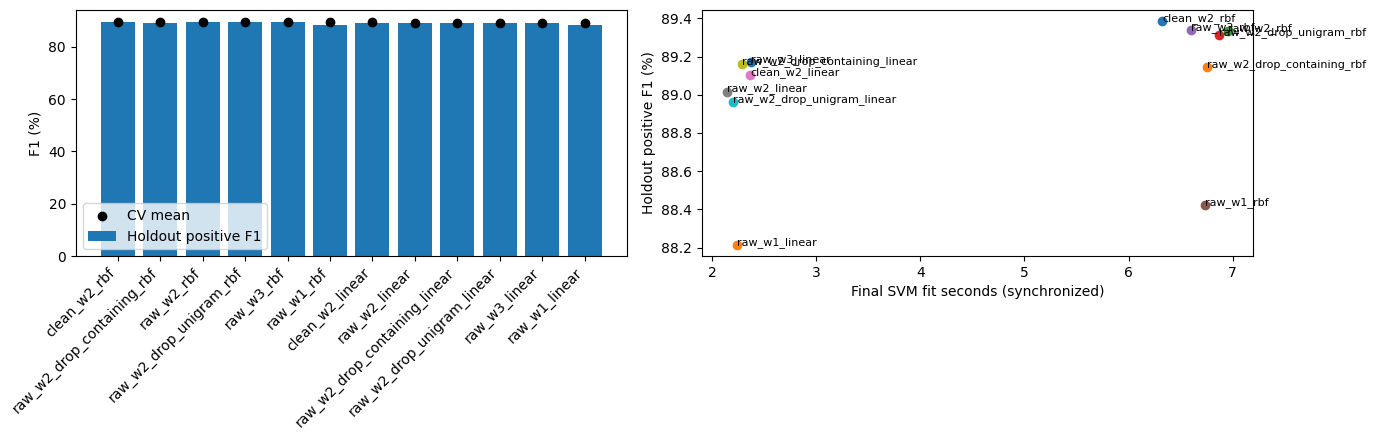

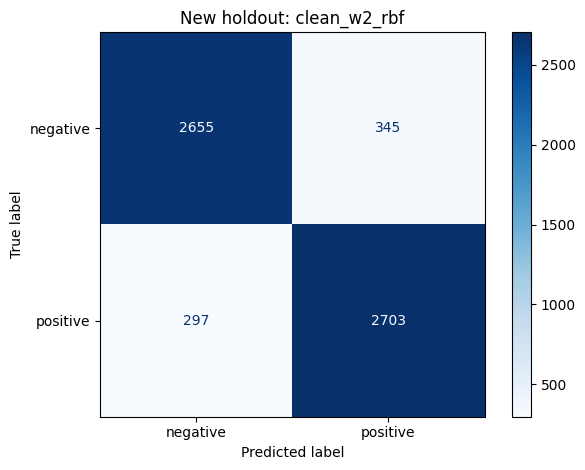

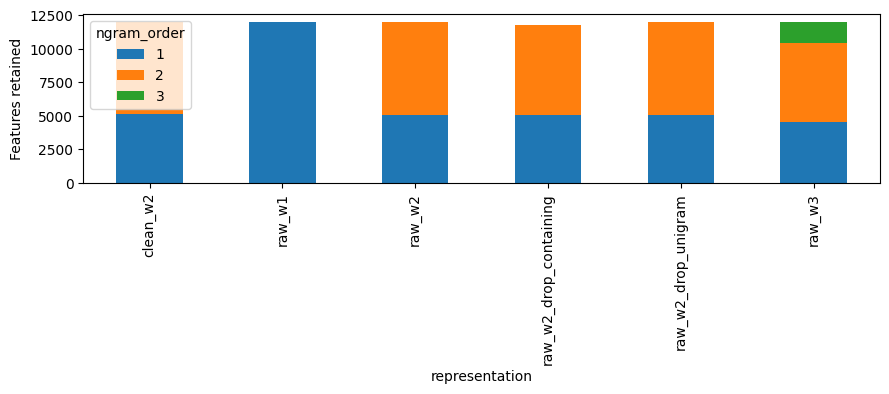

,representation,ngram_order,n_features,train_document_coverage,matrix_density
0,raw_w1,1,12000,1.00000,0.010741
1,raw_w1,2,0,0.00000,0.010741
2,raw_w1,3,0,0.00000,0.010741
3,raw_w2,1,5099,1.00000,0.016246
4,raw_w2,2,6901,0.99995,0.016246
5,raw_w2,3,0,0.00000,0.016246
6,raw_w3,1,4564,1.00000,0.016934
7,raw_w3,2,5865,0.99995,0.016934
8,raw_w3,3,1571,0.99090,0.016934
9,clean_w2,1,5139,1.00000,0.016200


,representation,phrase,in_vocabulary
0,raw_w1,not good,False
1,raw_w1,not worth watching,False
2,raw_w1,very good,False
3,raw_w1,a waste of,False
4,raw_w2,not good,True
5,raw_w2,not worth watching,False
6,raw_w2,very good,True
7,raw_w2,a waste of,False
8,raw_w3,not good,True
9,raw_w3,not worth watching,False


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
positions = np.arange(len(test_results))
axes[0].bar(positions, test_results.positive_f1 * 100, label="Holdout positive F1")
axes[0].scatter(positions, test_results.cv_positive_f1 * 100, color="black", label="CV mean")
axes[0].set_xticks(positions, test_results.experiment, rotation=45, ha="right")
axes[0].set_ylabel("F1 (%)"); axes[0].legend()
for _, row in test_results.iterrows():
    axes[1].scatter(row.fit_seconds, row.positive_f1 * 100)
    axes[1].annotate(row.experiment, (row.fit_seconds, row.positive_f1 * 100), fontsize=8)
axes[1].set_xlabel("Final SVM fit seconds (synchronized)")
axes[1].set_ylabel("Holdout positive F1 (%)")
fig.tight_layout(); fig.savefig(RUN_DIR / "performance_and_cost.png", dpi=180); plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, PREDICTIONS[CHAMPION], display_labels=["negative", "positive"], cmap="Blues")
plt.title(f"New holdout: {CHAMPION}"); plt.tight_layout()
plt.savefig(RUN_DIR / "champion_confusion_matrix.png", dpi=180); plt.show()
vocabulary.pivot(index="representation", columns="ngram_order", values="n_features").plot.bar(
    stacked=True, figsize=(9, 4), ylabel="Features retained")
plt.tight_layout(); plt.savefig(RUN_DIR / "vocabulary_composition.png", dpi=180); plt.show()
display(vocabulary)
display(pd.DataFrame(probe_rows))

## 10. Diagnostic theo nhóm và độ bất định của chênh lệch F1
Báo accuracy từng nhóm và tỷ lệ **cả hai câu trong cặp đều đúng**; chỉ đổi nhãn
chưa đủ vì có thể đổi sai. Development và locked báo riêng. Invariance chỉ có
nhãn positive trong suite này, nên coverage còn hạn chế.

Bootstrap dùng cùng các review cho cả hai model, lấy mẫu phân tầng theo nhãn.
CI chỉ phản ánh bất định từ holdout với các model đã fit, chưa gồm biến thiên
do retrain/seed. 

In [13]:
diagnostic_rows = []
for name, prediction in DIAGNOSTIC_PREDICTIONS.items():
    frame = diagnostics.copy()
    frame["correct"] = frame.label.to_numpy() == prediction
    for (split, group), part in frame.groupby(["split", "group"]):
        pair_correct = part.groupby("pair_id").correct.all()
        diagnostic_rows.append({"experiment": name, "split": split, "group": group,
                                "n_sentences": len(part), "n_pairs": len(pair_correct),
                                "accuracy": part.correct.mean(),
                                "both_in_pair_correct": pair_correct.mean()})
diagnostic_results = pd.DataFrame(diagnostic_rows)
diagnostic_results.to_csv(RUN_DIR / "diagnostic_group_results.csv", index=False)
display(diagnostic_results.loc[diagnostic_results.split == "locked"].pivot(
    index="group", columns="experiment", values="both_in_pair_correct"))

REFERENCE = "raw_w2_rbf"
bootstrap_rows = []
for name, prediction in PREDICTIONS.items():
    if name != REFERENCE:
        bootstrap_rows.append({"experiment": name, "reference": REFERENCE,
            **experiment.paired_f1_bootstrap(y_test, prediction, PREDICTIONS[REFERENCE],
                n_bootstrap=1000 if MODE == "full" else 100, seed=CONFIG["seed"])})
bootstrap_results = pd.DataFrame(bootstrap_rows)
bootstrap_results.to_csv(RUN_DIR / "paired_f1_bootstrap.csv", index=False)
display(bootstrap_results)

experiment,clean_w2_linear,clean_w2_rbf,raw_w1_linear,raw_w1_rbf,raw_w2_drop_containing_linear,raw_w2_drop_containing_rbf,raw_w2_drop_unigram_linear,raw_w2_drop_unigram_rbf,raw_w2_linear,raw_w2_rbf,raw_w3_linear,raw_w3_rbf
group,,,,,,,,,,,,
contrast_explicit_overall,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
local_negation,0.333333,0.333333,0.166667,0.166667,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333
longer_negation,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
name_invariance,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
reported_speech,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
typo_invariance,1.000000,1.000000,0.500000,0.500000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.500000,0.500000


,experiment,reference,delta_positive_f1,ci95_low,ci95_high,n_bootstrap
0,clean_w2_rbf,raw_w2_rbf,0.000520,-0.002541,0.003493,1000
1,raw_w2_drop_containing_rbf,raw_w2_rbf,-0.001874,-0.003841,0.000293,1000
2,raw_w2_drop_unigram_rbf,raw_w2_rbf,-0.000183,-0.001544,0.001385,1000
3,raw_w3_rbf,raw_w2_rbf,0.000049,-0.003207,0.003299,1000
4,raw_w1_rbf,raw_w2_rbf,-0.009129,-0.015246,-0.003380,1000
5,clean_w2_linear,raw_w2_rbf,-0.002318,-0.006298,0.001571,1000
6,raw_w2_linear,raw_w2_rbf,-0.003163,-0.006686,0.000463,1000
7,raw_w2_drop_containing_linear,raw_w2_rbf,-0.001743,-0.005264,0.001941,1000
8,raw_w2_drop_unigram_linear,raw_w2_rbf,-0.003710,-0.007307,0.000081,1000
9,raw_w3_linear,raw_w2_rbf,-0.001624,-0.006157,0.002822,1000


## 11. Review thật: các nhóm từ khóa và annotation thủ công
Keyword flags dưới đây chỉ là cách lọc sơ bộ, **không phải nhãn phủ định/mixed
sentiment được xác minh**. Để báo error rate theo hiện tượng ngôn ngữ, điền template
annotation từ một mẫu ngẫu nhiên có cả đúng và sai. Không chỉ đọc lỗi rồi suy ra
error rate của cả nhóm. File error riêng lưu toàn văn, ID, nhãn và margin.

Template: điền 0/1 cho bốn cột `negation`, `contrast`, `reported_speech`, `other`;
có thể nhiều tag. Chỉ tính thống kê thủ công khi toàn bộ mẫu đã được điền đủ.
Chỉ diễn giải thăm dò nếu số mẫu của nhóm ít. Giữ tập locked/holdout cho đánh giá;
nếu dùng lỗi để sửa phương pháp tiếp thì ghi nhận đã sử dụng phản hồi này.

In [14]:
flags = {
    "negation_keyword": test_df.text.str.contains(r"\b(?:not|never|no)\b|n't", case=False, regex=True),
    "contrast_keyword": test_df.text.str.contains(r"\b(?:but|however|although)\b", case=False, regex=True),
    "reported_speech_keyword": test_df.text.str.contains(r"\b(?:said|reviewers|others)\b", case=False, regex=True),
}
slice_rows = []
for name, prediction in PREDICTIONS.items():
    for group, mask in flags.items():
        mask = mask.to_numpy()
        if mask.any():
            slice_rows.append({"experiment": name, "keyword_flag": group,
                               "n": int(mask.sum()),
                               **experiment.scores(y_test[mask], prediction[mask])})
pd.DataFrame(slice_rows).to_csv(RUN_DIR / "keyword_slices_NOT_verified_tags.csv", index=False)

annotation_path = RUN_DIR / "manual_annotation_template.csv"
if not annotation_path.exists():
    template = test_df.sample(n=min(200, len(test_df)), random_state=CONFIG["seed"])[["sample_id", "text"]].copy()
    for tag in ("negation", "contrast", "reported_speech", "other", "notes"):
        template[tag] = ""
    template.to_csv(annotation_path, index=False)
print("Annotation template:", annotation_path)

if MANUAL_ANNOTATIONS_CSV:
    annotated = pd.read_csv(MANUAL_ANNOTATIONS_CSV)
    expected_ids = set(pd.read_csv(annotation_path).sample_id)
    if annotated.sample_id.duplicated().any() or set(annotated.sample_id) != expected_ids:
        raise ValueError("Annotations must contain each sampled ID exactly once")
    tag_columns = ["negation", "contrast", "reported_speech", "other"]
    if not annotated[tag_columns].isin([0, 1]).all().all():
        raise ValueError("Complete all tag columns with 0/1 before computing group errors")
    manual_rows = []
    aligned = test_df[["sample_id", "label"]].merge(annotated, on="sample_id", validate="one_to_one")
    lookup = {sample_id: i for i, sample_id in enumerate(test_df.sample_id)}
    indices = np.array([lookup[sample_id] for sample_id in aligned.sample_id])
    for name, prediction in PREDICTIONS.items():
        for tag in tag_columns:
            mask = aligned[tag].to_numpy() == 1
            if mask.any():
                manual_rows.append({"experiment": name, "tag": tag, "n": int(mask.sum()),
                    "error_rate": float(np.mean(prediction[indices[mask]] != aligned.label.to_numpy()[mask]))})
    pd.DataFrame(manual_rows).to_csv(RUN_DIR / "manual_tag_error_rates.csv", index=False)
    display(pd.DataFrame(manual_rows))

errors = test_df.copy()
errors["prediction"] = PREDICTIONS[CHAMPION]
errors = errors.loc[errors.label != errors.prediction]
print("Champion errors:", len(errors), "/", len(test_df))
with pd.option_context("display.max_colwidth", 500):
    display(errors[["sample_id", "label", "prediction", "text"]].head(5))

Annotation template: /kaggle/working/sentiment_svm/20261105T152007_994011Z/manual_annotation_template.csv
Champion errors: 642 / 6000


,sample_id,label,prediction,text
17,test:3808,0,1,"The fact that this movie is bargain basement quality is a real shame, but back in the 1940s, that was about the only type of film made for theaters catering to Black audiences due to segregation. So, while MGM, Warner and all the other big studios were making extremely polished films, tiny studios with shoestring budgets were left to muddle by with what they had. And from seeing this movie, it's obvious that a lot of energy went into making the film, even if it is a pretty lousy film aesthet..."
28,test:11409,0,1,"this show is pretty alright and fun to watch, its a great Disney channel shows and sometimes entertaining.<br /><br />I really enjoyed the first season but i hated the second and third seasons. This show has completely changed around. In the first season it was more about science and animals, all that is gone now in the season and third season. Its more about her life and dating. Ever since that gay kid (Ben) came along, this show has sucked. The writers took a perfectly good kid show and ch..."
50,test:11651,0,1,"It's not often I give two stars to a horror movie because horror is my favorite genre. A movie can be BAD in that it isn't a masterpiece but can be enjoyable on the basis of unintentional humour, bizarre characters, etc. A case in point are a great number of horror/sci-fiction movies from the 1940s to 1980s era. They are enjoyable for genre-buffs and guilty-pleasure seekers because their ""badness"" is entertaining. However, this movie has none of the humour or effective gory scenes of the ""Pi..."
55,test:21286,1,0,"Compared to the acclaimed Hollywood remake, this film is less flashy but much stronger at providing an overall picture of the drug problem. The remake loses the most interesting of the three plot threads, that of a farmer whose meager livelihood depends on drugs as a paying cash crop and whose increased involvement with the drug trade in an effort to better himself destroys himself and his family. Additionally, the story of the daughter's addiction goes into the problems not only of withdraw..."
64,test:6908,0,1,"As a true Canadian, I always avoid Canadian movies. However now and then I get trapped into watching one. This one is better than most, which is to say mediocre. It has many of the usual flaws of Canadian films...self-conscious acting...an excess of cinematic gimmicks and, above all, the self-effacing Canadian habit of using Canadian cities as stand-ins for American ones. I mean using the historic metropolis of Montreal as a stand in for Harrisburg Pennsylvania is just short of obscene. I wa..."


## 12. Demo nhập review và xuất model CPU


In [15]:
from sentiment_demo_runtime import load_model, predict_reviews

demo_entries, export_checks = [], {}
for result in refit_results:
    exported = result.get("cpu_demo_export")
    if not exported:
        continue
    name = result["experiment"]
    export_checks[name] = exported
    if exported["status"] == "verified":
        demo_entries.append({"experiment": name,
            "path": Path(exported["path"]).relative_to(RUN_DIR).as_posix(),
            "format": exported["format"],
            "holdout_positive_f1": result["evaluations"]["holdout"]["positive_f1"],
            "holdout_metric_backend": result["backend"],
            "cpu_verified_sentences": exported["verified_sentences"]})
if not any(entry["experiment"] == "raw_w2_linear" for entry in demo_entries):
    raise RuntimeError("Required CPU linear demo was not exported successfully")
available = [entry["experiment"] for entry in demo_entries]
DEFAULT_DEMO_MODEL = CHAMPION if CHAMPION in available else "raw_w2_linear"
demo_manifest = {"mode": MODE, "champion_selected_by_cv": CHAMPION,
                 "default_model": DEFAULT_DEMO_MODEL, "models": demo_entries,
                 "champion_available_on_cpu": CHAMPION in available,
                 "task": "English movie-review binary document sentiment"}
experiment.write_json(RUN_DIR / "demo_manifest.json", demo_manifest)
experiment.write_json(RUN_DIR / "cpu_export_checks.json", export_checks)
requirements = []
for package in ("numpy", "scipy", "scikit-learn", "joblib", "pandas"):
    requirements.append(f"{package}=={importlib.metadata.version(package)}")
requirements.append("streamlit>=1.40,<2")
(RUN_DIR / "requirements_demo.txt").write_text("\n".join(requirements) + "\n")
examples = ["A wonderful film with excellent acting and a moving story.",
            "The plot was boring and the ending was terrible.",
            "The movie was not good, although the music was impressive.",
            "The acting was excellent, but overall I disliked the film."]
pd.DataFrame({"text": examples}).to_csv(RUN_DIR / "demo_input_examples.csv", index=False)
entry = next(entry for entry in demo_entries if entry["experiment"] == DEFAULT_DEMO_MODEL)
demo_bundle = load_model(RUN_DIR / entry["path"])
demo_predictions = pd.DataFrame(predict_reviews(demo_bundle, examples))
demo_predictions.to_csv(RUN_DIR / "demo_example_predictions.csv", index=False)
print("CPU demo model:", DEFAULT_DEMO_MODEL, "| CV champion:", CHAMPION)
display(demo_predictions[["text", "sentiment", "decision_margin", "model"]])

if importlib.util.find_spec("ipywidgets") is not None:
    import ipywidgets as widgets
    demo_models = widgets.Dropdown(options=available, value=DEFAULT_DEMO_MODEL, description="Model:")
    demo_text = widgets.Textarea(value=examples[0], description="Review:",
                                layout=widgets.Layout(width="95%", height="120px"))
    demo_button = widgets.Button(description="Phân loại", button_style="primary")
    demo_output = widgets.Output()
    demo_cache = {DEFAULT_DEMO_MODEL: demo_bundle}
    def classify_review(_):
        with demo_output:
            demo_output.clear_output(wait=True)
            try:
                name = demo_models.value
                if name not in demo_cache:
                    selected_entry = next(item for item in demo_entries if item["experiment"] == name)
                    demo_cache[name] = load_model(RUN_DIR / selected_entry["path"])
                prediction = predict_reviews(demo_cache[name], [demo_text.value])[0]
                print(prediction["sentiment"].upper(), "| Model:", name)
                print(f"Decision margin: {prediction['decision_margin']:.4f} (không phải xác suất)")
                print("Features nhận diện:", prediction["recognized_features"])
            except Exception as error:
                print("Không thể dự đoán:", error)
    demo_button.on_click(classify_review)
    display(demo_models, demo_text, demo_button, demo_output)
else:
    print("Widget unavailable; exported CLI and Streamlit demo are still ready.")

CPU demo model: clean_w2_rbf | CV champion: clean_w2_rbf


,text,sentiment,decision_margin,model
0,A wonderful film with excellent acting and a m...,positive,1.686544,clean_w2_rbf
1,The plot was boring and the ending was terrible.,negative,-1.410795,clean_w2_rbf
2,"The movie was not good, although the music was...",negative,-0.124313,clean_w2_rbf
3,"The acting was excellent, but overall I dislik...",positive,0.819776,clean_w2_rbf


Dropdown(description='Model:', options=('clean_w2_rbf', 'raw_w2_linear'), value='clean_w2_rbf')

Textarea(value='A wonderful film with excellent acting and a moving story.', description='Review:', layout=Lay…

Button(button_style='primary', description='Phân loại', style=ButtonStyle())

Output()

## 13. Kết luận sau khi chạy và bộ file bàn giao
Chỉ viết kết luận sau khi có output mới:

1. **N-gram:** delta CV/holdout F1 từ unigram → bigram → trigram, vocabulary và
   coverage thực tế; giới hạn 12.000 features có khiến unigram bị thay thế không?
2. **Kernel:** linear/RBF khác nhau bao nhiêu về F1, train gap và chi phí?
3. **Ngôn ngữ:** nhóm diagnostic nào cải thiện, nhóm nào vẫn yếu? Có review tự
   nhiên/toàn văn nào hỗ trợ giải thích? Diagnostic template chưa chứng minh
   khả năng hiểu ngữ cảnh nói chung.
4. **Cleaning/vocabulary:** cải tiến có tác dụng không? Nếu không tăng thì báo
   trung thực. Cleaning chung chưa cho biết riêng HTML hay contraction đóng góp.
5. **Từ phổ biến:** movie/film có DF/IDF và hệ số linear như thế nào? Bỏ từ đơn
   khác bỏ cả cụm ra sao? Báo delta theo cùng kernel và CI; nếu CI chứa 0 thì
   chưa đủ bằng chứng cho một hướng cải thiện. IDF thấp không đồng nghĩa vô hại.
6. **Tính tin cậy:** có chênh train–CV/test không, shuffle control ra sao, có
   ứng viên trùng gần không? Không dùng một control để chứng nhận cả pipeline.


Tham khảo: [cuML SVC](https://docs.nvidia.com/cuml/latest/api/generated/cuml.svm.SVC/),
[Wang & Manning 2012](https://aclanthology.org/P12-2018/),
[CheckList 2020](https://aclanthology.org/2020.acl-main.442/).

In [16]:
# Save the standalone experiment source with the outputs.
REPLAY_NOTEBOOK_JSON = '{\n "cells": [\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "# IMDb sentiment: n-gram, Linear/RBF SVM và Kaggle 2 GPU\\n",\n    "\\n",\n    "**Ba câu hỏi:** (1) Bigram/trigram giúp gì so với unigram? (2) Kernel RBF có đáng\\n",\n    "chi phí so với kernel tuyến tính? (3) Các biểu diễn xử lý phủ định, tương phản và\\n",\n    "lời dẫn ra sao? Thêm ablation làm sạch HTML/contraction, từ phổ biến movie/film,\\n",\n    "tùy chọn vocabulary lớn và đối chứng xáo trộn nhãn để kiểm tra đánh giá.\\n",\n    "\\n",\n    "**Kaggle:** Settings → Accelerator → **GPU T4 x2**, bật Internet để tải IMDb.\\n",\n    "Ưu tiên **Always use latest environment**. Không giả định CuPy/cuML đã cài sẵn:\\n",\n    "notebook tự kiểm tra và cài GPU wheels trong môi trường worker riêng nếu thiếu.\\n",\n    "Notebook kiểm tra cả hai card và fit thử trên từng card trước khi chạy nghiên cứu.\\n",\n    "\\n",\n    "**Cách chạy song song:** hai Python subprocess, mỗi process có\\n",\n    "`CUDA_VISIBLE_DEVICES` riêng và chạy **cuML SVC**. Các fold/kernel được chia động\\n",\n    "giữa hai GPU. Mỗi fit sử dụng một GPU; bộ nhớ hai card không được cộng gộp.\\n",\n    "TF-IDF chạy CPU, fit riêng trong mỗi training fold và cache để các kernel dùng\\n",\n    "đúng cùng biểu diễn. Không dùng `GridSearchCV(n_jobs=-1)` để tranh cùng GPU.\\n",\n    "\\n",\n    "**Đối chứng tuyến tính là SVC(kernel=\'linear\'), không phải LinearSVC.** Cả hai\\n",\n    "kernel dùng cùng backend/loại solver. cuML có thể cho kết quả khác sklearn trong\\n",\n    "notebook cũ; phải chạy lại và báo kết quả mới, không ghép số cũ với số mới.\\n",\n    "\\n",\n    "Notebook mới chưa có kết quả thực nghiệm. Bản đã chạy được lưu riêng trong\\n",\n    "`output/archive/RBF_SVM_Sentiment_original_executed.ipynb` của project gốc.",\n    "\\nThis replay reproduces experiments/demo; automatic ZIP/source-copy steps are in the primary notebook.\\n"\n   ],\n   "id": "svm-kaggle-00"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 1. Kiểm tra dependency\\n",\n    "Ưu tiên GPU stack có sẵn nếu probe trong subprocess thành công. Nếu thiếu,\\n",\n    "tự nhận CUDA toolkit/driver rồi cài wheel cuML/CuPy đúng họ CUDA 12/13 vào venv\\n",\n    "riêng dưới `/kaggle/working/.svm_gpu_runtime`. Cài bằng đúng Python runtime hiện\\n",\n    "tại, kể cả Python 3.13; pip phải tìm được binary wheel tương thích.\\n",\n    "\\n",\n    "Worker giữ cùng scikit-learn/joblib với kernel để đọc vectorizer nhất quán,\\n",\n    "nhưng tự giải quyết NumPy/SciPy theo yêu cầu cuML. Không thay NumPy đã nạp trong\\n",\n    "kernel và không cần restart giữa Run All. Cần Internet. Nếu resolver/CUDA probe\\n",\n    "lỗi, dừng trước train và in log cài đặt; không chuyển sang CPU ngầm.\\n",\n    "\\n",\n    "Nguồn cài đặt: [RAPIDS](https://docs.nvidia.com/datascience/install/),\\n",\n    "[CuPy CUDA wheels](https://docs.cupy.dev/en/stable/install.html)."\n   ],\n   "id": "svm-kaggle-01"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "import importlib.util\\n",\n    "import subprocess\\n",\n    "import sys\\n",\n    "\\n",\n    "packages = {\\"datasets\\": \\"datasets\\", \\"sklearn\\": \\"scikit-learn\\", \\"pandas\\": \\"pandas\\",\\n",\n    "            \\"scipy\\": \\"scipy\\", \\"matplotlib\\": \\"matplotlib\\", \\"joblib\\": \\"joblib\\",\\n",\n    "            \\"ipywidgets\\": \\"ipywidgets\\"}\\n",\n    "missing = [package for module, package in packages.items()\\n",\n    "           if importlib.util.find_spec(module) is None]\\n",\n    "if missing:\\n",\n    "    subprocess.check_call([sys.executable, \\"-m\\", \\"pip\\", \\"install\\", \\"-q\\", *missing])\\n",\n    "\\n",\n    "BOOTSTRAP_SOURCE = \'\\"\\"\\"Prepare isolated GPU workers without replacing a running notebook\\\\\'s NumPy.\\"\\"\\"\\\\nimport hashlib\\\\nimport importlib.metadata\\\\nimport json\\\\nimport os\\\\nfrom pathlib import Path\\\\nimport re\\\\nimport subprocess\\\\nimport sys\\\\nimport venv\\\\n\\\\n\\\\nRAPIDS_RELEASE = \\"26.10.*\\"\\\\n\\\\n\\\\ndef choose_cuda_major(nvcc_output, nvidia_smi_output, override=None):\\\\n    \\"\\"\\"Prefer installed toolkit; nvidia-smi reports driver capability, not toolkit.\\"\\"\\"\\\\n    if override is not None:\\\\n        if str(override) not in {\\"12\\", \\"13\\"}:\\\\n            raise ValueError(\\"SVM_CUDA_MAJOR must be 12 or 13\\")\\\\n        return int(override), \\"explicit override\\"\\\\n    match = re.search(r\\"release\\\\\\\\s+(12|13)\\\\\\\\.\\\\\\\\d+\\", nvcc_output)\\\\n    if match:\\\\n        return int(match.group(1)), \\"installed nvcc toolkit\\"\\\\n    match = re.search(r\\"CUDA Version:\\\\\\\\s*(\\\\\\\\d+)\\\\\\\\.\\\\\\\\d+\\", nvidia_smi_output)\\\\n    if match and int(match.group(1)) >= 12:\\\\n        # CUDA component wheels provide the toolkit when nvcc is absent.\\\\n        return min(int(match.group(1)), 13), \\"driver capability + CUDA component wheels\\"\\\\n    raise RuntimeError(\\"Cannot detect supported CUDA 12/13. Check Kaggle GPU/driver settings.\\")\\\\n\\\\n\\\\ndef gpu_package_specs(major, sklearn_version, joblib_version):\\\\n    if major not in (12, 13):\\\\n        raise ValueError(\\"Only CUDA 12/13 wheels are supported\\")\\\\n    return [f\\"cuml-cu{major}=={RAPIDS_RELEASE}\\", f\\"cupy-cuda{major}x[ctk]\\",\\\\n            f\\"scikit-learn=={sklearn_version}\\", f\\"joblib=={joblib_version}\\"]\\\\n\\\\n\\\\nPROBE = r\\\\\'\\\\\'\\\\\'\\\\nimport json, sys\\\\nimport numpy, scipy, sklearn, joblib\\\\nimport cupy as cp\\\\nimport cuml\\\\nfrom cuml.svm import SVC\\\\ncount = cp.cuda.runtime.getDeviceCount()\\\\nif count < 2:\\\\n    raise RuntimeError(f\\"Need two visible GPUs, found {count}\\")\\\\nassert int(cp.arange(4, dtype=cp.int32).sum().get()) == 6\\\\nprint(json.dumps({\\"python\\":sys.executable,\\"python_version\\":sys.version,\\\\n                  \\"devices\\":count,\\"cupy\\":cp.__version__,\\"cuml\\":cuml.__version__,\\\\n                  \\"numpy\\":numpy.__version__,\\"scipy\\":scipy.__version__,\\\\n                  \\"sklearn\\":sklearn.__version__,\\"joblib\\":joblib.__version__}))\\\\n\\\\\'\\\\\'\\\\\'\\\\n\\\\n\\\\ndef runtime_environment(python):\\\\n    environment = os.environ.copy()\\\\n    if str(python) != sys.executable:\\\\n        environment.pop(\\"PYTHONPATH\\", None)\\\\n        environment.pop(\\"PYTHONHOME\\", None)\\\\n    return environment\\\\n\\\\n\\\\ndef probe_runtime(python, timeout=180):\\\\n    result = subprocess.run([str(python), \\"-c\\", PROBE], text=True,\\\\n                            capture_output=True, timeout=timeout, env=runtime_environment(python))\\\\n    if result.returncode:\\\\n        return None, (result.stdout + \\"\\\\\\\\n\\" + result.stderr).strip()\\\\n    for line in reversed(result.stdout.splitlines()):\\\\n        try:\\\\n            return json.loads(line), \\"\\"\\\\n        except json.JSONDecodeError:\\\\n            continue\\\\n    return None, \\"GPU probe produced no valid environment JSON: \\" + result.stdout\\\\n\\\\n\\\\ndef select_worker_python(root=None):\\\\n    \\"\\"\\"Reuse working host cuML, or install GPU wheels in a private Python venv.\\"\\"\\"\\\\n    try:\\\\n        inventory = subprocess.check_output(\\\\n            [\\"nvidia-smi\\", \\"--query-gpu=uuid,name\\", \\"--format=csv,noheader\\"],\\\\n            text=True, stderr=subprocess.STDOUT)\\\\n        smi = subprocess.check_output([\\"nvidia-smi\\"], text=True, stderr=subprocess.STDOUT)\\\\n    except (FileNotFoundError, subprocess.CalledProcessError) as error:\\\\n        raise RuntimeError(\\"No working NVIDIA GPU runtime. Select GPU T4 x2 on Kaggle first.\\") from error\\\\n    rows = [line for line in inventory.splitlines() if line.strip()]\\\\n    visible = os.environ.get(\\"CUDA_VISIBLE_DEVICES\\", \\"\\").strip()\\\\n    if len(rows) < 2 or visible == \\"-1\\" or (visible and len(visible.split(\\",\\")) < 2):\\\\n        raise RuntimeError(\\"This notebook needs two visible GPUs. Select Kaggle GPU T4 x2.\\")\\\\n    print(\\"GPU inventory:\\\\\\\\n\\" + inventory, flush=True)\\\\n    print(\\"Notebook Python:\\", sys.version, flush=True)\\\\n    host_info, host_error = probe_runtime(sys.executable)\\\\n    if host_info is not None:\\\\n        print(\\"Existing GPU runtime passed:\\", json.dumps(host_info), flush=True)\\\\n        return sys.executable, {\\"mode\\": \\"existing\\", \\"environment\\": host_info}\\\\n    print(\\"Existing GPU stack unavailable; preparing isolated workers.\\\\\\\\n\\" + host_error[-2000:], flush=True)\\\\n    try:\\\\n        nvcc = subprocess.check_output([\\"nvcc\\", \\"--version\\"], text=True, stderr=subprocess.STDOUT)\\\\n    except (FileNotFoundError, subprocess.CalledProcessError):\\\\n        nvcc = \\"\\"\\\\n    major, reason = choose_cuda_major(nvcc, smi, os.environ.get(\\"SVM_CUDA_MAJOR\\"))\\\\n    sklearn_version = importlib.metadata.version(\\"scikit-learn\\")\\\\n    joblib_version = importlib.metadata.version(\\"joblib\\")\\\\n    packages = gpu_package_specs(major, sklearn_version, joblib_version)\\\\n    identity = {\\"python\\": list(sys.version_info[:2]), \\"packages\\": packages}\\\\n    suffix = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:10]\\\\n    root = Path(root) if root else Path(\\"/kaggle/working/.svm_gpu_runtime\\")\\\\n    prefix = root / f\\"cuda{major}_py{sys.version_info.major}{sys.version_info.minor}_{suffix}\\"\\\\n    python = prefix / \\"bin\\" / \\"python\\"\\\\n    print(f\\"CUDA {major} selected from {reason}; worker environment: {prefix}\\", flush=True)\\\\n    if python.exists():\\\\n        info, _ = probe_runtime(python)\\\\n        if info is not None:\\\\n            return str(python), {\\"mode\\": \\"cached_isolated\\", \\"environment\\": info,\\\\n                                 \\"cuda_major\\": major, \\"selection_reason\\": reason,\\\\n                                 \\"requested_packages\\": packages}\\\\n    prefix.parent.mkdir(parents=True, exist_ok=True)\\\\n    if not python.exists():\\\\n        venv.EnvBuilder(with_pip=True, system_site_packages=False).create(prefix)\\\\n    command = [str(python), \\"-m\\", \\"pip\\", \\"install\\", \\"--no-cache-dir\\",\\\\n               \\"--only-binary=:all:\\", \\"--extra-index-url\\", \\"https://pypi.nvidia.com\\", *packages]\\\\n    print(\\"Installing GPU wheels; the notebook kernel\\\\\'s scientific packages stay unchanged.\\", flush=True)\\\\n    try:\\\\n        subprocess.run(command, check=True, env=runtime_environment(python))\\\\n    except subprocess.CalledProcessError as error:\\\\n        raise RuntimeError(\\\\n            f\\"GPU package installation failed for Python {sys.version_info.major}.{sys.version_info.minor} \\"\\\\n            f\\"and CUDA {major}. Check Internet and the pip resolver output above. \\"\\\\n            \\"No training has started and no CPU fallback was used.\\") from error\\\\n    info, diagnostic = probe_runtime(python)\\\\n    if info is None:\\\\n        raise RuntimeError(\\"GPU dependencies installed but CUDA probe failed:\\\\\\\\n\\" + diagnostic)\\\\n    metadata = {\\"mode\\": \\"installed_isolated\\", \\"environment\\": info, \\"cuda_major\\": major,\\\\n                \\"selection_reason\\": reason, \\"requested_packages\\": packages}\\\\n    (prefix / \\"runtime_state.json\\").write_text(json.dumps(metadata, indent=2))\\\\n    print(\\"GPU worker runtime passed:\\", json.dumps(info), flush=True)\\\\n    return str(python), metadata\\\\n\'\\n",\n    "bootstrap_namespace = {\'__name__\': \'kaggle_gpu_bootstrap\'}\\n",\n    "exec(compile(BOOTSTRAP_SOURCE, \'kaggle_gpu_bootstrap.py\', \'exec\'), bootstrap_namespace)\\n",\n    "WORKER_PYTHON, GPU_BOOTSTRAP_INFO = bootstrap_namespace[\'select_worker_python\']()\\n",\n    "print(\'Worker Python:\', WORKER_PYTHON)"\n   ],\n   "id": "svm-kaggle-02"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 2. Cấu hình nghiên cứu\\n",\n    "`full`: 20.000 train, 6.000 holdout mới, 3-fold, grid C/gamma như thí nghiệm cũ.\\n",\n    "`smoke`: dữ liệu nhỏ, một C/gamma, để kiểm tra luồng trước.\\n",\n    "Không dùng kết quả smoke làm kết quả cuối kì. Bộ nền có 8 nhóm:\\n",\n    "3 n-gram × 2 kernel + cleaning × 2 kernel.\\n",\n    "Bật `RUN_VOCAB_ABLATION` để thêm bigram 30.000 features × 2 kernel.\\n",\n    "Mặc định thêm hai ablation movie/film × hai kernel (tổng cộng 12 nhóm).\\n",\n    "`RUN_MAX_DF_ABLATION` thêm phép loại feature có DF > 80% trong training fold.\\n",\n    "\\n",\n    "Mỗi run tạo thư mục riêng. Có thể điền `RESUME_RUN_DIR` để tiếp tục đúng run đã\\n",\n    "ngắt trong cùng session/storage; config phải trùng. Cần tải/Save Version các output\\n",\n    "trước khi Kaggle xóa session. Nếu kernel bị kill cứng, chỉ xóa file `.running`\\n",\n    "của stage sau khi chắc chắn mọi worker cũ đã dừng."\n   ],\n   "id": "svm-kaggle-03"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "import csv\\n",\n    "from datetime import datetime, timezone\\n",\n    "import hashlib\\n",\n    "import importlib.metadata\\n",\n    "import json\\n",\n    "import os\\n",\n    "from pathlib import Path\\n",\n    "import re\\n",\n    "import sys\\n",\n    "import time\\n",\n    "\\n",\n    "import joblib\\n",\n    "import numpy as np\\n",\n    "import pandas as pd\\n",\n    "import matplotlib.pyplot as plt\\n",\n    "from IPython.display import display\\n",\n    "from sklearn.model_selection import StratifiedKFold\\n",\n    "from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score\\n",\n    "\\n",\n    "MODE = \\"full\\"                       # Change to \\"smoke\\" for the first trial.\\n",\n    "RUN_CLEANING_ABLATION = True\\n",\n    "RUN_VOCAB_ABLATION = False\\n",\n    "RUN_COMMON_WORD_ABLATION = True\\n",\n    "RUN_MAX_DF_ABLATION = False\\n",\n    "RUN_LABEL_SHUFFLE_CONTROL = True\\n",\n    "RUN_NEAR_DUPLICATE_AUDIT = True\\n",\n    "REQUIRE_TWO_GPUS = True\\n",\n    "RESUME_RUN_DIR = None                # e.g. \\"/kaggle/working/sentiment_svm/<run>\\"\\n",\n    "LOCAL_DATASET_DIR = None             # Optional DatasetDict saved with save_to_disk.\\n",\n    "DATASET_REVISION = \\"main\\"            # Resolved to a commit SHA before loading.\\n",\n    "MANUAL_ANNOTATIONS_CSV = None        # Optional completed annotation template.\\n",\n    "\\n",\n    "assert MODE in {\\"full\\", \\"smoke\\"}\\n",\n    "CONFIG = {\\n",\n    "    \\"mode\\": MODE, \\"seed\\": 42, \\"backend\\": \\"cuml\\", \\"tol\\": 1e-3,\\n",\n    "    \\"worker_python\\": WORKER_PYTHON,\\n",\n    "    \\"n_train_per_class\\": 10000 if MODE == \\"full\\" else 200,\\n",\n    "    \\"n_test_per_class\\": 3000 if MODE == \\"full\\" else 100,\\n",\n    "    \\"n_folds\\": 3 if MODE == \\"full\\" else 2,\\n",\n    "    \\"C_grid\\": [0.5, 2, 8] if MODE == \\"full\\" else [2],\\n",\n    "    \\"gamma_grid\\": [\\"scale\\", 0.1, 1] if MODE == \\"full\\" else [1],\\n",\n    "    \\"kernel_cache_mb\\": 512, \\"predict_batch_size\\": 512,\\n",\n    "    \\"cleaning_ablation\\": RUN_CLEANING_ABLATION,\\n",\n    "    \\"vocab_ablation\\": RUN_VOCAB_ABLATION,\\n",\n    "    \\"common_word_ablation\\": RUN_COMMON_WORD_ABLATION,\\n",\n    "    \\"max_df_ablation\\": RUN_MAX_DF_ABLATION,\\n",\n    "    \\"label_shuffle_control\\": RUN_LABEL_SHUFFLE_CONTROL,\\n",\n    "    \\"near_duplicate_audit\\": RUN_NEAR_DUPLICATE_AUDIT,\\n",\n    "    \\"near_duplicate_cosine_threshold\\": 0.98,\\n",\n    "    \\"local_dataset_dir\\": LOCAL_DATASET_DIR, \\"dataset_revision\\": DATASET_REVISION,\\n",\n    "    \\"notebook_build_sha\\": \\"9990f1573d29ed7f0422d640ea3add3a2b2bd06ba241d93dc31dfcd63f472ba1\\",\\n",\n    "}\\n",\n    "OUTPUT_ROOT = (Path(\\"/kaggle/working/sentiment_svm\\") if Path(\\"/kaggle/working\\").exists()\\n",\n    "               else Path.cwd() / \\"output\\" / \\"kaggle_runs\\")\\n",\n    "RUN_DIR = (Path(RESUME_RUN_DIR) if RESUME_RUN_DIR else\\n",\n    "           OUTPUT_ROOT / datetime.now(timezone.utc).strftime(\\"%Y%m%dT%H%M%S_%fZ\\"))\\n",\n    "RUN_DIR.mkdir(parents=True, exist_ok=True)\\n",\n    "SPECS = [{\\"id\\": f\\"raw_w{n}\\", \\"max_ngram\\": n, \\"max_features\\": 12000,\\n",\n    "          \\"min_df\\": 2, \\"clean\\": False} for n in (1, 2, 3)]\\n",\n    "if RUN_CLEANING_ABLATION:\\n",\n    "    SPECS.append({\\"id\\": \\"clean_w2\\", \\"max_ngram\\": 2, \\"max_features\\": 12000,\\n",\n    "                  \\"min_df\\": 2, \\"clean\\": True})\\n",\n    "if RUN_VOCAB_ABLATION:\\n",\n    "    SPECS.append({\\"id\\": \\"raw_w2_30k\\", \\"max_ngram\\": 2, \\"max_features\\": 30000,\\n",\n    "                  \\"min_df\\": 2, \\"clean\\": False})\\n",\n    "if RUN_COMMON_WORD_ABLATION:\\n",\n    "    for mode in (\\"unigram\\", \\"containing\\"):\\n",\n    "        SPECS.append({\\"id\\": f\\"raw_w2_drop_{mode}\\", \\"max_ngram\\": 2,\\n",\n    "                      \\"max_features\\": 12000, \\"min_df\\": 2, \\"clean\\": False,\\n",\n    "                      \\"drop_terms\\": [\\"movie\\", \\"film\\"], \\"drop_mode\\": mode})\\n",\n    "if RUN_MAX_DF_ABLATION:\\n",\n    "    SPECS.append({\\"id\\": \\"raw_w2_df80\\", \\"max_ngram\\": 2, \\"max_features\\": 12000,\\n",\n    "                  \\"min_df\\": 2, \\"clean\\": False, \\"drop_above_df\\": 0.8})\\n",\n    "CONFIG[\\"representations\\"] = SPECS\\n",\n    "config_path = RUN_DIR / \\"config.json\\"\\n",\n    "if config_path.exists() and json.loads(config_path.read_text()) != CONFIG:\\n",\n    "    raise ValueError(\\"Resume config/build differs. Restore the original config or start a new run.\\")\\n",\n    "config_path.write_text(json.dumps(CONFIG, indent=2), encoding=\\"utf-8\\")\\n",\n    "print(\\"RUN_DIR:\\", RUN_DIR)\\n",\n    "display(pd.DataFrame(SPECS))"\n   ],\n   "id": "svm-kaggle-04"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 3. Worker tự chứa trong notebook\\n",\n    "Cell này ghi module worker vào output để subprocess import được trong Kaggle.\\n",\n    "Không cần upload thêm file `.py`. CUDA chỉ được khởi tạo trong worker sau khi đã\\n",\n    "gắn GPU. Dense float32 dùng cho SVC để tương thích API cuML qua các phiên bản;\\n",\n    "ma trận sparse chỉ được chuyển dense trên GPU, có kiểm tra bộ nhớ và predict batch.\\n",\n    "Giảm `max_features`/sample size nếu GPU báo thiếu bộ nhớ; không âm thầm đổi mô hình."\n   ],\n   "id": "svm-kaggle-05"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "WORKER_SOURCE = r\'\'\'\\n",\n    "\\"\\"\\"Experiment helpers embedded verbatim in the standalone Kaggle notebook.\\n",\n    "\\n",\n    "CUDA libraries are imported only inside isolated worker processes. The explicit\\n",\n    "sklearn_test backend exists for local integration tests, not GPU benchmarking.\\n",\n    "\\"\\"\\"\\n",\n    "\\n",\n    "import argparse\\n",\n    "import csv\\n",\n    "import gc\\n",\n    "import hashlib\\n",\n    "import json\\n",\n    "import os\\n",\n    "from pathlib import Path\\n",\n    "import subprocess\\n",\n    "import sys\\n",\n    "import time\\n",\n    "import traceback\\n",\n    "import zipfile\\n",\n    "\\n",\n    "import joblib\\n",\n    "import numpy as np\\n",\n    "from scipy import sparse\\n",\n    "from sklearn.feature_extraction.text import TfidfVectorizer\\n",\n    "from sklearn.metrics import (\\n",\n    "    accuracy_score, classification_report, confusion_matrix, f1_score,\\n",\n    "    precision_score, recall_score,\\n",\n    ")\\n",\n    "from sklearn.preprocessing import normalize\\n",\n    "\\n",\n    "\\n",\n    "def feature_keep_indices(vectorizer, train_matrix, spec):\\n",\n    "    \\"\\"\\"Ablate existing columns, never rejoin tokens or refill the vocabulary.\\"\\"\\"\\n",\n    "    names = vectorizer.get_feature_names_out()\\n",\n    "    keep = np.ones(len(names), dtype=bool)\\n",\n    "    terms = set(spec.get(\\"drop_terms\\", []))\\n",\n    "    mode = spec.get(\\"drop_mode\\")\\n",\n    "    if mode == \\"unigram\\":\\n",\n    "        keep &= np.array([name not in terms for name in names])\\n",\n    "    elif mode == \\"containing\\":\\n",\n    "        keep &= np.array([not terms.intersection(name.split()) for name in names])\\n",\n    "    elif mode is not None:\\n",\n    "        raise ValueError(f\\"Unknown drop_mode: {mode}\\")\\n",\n    "    if \\"drop_above_df\\" in spec:\\n",\n    "        # Learned only from the current training fold, including for CV.\\n",\n    "        df = train_matrix.getnnz(axis=0) / train_matrix.shape[0]\\n",\n    "        keep &= df <= spec[\\"drop_above_df\\"]\\n",\n    "    indices = np.flatnonzero(keep)\\n",\n    "    if not len(indices):\\n",\n    "        raise ValueError(\\"Feature filtering removed the entire vocabulary\\")\\n",\n    "    return indices\\n",\n    "\\n",\n    "\\n",\n    "def filter_features(matrix, indices):\\n",\n    "    if len(indices) == matrix.shape[1] and np.array_equal(indices, np.arange(matrix.shape[1])):\\n",\n    "        result = matrix.tocsr(copy=True)\\n",\n    "        result.sort_indices()\\n",\n    "        return result\\n",\n    "    matrix = matrix[:, indices].tocsr(copy=True)\\n",\n    "    # Removing coordinates changes vector length; restore the L2 convention.\\n",\n    "    matrix = normalize(matrix, norm=\\"l2\\", copy=False)\\n",\n    "    matrix.sort_indices()\\n",\n    "    return matrix\\n",\n    "\\n",\n    "\\n",\n    "def transform_bundle_features(bundle, preprocessed_texts):\\n",\n    "    \\"\\"\\"Apply vectorizer AND stored feature mask; caller applies spec cleaning.\\"\\"\\"\\n",\n    "    matrix = bundle[\\"vectorizer\\"].transform(preprocessed_texts).tocsr()\\n",\n    "    indices = bundle.get(\\"feature_keep_indices\\", list(range(matrix.shape[1])))\\n",\n    "    return filter_features(matrix, indices)\\n",\n    "\\n",\n    "\\n",\n    "def write_json(path, value):\\n",\n    "    path = Path(path)\\n",\n    "    path.parent.mkdir(parents=True, exist_ok=True)\\n",\n    "    temporary = path.with_suffix(path.suffix + \\".tmp\\")\\n",\n    "    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False,\\n",\n    "                                     allow_nan=False), encoding=\\"utf-8\\")\\n",\n    "    temporary.replace(path)\\n",\n    "\\n",\n    "\\n",\n    "def digest(value):\\n",\n    "    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()[:16]\\n",\n    "\\n",\n    "\\n",\n    "def vectorizer_for(spec):\\n",\n    "    return TfidfVectorizer(\\n",\n    "        ngram_range=(1, spec[\\"max_ngram\\"]), min_df=spec.get(\\"min_df\\", 2),\\n",\n    "        max_features=spec[\\"max_features\\"], sublinear_tf=True,\\n",\n    "        lowercase=True, stop_words=None, dtype=np.float32,\\n",\n    "    )\\n",\n    "\\n",\n    "\\n",\n    "def prepare_features(directory, key, spec, train_text, evaluations, y_train):\\n",\n    "    \\"\\"\\"Fit on this training partition ONLY; evaluations never affect vocabulary.\\"\\"\\"\\n",\n    "    directory = Path(directory)\\n",\n    "    directory.mkdir(parents=True, exist_ok=True)\\n",\n    "    vectorizer = vectorizer_for(spec)\\n",\n    "    start = time.perf_counter()\\n",\n    "    train_base = vectorizer.fit_transform(train_text).tocsr()\\n",\n    "    if len(y_train) != train_base.shape[0]:\\n",\n    "        raise ValueError(\\"Training feature/label row count mismatch\\")\\n",\n    "    indices = feature_keep_indices(vectorizer, train_base, spec)\\n",\n    "    train = filter_features(train_base, indices)\\n",\n    "    fit_seconds = time.perf_counter() - start\\n",\n    "    train_path = directory / f\\"{key}_train.npz\\"\\n",\n    "    sparse.save_npz(train_path, train, compressed=False)\\n",\n    "    y_path = directory / f\\"{key}_y.npy\\"\\n",\n    "    np.save(y_path, np.asarray(y_train, dtype=np.int32))\\n",\n    "    vectorizer_path = directory / f\\"{key}_vectorizer.joblib\\"\\n",\n    "    joblib.dump(vectorizer, vectorizer_path)\\n",\n    "    evaluation_paths = {}\\n",\n    "    for name, texts in evaluations.items():\\n",\n    "        start = time.perf_counter()\\n",\n    "        matrix = filter_features(vectorizer.transform(texts), indices)\\n",\n    "        path = directory / f\\"{key}_{name}.npz\\"\\n",\n    "        sparse.save_npz(path, matrix, compressed=False)\\n",\n    "        evaluation_paths[name] = {\\n",\n    "            \\"matrix\\": str(path.resolve()),\\n",\n    "            \\"tfidf_transform_seconds\\": time.perf_counter() - start,\\n",\n    "        }\\n",\n    "    reference = {\\n",\n    "        \\"train\\": str(train_path.resolve()), \\"y_train\\": str(y_path.resolve()),\\n",\n    "        \\"vectorizer\\": str(vectorizer_path.resolve()), \\"evaluations\\": evaluation_paths,\\n",\n    "        \\"n_features\\": int(train.shape[1]), \\"tfidf_fit_seconds\\": fit_seconds,\\n",\n    "        \\"base_n_features\\": int(train_base.shape[1]),\\n",\n    "        \\"feature_keep_indices\\": indices.tolist(),\\n",\n    "        \\"removed_features\\": vectorizer.get_feature_names_out()[\\n",\n    "            np.setdiff1d(np.arange(train_base.shape[1]), indices)].tolist(),\\n",\n    "    }\\n",\n    "    return reference, vectorizer, train\\n",\n    "\\n",\n    "\\n",\n    "def vocabulary_audit(vectorizer, matrix, spec_id, keep_indices=None):\\n",\n    "    all_names = vectorizer.get_feature_names_out()\\n",\n    "    names = all_names if keep_indices is None else all_names[keep_indices]\\n",\n    "    orders = np.array([name.count(\\" \\") + 1 for name in names])\\n",\n    "    rows = []\\n",\n    "    for order in (1, 2, 3):\\n",\n    "        selected = np.flatnonzero(orders == order)\\n",\n    "        coverage = (float(np.mean(matrix[:, selected].getnnz(axis=1) > 0))\\n",\n    "                    if len(selected) else 0.0)\\n",\n    "        rows.append({\\"representation\\": spec_id, \\"ngram_order\\": order,\\n",\n    "                     \\"n_features\\": int(len(selected)),\\n",\n    "                     \\"train_document_coverage\\": coverage,\\n",\n    "                     \\"matrix_density\\": matrix.nnz / np.prod(matrix.shape)})\\n",\n    "    probes = [\\"not good\\", \\"not worth watching\\", \\"very good\\", \\"a waste of\\"]\\n",\n    "    retained_names = set(names)\\n",\n    "    presence = [{\\"representation\\": spec_id, \\"phrase\\": p,\\n",\n    "                 \\"in_vocabulary\\": p in retained_names} for p in probes]\\n",\n    "    return rows, presence\\n",\n    "\\n",\n    "\\n",\n    "def common_term_statistics(vectorizer, base_matrix, y, spec_id, keep_indices):\\n",\n    "    \\"\\"\\"Training-only DF/IDF and normalized TF-IDF, including movie/film.\\"\\"\\"\\n",\n    "    names = vectorizer.get_feature_names_out()\\n",\n    "    keep = set(keep_indices)\\n",\n    "    df = base_matrix.getnnz(axis=0)\\n",\n    "    unigram_indices = [i for i, name in enumerate(names) if \\" \\" not in name]\\n",\n    "    frequent = sorted(unigram_indices, key=lambda i: (-int(df[i]), names[i]))[:20]\\n",\n    "    requested = list(dict.fromkeys([\\"movie\\", \\"film\\", \\"not\\", \\"good\\", \\"bad\\", \\"boring\\",\\n",\n    "                                   \\"excellent\\"] + [names[i] for i in frequent]))\\n",\n    "    rows = []\\n",\n    "    y = np.asarray(y)\\n",\n    "    csc = base_matrix.tocsc()\\n",\n    "    for term in requested:\\n",\n    "        index = vectorizer.vocabulary_.get(term)\\n",\n    "        row = {\\"representation\\": spec_id, \\"term\\": term,\\n",\n    "               \\"in_base_vocabulary\\": index is not None,\\n",\n    "               \\"retained_by_model\\": index is not None and index in keep}\\n",\n    "        if index is not None:\\n",\n    "            column = csc[:, index]\\n",\n    "            row.update({\\n",\n    "                \\"train_document_frequency\\": int(df[index]),\\n",\n    "                \\"train_document_fraction\\": float(df[index] / len(y)),\\n",\n    "                \\"idf\\": float(vectorizer.idf_[index]),\\n",\n    "                \\"mean_base_l2_tfidf_all_documents\\": float(column.sum() / len(y)),\\n",\n    "                \\"mean_base_l2_tfidf_when_present\\": float(column.sum() / max(1, df[index])),\\n",\n    "                \\"document_fraction_negative\\": float(column[y == 0].getnnz() / np.sum(y == 0)),\\n",\n    "                \\"document_fraction_positive\\": float(column[y == 1].getnnz() / np.sum(y == 1)),\\n",\n    "            })\\n",\n    "        rows.append(row)\\n",\n    "    return rows\\n",\n    "\\n",\n    "\\n",\n    "def diagnostic_cases():\\n",\n    "    \\"\\"\\"144 template-authored sentences, 72 pairs; provisional labels, not IMDb.\\"\\"\\"\\n",\n    "    rows = []\\n",\n    "    for target_index, target in enumerate((\\"film\\", \\"movie\\", \\"story\\", \\"performance\\")):\\n",\n    "        for adjective_index, (positive, negative) in enumerate((\\n",\n    "                (\\"good\\", \\"bad\\"), (\\"enjoyable\\", \\"boring\\"),\\n",\n    "                (\\"impressive\\", \\"disappointing\\"))):\\n",\n    "            cases = {\\n",\n    "                \\"local_negation\\": (\\n",\n    "                    (f\\"The {target} was {positive}.\\", 1),\\n",\n    "                    (f\\"The {target} was not {positive}.\\", 0)),\\n",\n    "                \\"longer_negation\\": (\\n",\n    "                    (f\\"I think the {target} was {positive}.\\", 1),\\n",\n    "                    (f\\"I do not think the {target} was {positive}.\\", 0)),\\n",\n    "                \\"contrast_explicit_overall\\": (\\n",\n    "                    (f\\"Some parts of the {target} were {negative}, but overall I liked it.\\", 1),\\n",\n    "                    (f\\"Some parts of the {target} were {positive}, but overall I disliked it.\\", 0)),\\n",\n    "                \\"reported_speech\\": (\\n",\n    "                    (f\\"Others said the {target} was {negative}, but I disagree: \\"\\n",\n    "                     f\\"I found it {positive}.\\", 1),\\n",\n    "                    (f\\"Others said the {target} was {positive}, but I disagree: \\"\\n",\n    "                     f\\"I found it {negative}.\\", 0)),\\n",\n    "                \\"typo_invariance\\": (\\n",\n    "                    (f\\"The {target} was {positive}.\\", 1),\\n",\n    "                    (f\\"The {target} was {positive[:-1] + positive[-1] * 2}.\\", 1)),\\n",\n    "                \\"name_invariance\\": (\\n",\n    "                    (f\\"The {target} called Orion was {positive}.\\", 1),\\n",\n    "                    (f\\"The {target} called Vega was {positive}.\\", 1)),\\n",\n    "            }\\n",\n    "            for group, pair in cases.items():\\n",\n    "                pair_id = f\\"{group}_{target_index}_{adjective_index}\\"\\n",\n    "                for position, (text, label) in enumerate(pair):\\n",\n    "                    rows.append({\\"case_id\\": f\\"{pair_id}_{position}\\", \\"pair_id\\": pair_id,\\n",\n    "                                 \\"group\\": group, \\"position\\": position,\\n",\n    "                                 \\"split\\": \\"development\\" if target_index < 2 else \\"locked\\",\\n",\n    "                                 \\"text\\": text, \\"label\\": label,\\n",\n    "                                 \\"label_status\\": \\"template_expected_review_required\\"})\\n",\n    "    return rows\\n",\n    "\\n",\n    "\\n",\n    "def paired_f1_bootstrap(y, first, reference, n_bootstrap=1000, seed=42):\\n",\n    "    \\"\\"\\"Paired, class-stratified percentile CI, conditional on fitted models.\\"\\"\\"\\n",\n    "    y, first, reference = map(np.asarray, (y, first, reference))\\n",\n    "    if not (len(y) == len(first) == len(reference)):\\n",\n    "        raise ValueError(\\"Paired predictions must have identical lengths and row order\\")\\n",\n    "    groups = [np.flatnonzero(y == label) for label in (0, 1)]\\n",\n    "    if any(len(group) == 0 for group in groups):\\n",\n    "        raise ValueError(\\"Bootstrap requires both classes\\")\\n",\n    "\\n",\n    "    def fast_f1(labels, prediction):\\n",\n    "        true_positive = np.sum((labels == 1) & (prediction == 1))\\n",\n    "        denominator = np.sum(labels == 1) + np.sum(prediction == 1)\\n",\n    "        return float(2 * true_positive / denominator) if denominator else 0.0\\n",\n    "\\n",\n    "    rng = np.random.default_rng(seed)\\n",\n    "    deltas = []\\n",\n    "    for _ in range(n_bootstrap):\\n",\n    "        indices = np.concatenate([rng.choice(group, len(group), replace=True)\\n",\n    "                                  for group in groups])\\n",\n    "        deltas.append(fast_f1(y[indices], first[indices])\\n",\n    "                      - fast_f1(y[indices], reference[indices]))\\n",\n    "    low, high = np.quantile(deltas, [.025, .975])\\n",\n    "    return {\\"delta_positive_f1\\": fast_f1(y, first) - fast_f1(y, reference),\\n",\n    "            \\"ci95_low\\": float(low), \\"ci95_high\\": float(high),\\n",\n    "            \\"n_bootstrap\\": n_bootstrap}\\n",\n    "\\n",\n    "\\n",\n    "def scores(y, pred):\\n",\n    "    return {\\n",\n    "        \\"accuracy\\": float(accuracy_score(y, pred)),\\n",\n    "        \\"positive_precision\\": float(precision_score(y, pred, zero_division=0)),\\n",\n    "        \\"positive_recall\\": float(recall_score(y, pred, zero_division=0)),\\n",\n    "        \\"positive_f1\\": float(f1_score(y, pred, zero_division=0)),\\n",\n    "        \\"macro_f1\\": float(f1_score(y, pred, labels=[0, 1], average=\\"macro\\", zero_division=0)),\\n",\n    "    }\\n",\n    "\\n",\n    "\\n",\n    "class Runtime:\\n",\n    "    def __init__(self, backend):\\n",\n    "        self.backend = backend\\n",\n    "        if backend == \\"cuml\\":\\n",\n    "            import cupy as cp\\n",\n    "            import cuml\\n",\n    "            from cuml.svm import SVC\\n",\n    "            self.cp, self.svc = cp, SVC\\n",\n    "            if cp.cuda.runtime.getDeviceCount() != 1:\\n",\n    "                raise RuntimeError(\\"Each worker must see exactly ONE GPU.\\")\\n",\n    "            cp.cuda.Device(0).use()\\n",\n    "            prop = cp.cuda.runtime.getDeviceProperties(0)\\n",\n    "            name = prop[\\"name\\"]\\n",\n    "            self.info = {\\n",\n    "                \\"backend\\": \\"cuml\\", \\"cuml\\": cuml.__version__, \\"cupy\\": cp.__version__,\\n",\n    "                \\"gpu\\": name.decode() if isinstance(name, bytes) else str(name),\\n",\n    "                \\"visible_device\\": os.environ.get(\\"CUDA_VISIBLE_DEVICES\\"),\\n",\n    "            }\\n",\n    "        elif backend == \\"sklearn_test\\":\\n",\n    "            from sklearn.svm import SVC\\n",\n    "            self.cp, self.svc = None, SVC\\n",\n    "            self.info = {\\"backend\\": \\"sklearn_test\\", \\"gpu\\": \\"CPU TEST ONLY\\",\\n",\n    "                         \\"visible_device\\": os.environ.get(\\"CUDA_VISIBLE_DEVICES\\")}\\n",\n    "        else:\\n",\n    "            raise ValueError(f\\"Unknown backend: {backend}\\")\\n",\n    "\\n",\n    "    def sync(self):\\n",\n    "        if self.cp is not None:\\n",\n    "            self.cp.cuda.runtime.deviceSynchronize()\\n",\n    "\\n",\n    "    def matrix(self, matrix):\\n",\n    "        if self.cp is None:\\n",\n    "            return matrix\\n",\n    "        # Dense float32 is supported across cuML SVC releases. Never densify\\n",\n    "        # the full text matrix on host RAM. Prediction is separately batched.\\n",\n    "        import cupyx.scipy.sparse as gpu_sparse\\n",\n    "        needed = matrix.shape[0] * matrix.shape[1] * 4\\n",\n    "        free, _ = self.cp.cuda.runtime.memGetInfo()\\n",\n    "        if needed > 0.60 * free:\\n",\n    "            raise MemoryError(\\n",\n    "                f\\"Dense input needs {needed / 2**30:.2f} GiB; \\"\\n",\n    "                f\\"free={free / 2**30:.2f} GiB. Reduce max_features/sample size.\\"\\n",\n    "            )\\n",\n    "        result = gpu_sparse.csr_matrix(matrix.astype(np.float32)).toarray(order=\\"F\\")\\n",\n    "        self.sync()\\n",\n    "        return result\\n",\n    "\\n",\n    "    def host(self, value):\\n",\n    "        if sparse.issparse(value):\\n",\n    "            return value.toarray()\\n",\n    "        if self.cp is not None and hasattr(value, \\"__cuda_array_interface__\\"):\\n",\n    "            return self.cp.asnumpy(value)\\n",\n    "        return np.asarray(value)\\n",\n    "\\n",\n    "    def model(self, params, config):\\n",\n    "        kwargs = dict(C=params[\\"C\\"], kernel=params[\\"kernel\\"],\\n",\n    "                      tol=config.get(\\"tol\\", 1e-3),\\n",\n    "                      cache_size=config.get(\\"kernel_cache_mb\\", 512), max_iter=-1)\\n",\n    "        if params[\\"kernel\\"] == \\"rbf\\":\\n",\n    "            kwargs[\\"gamma\\"] = params[\\"gamma\\"]\\n",\n    "        if self.cp is not None:\\n",\n    "            kwargs[\\"output_type\\"] = \\"numpy\\"\\n",\n    "        return self.svc(**kwargs)\\n",\n    "\\n",\n    "    def release(self):\\n",\n    "        gc.collect()\\n",\n    "        if self.cp is not None:\\n",\n    "            self.cp.get_default_memory_pool().free_all_blocks()\\n",\n    "\\n",\n    "\\n",\n    "def predict_batches(runtime, model, matrix, batch_size, decision=False):\\n",\n    "    predictions, margins = [], []\\n",\n    "    for start in range(0, matrix.shape[0], batch_size):\\n",\n    "        batch = runtime.matrix(matrix[start:start + batch_size])\\n",\n    "        predictions.append(runtime.host(model.predict(batch)).reshape(-1).astype(np.int32))\\n",\n    "        if decision:\\n",\n    "            margins.append(runtime.host(model.decision_function(batch)).reshape(-1))\\n",\n    "        del batch\\n",\n    "    runtime.sync()\\n",\n    "    return (np.concatenate(predictions),\\n",\n    "            np.concatenate(margins) if decision else None)\\n",\n    "\\n",\n    "\\n",\n    "def fit_checked(runtime, matrix, y, params, config):\\n",\n    "    start = time.perf_counter()\\n",\n    "    gpu_train = runtime.matrix(matrix)\\n",\n    "    gpu_y = runtime.cp.asarray(y, dtype=np.float32) if runtime.cp is not None else y\\n",\n    "    runtime.sync()\\n",\n    "    transfer_seconds = time.perf_counter() - start\\n",\n    "    model = runtime.model(params, config)\\n",\n    "    start = time.perf_counter()\\n",\n    "    model.fit(gpu_train, gpu_y)\\n",\n    "    runtime.sync()\\n",\n    "    seconds = time.perf_counter() - start\\n",\n    "    status = getattr(model, \\"fit_status_\\", 0)\\n",\n    "    if int(runtime.host(status).reshape(-1)[0]) != 0:\\n",\n    "        raise RuntimeError(f\\"SVC did not converge: fit_status_={status}\\")\\n",\n    "    del gpu_train, gpu_y\\n",\n    "    return model, seconds, transfer_seconds\\n",\n    "\\n",\n    "\\n",\n    "def export_cpu_demo(runtime, model, vectorizer, indices, job, config, output_dir):\\n",\n    "    \\"\\"\\"Export the fitted model, never train a different model for the demo.\\"\\"\\"\\n",\n    "    from sentiment_demo_runtime import predict_reviews\\n",\n    "    bundle = {\\n",\n    "        \\"experiment\\": job[\\"experiment\\"], \\"spec\\": job[\\"spec\\"],\\n",\n    "        \\"params\\": job[\\"params\\"], \\"vectorizer\\": vectorizer,\\n",\n    "        \\"feature_keep_indices\\": indices, \\"mode\\": config.get(\\"mode\\", \\"unknown\\"),\\n",\n    "    }\\n",\n    "    if job[\\"params\\"][\\"kernel\\"] == \\"linear\\":\\n",\n    "        bundle.update(demo_format=\\"linear_weights\\",\\n",\n    "                      weights=runtime.host(model.coef_).reshape(-1),\\n",\n    "                      intercept=float(runtime.host(model.intercept_).reshape(-1)[0]),\\n",\n    "                      classes=runtime.host(model.classes_).reshape(-1).astype(int))\\n",\n    "    else:\\n",\n    "        converter = getattr(model, \\"as_sklearn\\", None)\\n",\n    "        if runtime.backend == \\"sklearn_test\\":\\n",\n    "            cpu_model = model\\n",\n    "        elif converter is None:\\n",\n    "            return {\\"status\\": \\"unavailable\\", \\"reason\\": \\"This cuML version has no SVC.as_sklearn(). \\"\\n",\n    "                    \\"Use the exported linear baseline for CPU demo; the original GPU model is retained.\\"}\\n",\n    "        else:\\n",\n    "            try:\\n",\n    "                cpu_model = converter()\\n",\n    "            except Exception as error:\\n",\n    "                return {\\"status\\": \\"unavailable\\", \\"reason\\": f\\"CPU conversion failed: {error}\\"}\\n",\n    "        bundle.update(demo_format=\\"sklearn_svc\\", cpu_model=cpu_model,\\n",\n    "                      cpu_input_sparse=sparse.issparse(cpu_model.support_vectors_))\\n",\n    "    # Verify the complete text -> preprocessing -> feature mask -> model path,\\n",\n    "    # not just deserialization of an estimator against precomputed features.\\n",\n    "    raw_texts = [row[\\"text\\"] for row in diagnostic_cases()[:32]]\\n",\n    "    prepared = raw_texts\\n",\n    "    if job[\\"spec\\"].get(\\"clean\\"):\\n",\n    "        from sentiment_demo_runtime import clean_text\\n",\n    "        prepared = [clean_text(text) for text in raw_texts]\\n",\n    "    gpu_probe = filter_features(vectorizer.transform(prepared), indices)\\n",\n    "    expected_labels, expected_margin = predict_batches(runtime, model, gpu_probe,\\n",\n    "                                                       config.get(\\"predict_batch_size\\", 512), decision=True)\\n",\n    "    actual = predict_reviews(bundle, raw_texts)\\n",\n    "    actual_labels = np.array([row[\\"prediction\\"] for row in actual])\\n",\n    "    actual_margin = np.array([row[\\"decision_margin\\"] for row in actual])\\n",\n    "    labels_match = bool(np.array_equal(expected_labels, actual_labels))\\n",\n    "    margins_match = bool(np.allclose(expected_margin, actual_margin, rtol=1e-3, atol=1e-4))\\n",\n    "    # Dense kernel sums and a sparse coefficient dot product use different\\n",\n    "    # floating-point orders. Compare labels strictly away from a declared\\n",\n    "    # near-zero margin; retain every boundary disagreement in the audit.\\n",\n    "    boundary = (np.abs(expected_margin) <= 1e-4) | (np.abs(actual_margin) <= 1e-4)\\n",\n    "    mismatches = expected_labels != actual_labels\\n",\n    "    away_labels_match = not bool(np.any(mismatches & ~boundary))\\n",\n    "    if not away_labels_match or not margins_match:\\n",\n    "        reason = f\\"CPU export prediction check failed: labels={labels_match}, margins={margins_match}\\"\\n",\n    "        if job[\\"params\\"][\\"kernel\\"] == \\"linear\\":\\n",\n    "            raise RuntimeError(reason)\\n",\n    "        return {\\"status\\": \\"unavailable\\", \\"reason\\": reason}\\n",\n    "    path = output_dir.parent / \\"models_demo\\" / f\\"{job[\'experiment\']}_cpu.joblib\\"\\n",\n    "    path.parent.mkdir(parents=True, exist_ok=True)\\n",\n    "    joblib.dump(bundle, path, compress=3)\\n",\n    "    restored = joblib.load(path)\\n",\n    "    if [row[\\"prediction\\"] for row in predict_reviews(restored, raw_texts)] != actual_labels.tolist():\\n",\n    "        raise RuntimeError(\\"Serialized CPU demo model changed predictions\\")\\n",\n    "    return {\\"status\\": \\"verified\\", \\"path\\": str(path.resolve()),\\n",\n    "            \\"format\\": bundle[\\"demo_format\\"], \\"verified_sentences\\": len(raw_texts),\\n",\n    "            \\"labels_match\\": labels_match,\\n",\n    "            \\"labels_match_away_from_boundary\\": away_labels_match,\\n",\n    "            \\"boundary_tolerance\\": 1e-4,\\n",\n    "            \\"near_boundary_label_differences\\": int(np.sum(mismatches & boundary)),\\n",\n    "            \\"max_abs_margin_difference\\": float(np.max(np.abs(expected_margin - actual_margin)))}\\n",\n    "\\n",\n    "\\n",\n    "def create_download_bundle(run_dir):\\n",\n    "    \\"\\"\\"Zip final outputs, excluding only regenerable feature caches/temp files.\\"\\"\\"\\n",\n    "    root = Path(run_dir).resolve()\\n",\n    "    required = [\\"config.json\\", \\"final_comparison.csv\\", \\"demo_manifest.json\\", \\"demo_app.py\\",\\n",\n    "                \\"demo_cli.py\\", \\"sentiment_demo_runtime.py\\", \\"README_DEMO.md\\",\\n",\n    "                \\"reproduce_experiment.ipynb\\", \\"run_completed.json\\"]\\n",\n    "    missing = [name for name in required if not (root / name).is_file()]\\n",\n    "    if missing:\\n",\n    "        raise RuntimeError(f\\"Cannot publish an incomplete handoff: {missing}\\")\\n",\n    "    archive = root / \\"project_bundle.zip\\"\\n",\n    "    included = []\\n",\n    "    for path in sorted(root.rglob(\\"*\\")):\\n",\n    "        relative = path.relative_to(root)\\n",\n    "        if (not path.is_file() or \\"feature_cache\\" in relative.parts\\n",\n    "                or \\"__pycache__\\" in relative.parts or path.suffix in {\\".zip\\", \\".tmp\\", \\".claim\\"}\\n",\n    "                or path.name in {\\".running\\", \\"artifact_manifest.csv\\", \\"download_ready.json\\"}):\\n",\n    "            continue\\n",\n    "        checksum = hashlib.sha256()\\n",\n    "        with path.open(\\"rb\\") as stream:\\n",\n    "            for block in iter(lambda: stream.read(1024 * 1024), b\\"\\"):\\n",\n    "                checksum.update(block)\\n",\n    "        included.append({\\"path\\": relative.as_posix(), \\"bytes\\": path.stat().st_size,\\n",\n    "                         \\"sha256\\": checksum.hexdigest()})\\n",\n    "    manifest = root / \\"artifact_manifest.csv\\"\\n",\n    "    with manifest.open(\\"w\\", newline=\\"\\", encoding=\\"utf-8\\") as stream:\\n",\n    "        writer = csv.DictWriter(stream, fieldnames=[\\"path\\", \\"bytes\\", \\"sha256\\"])\\n",\n    "        writer.writeheader()\\n",\n    "        writer.writerows(included)\\n",\n    "    temporary = root / \\"project_bundle.zip.tmp\\"\\n",\n    "    try:\\n",\n    "        with zipfile.ZipFile(temporary, \\"w\\", compression=zipfile.ZIP_DEFLATED,\\n",\n    "                             compresslevel=3, allowZip64=True) as zipped:\\n",\n    "            for item in included:\\n",\n    "                path = root / item[\\"path\\"]\\n",\n    "                compression = (zipfile.ZIP_STORED if path.suffix in {\\".joblib\\", \\".npz\\", \\".png\\"}\\n",\n    "                               else zipfile.ZIP_DEFLATED)\\n",\n    "                zipped.write(path, arcname=item[\\"path\\"], compress_type=compression)\\n",\n    "            zipped.write(manifest, arcname=manifest.name)\\n",\n    "        with zipfile.ZipFile(temporary) as zipped:\\n",\n    "            bad = zipped.testzip()\\n",\n    "            if bad:\\n",\n    "                raise RuntimeError(f\\"Corrupt archive member: {bad}\\")\\n",\n    "            if not set(required).issubset(zipped.namelist()):\\n",\n    "                raise RuntimeError(\\"Archive is missing a required output\\")\\n",\n    "        temporary.replace(archive)\\n",\n    "    finally:\\n",\n    "        temporary.unlink(missing_ok=True)\\n",\n    "    write_json(root / \\"download_ready.json\\", {\\"archive\\": archive.name,\\n",\n    "               \\"bytes\\": archive.stat().st_size, \\"files\\": len(included) + 1,\\n",\n    "               \\"zip_crc_verified\\": True, \\"feature_cache_included\\": False})\\n",\n    "    return archive\\n",\n    "\\n",\n    "\\n",\n    "def execute_job(runtime, job, config, output_dir):\\n",\n    "    reference = job[\\"features\\"]\\n",\n    "    train = sparse.load_npz(reference[\\"train\\"])\\n",\n    "    y_train = np.load(reference[\\"y_train\\"])\\n",\n    "    batch_size = config.get(\\"predict_batch_size\\", 512)\\n",\n    "    if job[\\"kind\\"] == \\"cv\\":\\n",\n    "        validation = sparse.load_npz(reference[\\"evaluations\\"][\\"validation\\"][\\"matrix\\"])\\n",\n    "        y_valid = np.load(job[\\"y_valid\\"])\\n",\n    "        if validation.shape[0] != len(y_valid):\\n",\n    "            raise ValueError(\\"Validation feature/label row count mismatch\\")\\n",\n    "        shuffle_seed = config.get(\\"seed\\", 42) + job[\\"fold\\"] + 10000\\n",\n    "        fit_labels = (np.random.default_rng(shuffle_seed).permutation(y_train)\\n",\n    "                      if job.get(\\"shuffle_train_labels\\") else y_train)\\n",\n    "        rows = []\\n",\n    "        for params in job[\\"candidates\\"]:\\n",\n    "            model, seconds, transfer = fit_checked(runtime, train, fit_labels, params, config)\\n",\n    "            start = time.perf_counter()\\n",\n    "            pred, _ = predict_batches(runtime, model, validation, batch_size)\\n",\n    "            predict_seconds = time.perf_counter() - start\\n",\n    "            train_pred, _ = predict_batches(runtime, model, train, batch_size)\\n",\n    "            rows.append({\\n",\n    "                \\"representation\\": job[\\"representation\\"], \\"kernel\\": params[\\"kernel\\"],\\n",\n    "                \\"C\\": params[\\"C\\"], \\"gamma\\": params.get(\\"gamma\\"), \\"fold\\": job[\\"fold\\"],\\n",\n    "                **scores(y_valid, pred),\\n",\n    "                \\"train_positive_f1\\": float(f1_score(y_train, train_pred)),\\n",\n    "                \\"fit_label_train_positive_f1\\": float(f1_score(fit_labels, train_pred)),\\n",\n    "                \\"shuffled_training_labels\\": bool(job.get(\\"shuffle_train_labels\\")),\\n",\n    "                \\"fit_seconds\\": seconds, \\"train_transfer_seconds\\": transfer,\\n",\n    "                \\"validation_predict_seconds\\": predict_seconds,\\n",\n    "                \\"n_features\\": reference[\\"n_features\\"], **runtime.info,\\n",\n    "            })\\n",\n    "            print(json.dumps({\\"completed_candidate\\": rows[-1]}), flush=True)\\n",\n    "            del model\\n",\n    "            runtime.release()\\n",\n    "        return {\\"kind\\": \\"cv\\", \\"rows\\": rows}\\n",\n    "\\n",\n    "    if job[\\"kind\\"] != \\"refit\\":\\n",\n    "        raise ValueError(job[\\"kind\\"])\\n",\n    "    params = job[\\"params\\"]\\n",\n    "    model, seconds, transfer = fit_checked(runtime, train, y_train, params, config)\\n",\n    "    result = {\\n",\n    "        \\"kind\\": \\"refit\\", \\"experiment\\": job[\\"experiment\\"],\\n",\n    "        \\"representation\\": job[\\"representation\\"], **params, **runtime.info,\\n",\n    "        \\"fit_seconds\\": seconds, \\"train_transfer_seconds\\": transfer,\\n",\n    "        \\"tfidf_fit_seconds\\": reference[\\"tfidf_fit_seconds\\"],\\n",\n    "        \\"n_features\\": reference[\\"n_features\\"], \\"evaluations\\": {},\\n",\n    "    }\\n",\n    "    train_pred, _ = predict_batches(runtime, model, train, batch_size)\\n",\n    "    result[\\"train_positive_f1\\"] = float(f1_score(y_train, train_pred))\\n",\n    "    for name, entry in reference[\\"evaluations\\"].items():\\n",\n    "        matrix = sparse.load_npz(entry[\\"matrix\\"])\\n",\n    "        start = time.perf_counter()\\n",\n    "        pred, margin = predict_batches(runtime, model, matrix, batch_size, decision=True)\\n",\n    "        duration = time.perf_counter() - start\\n",\n    "        path = output_dir / f\\"{job[\'experiment\']}_{name}_predictions.npz\\"\\n",\n    "        np.savez_compressed(path, prediction=pred, margin=margin)\\n",\n    "        item = {\\"predictions\\": str(path.resolve()), \\"predict_seconds\\": duration,\\n",\n    "                \\"tfidf_transform_seconds\\": entry[\\"tfidf_transform_seconds\\"]}\\n",\n    "        if name in job.get(\\"evaluation_labels\\", {}):\\n",\n    "            y = np.load(job[\\"evaluation_labels\\"][name])\\n",\n    "            item.update(scores(y, pred))\\n",\n    "            item[\\"confusion_matrix\\"] = confusion_matrix(y, pred, labels=[0, 1]).tolist()\\n",\n    "            item[\\"classification_report\\"] = classification_report(\\n",\n    "                y, pred, labels=[0, 1], target_names=[\\"negative\\", \\"positive\\"],\\n",\n    "                output_dict=True, zero_division=0)\\n",\n    "        result[\\"evaluations\\"][name] = item\\n",\n    "        del matrix\\n",\n    "\\n",\n    "    vectorizer = joblib.load(reference[\\"vectorizer\\"])\\n",\n    "    bundle_path = output_dir / f\\"{job[\'experiment\']}_model.joblib\\"\\n",\n    "    indices = reference.get(\\"feature_keep_indices\\", list(range(len(vectorizer.vocabulary_))))\\n",\n    "    joblib.dump({\\"svm\\": model, \\"vectorizer\\": vectorizer,\\n",\n    "                 \\"feature_keep_indices\\": indices,\\n",\n    "                 \\"spec\\": job[\\"spec\\"], \\"params\\": params,\\n",\n    "                 \\"runtime\\": runtime.info, \\"run_config\\": config}, bundle_path, compress=3)\\n",\n    "    result[\\"model_bundle\\"] = str(bundle_path.resolve())\\n",\n    "    # Read the serialized estimator back and compare a small prediction batch.\\n",\n    "    restored = joblib.load(bundle_path)\\n",\n    "    probe = train[:min(8, train.shape[0])]\\n",\n    "    expected, _ = predict_batches(runtime, model, probe, batch_size)\\n",\n    "    actual, _ = predict_batches(runtime, restored[\\"svm\\"], probe, batch_size)\\n",\n    "    if not np.array_equal(expected, actual):\\n",\n    "        raise RuntimeError(\\"Saved model round-trip changed predictions.\\")\\n",\n    "    result[\\"serialization_verified\\"] = True\\n",\n    "    del restored\\n",\n    "\\n",\n    "    if job.get(\\"export_cpu_demo\\"):\\n",\n    "        result[\\"cpu_demo_export\\"] = export_cpu_demo(\\n",\n    "            runtime, model, vectorizer, indices, job, config, output_dir)\\n",\n    "\\n",\n    "    if params[\\"kernel\\"] == \\"linear\\":\\n",\n    "        weights = runtime.host(model.coef_).reshape(-1)\\n",\n    "        names = vectorizer.get_feature_names_out()[indices]\\n",\n    "        indices = np.r_[np.argsort(weights)[:30], np.argsort(weights)[-30:][::-1]]\\n",\n    "        path = output_dir / f\\"{job[\'experiment\']}_linear_weights.csv\\"\\n",\n    "        with path.open(\\"w\\", newline=\\"\\", encoding=\\"utf-8\\") as stream:\\n",\n    "            writer = csv.DictWriter(stream, fieldnames=[\\"feature\\", \\"weight\\"])\\n",\n    "            writer.writeheader()\\n",\n    "            writer.writerows({\\"feature\\": names[i], \\"weight\\": float(weights[i])}\\n",\n    "                             for i in indices)\\n",\n    "        result[\\"linear_weights\\"] = str(path.resolve())\\n",\n    "        term_path = output_dir / f\\"{job[\'experiment\']}_common_term_weights.csv\\"\\n",\n    "        with term_path.open(\\"w\\", newline=\\"\\", encoding=\\"utf-8\\") as stream:\\n",\n    "            writer = csv.DictWriter(stream, fieldnames=[\\"feature\\", \\"weight\\"])\\n",\n    "            writer.writeheader()\\n",\n    "            writer.writerows({\\"feature\\": name, \\"weight\\": float(weights[i])}\\n",\n    "                             for i, name in enumerate(names)\\n",\n    "                             if name in {\\"movie\\", \\"film\\", \\"not\\", \\"good\\", \\"bad\\", \\"boring\\", \\"excellent\\"})\\n",\n    "        result[\\"common_term_weights\\"] = str(term_path.resolve())\\n",\n    "    del model\\n",\n    "    runtime.release()\\n",\n    "    return result\\n",\n    "\\n",\n    "\\n",\n    "def worker(manifest_path, slot):\\n",\n    "    manifest = json.loads(Path(manifest_path).read_text())\\n",\n    "    stage = Path(manifest[\\"stage\\"])\\n",\n    "    runtime = Runtime(manifest[\\"config\\"].get(\\"backend\\", \\"cuml\\"))\\n",\n    "    write_json(stage / f\\"worker_{slot}_device.json\\", runtime.info)\\n",\n    "    for job in manifest[\\"jobs\\"]:\\n",\n    "        result_path = stage / f\\"{job[\'job_id\']}.result.json\\"\\n",\n    "        if result_path.exists():\\n",\n    "            continue\\n",\n    "        claim = stage / f\\"{job[\'job_id\']}.claim\\"\\n",\n    "        try:\\n",\n    "            descriptor = os.open(claim, os.O_CREAT | os.O_EXCL | os.O_WRONLY)\\n",\n    "        except FileExistsError:\\n",\n    "            continue\\n",\n    "        os.close(descriptor)\\n",\n    "        if result_path.exists():\\n",\n    "            claim.unlink(missing_ok=True)\\n",\n    "            continue\\n",\n    "        try:\\n",\n    "            job_start = time.time()\\n",\n    "            result = execute_job(runtime, job, manifest[\\"config\\"], stage)\\n",\n    "            result[\\"job_id\\"] = job[\\"job_id\\"]\\n",\n    "            result[\\"worker_slot\\"] = slot\\n",\n    "            result[\\"started_unix\\"] = job_start\\n",\n    "            result[\\"finished_unix\\"] = time.time()\\n",\n    "            write_json(result_path, result)\\n",\n    "        except Exception:\\n",\n    "            write_json(stage / f\\"{job[\'job_id\']}.error.json\\", {\\n",\n    "                \\"job\\": job, \\"traceback\\": traceback.format_exc(), **runtime.info})\\n",\n    "            raise\\n",\n    "        finally:\\n",\n    "            claim.unlink(missing_ok=True)\\n",\n    "\\n",\n    "\\n",\n    "def preflight():\\n",\n    "    runtime = Runtime(\\"cuml\\")\\n",\n    "    x = sparse.csr_matrix(np.array([\\n",\n    "        [0, 0], [0, .1], [.1, 0], [.1, .1],\\n",\n    "        [1, 1], [1, .9], [.9, 1], [.9, .9]], dtype=np.float32))\\n",\n    "    y = np.array([0] * 4 + [1] * 4, dtype=np.int32)\\n",\n    "    for kernel in (\\"linear\\", \\"rbf\\"):\\n",\n    "        params = {\\"kernel\\": kernel, \\"C\\": 8, \\"gamma\\": 1}\\n",\n    "        model, _, _ = fit_checked(runtime, x, y, params, {})\\n",\n    "        prediction, margin = predict_batches(runtime, model, x, 4, decision=True)\\n",\n    "        if not np.array_equal(prediction, y) or not np.isfinite(margin).all():\\n",\n    "            raise RuntimeError(f\\"GPU preflight failed: {kernel}\\")\\n",\n    "        del model\\n",\n    "        runtime.release()\\n",\n    "    print(json.dumps({\\"preflight\\": \\"passed\\", **runtime.info}), flush=True)\\n",\n    "\\n",\n    "\\n",\n    "def run_jobs(jobs, run_dir, config, gpu_tokens, stage_name):\\n",\n    "    \\"\\"\\"One subprocess per GPU, dynamic atomic task claims, checked exit codes.\\n",\n    "\\n",\n    "    A model uses ONE GPU. Two independent candidate/fold jobs run concurrently.\\n",\n    "    A failed CUDA worker raises; this function never silently falls back to CPU.\\n",\n    "    \\"\\"\\"\\n",\n    "    if not gpu_tokens:\\n",\n    "        raise ValueError(\\"At least one worker device is required\\")\\n",\n    "    stage = Path(run_dir).resolve() / stage_name\\n",\n    "    stage.mkdir(parents=True, exist_ok=True)\\n",\n    "    guard = stage / \\".running\\"\\n",\n    "    descriptor = os.open(guard, os.O_CREAT | os.O_EXCL | os.O_WRONLY)\\n",\n    "    os.close(descriptor)\\n",\n    "    processes, handles = [], []\\n",\n    "    start = time.perf_counter()\\n",\n    "    try:\\n",\n    "        for claim in stage.glob(\\"*.claim\\"):\\n",\n    "            claim.unlink()\\n",\n    "        for error in stage.glob(\\"*.error.json\\"):\\n",\n    "            error.unlink()\\n",\n    "        manifest = {\\"stage\\": str(stage), \\"config\\": config, \\"jobs\\": []}\\n",\n    "        for job in jobs:\\n",\n    "            job = dict(job)\\n",\n    "            job[\\"job_id\\"] = digest(job)\\n",\n    "            manifest[\\"jobs\\"].append(job)\\n",\n    "        if len({j[\\"job_id\\"] for j in manifest[\\"jobs\\"]}) != len(jobs):\\n",\n    "            raise ValueError(\\"Duplicate jobs\\")\\n",\n    "        manifest_path = stage / \\"manifest.json\\"\\n",\n    "        if manifest_path.exists():\\n",\n    "            old = json.loads(manifest_path.read_text())\\n",\n    "            if old != manifest:\\n",\n    "                raise ValueError(\\"Stage already contains a different config; use a new RUN_DIR\\")\\n",\n    "        write_json(manifest_path, manifest)\\n",\n    "        for slot, gpu in enumerate(gpu_tokens):\\n",\n    "            environment = os.environ.copy()\\n",\n    "            environment.update(CUDA_VISIBLE_DEVICES=str(gpu), OMP_NUM_THREADS=\\"1\\",\\n",\n    "                               OPENBLAS_NUM_THREADS=\\"1\\", MKL_NUM_THREADS=\\"1\\",\\n",\n    "                               PYTHONUNBUFFERED=\\"1\\")\\n",\n    "            if config.get(\\"worker_python\\", sys.executable) != sys.executable:\\n",\n    "                environment.pop(\\"PYTHONPATH\\", None)\\n",\n    "                environment.pop(\\"PYTHONHOME\\", None)\\n",\n    "            log = (stage / f\\"worker_{slot}.log\\").open(\\"a\\", encoding=\\"utf-8\\")\\n",\n    "            handles.append(log)\\n",\n    "            command = [config.get(\\"worker_python\\", sys.executable), str(Path(__file__).resolve()),\\n",\n    "                       \\"--manifest\\", str(manifest_path), \\"--slot\\", str(slot)]\\n",\n    "            processes.append(subprocess.Popen(command, env=environment,\\n",\n    "                                               stdout=log, stderr=subprocess.STDOUT))\\n",\n    "        last_progress, last_report, last_monitor = -1, 0.0, 0.0\\n",\n    "        while True:\\n",\n    "            codes = [p.poll() for p in processes]\\n",\n    "            if any(code not in (None, 0) for code in codes):\\n",\n    "                errors = list(stage.glob(\\"*.error.json\\"))\\n",\n    "                detail = errors[0].read_text() if errors else \\"Inspect worker_*.log\\"\\n",\n    "                raise RuntimeError(f\\"Worker failed in {stage}:\\\\n{detail}\\")\\n",\n    "            completed = sum((stage / f\\"{j[\'job_id\']}.result.json\\").exists()\\n",\n    "                            for j in manifest[\\"jobs\\"])\\n",\n    "            now = time.perf_counter()\\n",\n    "            if completed != last_progress or now - last_report >= 30:\\n",\n    "                print(f\\"{stage_name}: {completed}/{len(jobs)} jobs; \\"\\n",\n    "                      f\\"{time.perf_counter()-start:.1f}s\\", flush=True)\\n",\n    "                last_progress = completed\\n",\n    "                last_report = now\\n",\n    "            if config.get(\\"backend\\", \\"cuml\\") == \\"cuml\\" and now - last_monitor >= 30:\\n",\n    "                try:\\n",\n    "                    snapshot = subprocess.run([\\n",\n    "                        \\"nvidia-smi\\", \\"--query-gpu=timestamp,uuid,utilization.gpu,memory.used\\",\\n",\n    "                        \\"--format=csv,noheader,nounits\\"], capture_output=True, text=True, timeout=10)\\n",\n    "                except (OSError, subprocess.TimeoutExpired):\\n",\n    "                    snapshot = None  # Monitoring is optional; CUDA worker failures are fatal.\\n",\n    "                if snapshot is not None and snapshot.returncode == 0:\\n",\n    "                    monitor_path = stage / \\"gpu_utilization.csv\\"\\n",\n    "                    is_new = not monitor_path.exists()\\n",\n    "                    with monitor_path.open(\\"a\\", encoding=\\"utf-8\\") as stream:\\n",\n    "                        if is_new:\\n",\n    "                            stream.write(\\"timestamp,gpu_uuid,utilization_percent,memory_used_mib\\\\n\\")\\n",\n    "                        stream.write(snapshot.stdout)\\n",\n    "                last_monitor = now\\n",\n    "            if all(code is not None for code in codes):\\n",\n    "                break\\n",\n    "            time.sleep(2)\\n",\n    "        results = []\\n",\n    "        for job in manifest[\\"jobs\\"]:\\n",\n    "            path = stage / f\\"{job[\'job_id\']}.result.json\\"\\n",\n    "            if not path.exists():\\n",\n    "                raise RuntimeError(f\\"Missing result: {path}\\")\\n",\n    "            results.append(json.loads(path.read_text()))\\n",\n    "        duration = time.perf_counter() - start\\n",\n    "        write_json(stage / \\"stage_summary.json\\", {\\n",\n    "            \\"wall_seconds\\": duration, \\"n_jobs\\": len(jobs),\\n",\n    "            \\"gpu_tokens\\": list(gpu_tokens), \\"backend\\": config.get(\\"backend\\", \\"cuml\\")})\\n",\n    "        return results, duration\\n",\n    "    finally:\\n",\n    "        for process in processes:\\n",\n    "            if process.poll() is None:\\n",\n    "                process.terminate()\\n",\n    "        for process in processes:\\n",\n    "            try:\\n",\n    "                process.wait(timeout=10)\\n",\n    "            except subprocess.TimeoutExpired:\\n",\n    "                process.kill()\\n",\n    "                process.wait()\\n",\n    "        for handle in handles:\\n",\n    "            handle.close()\\n",\n    "        for claim in stage.glob(\\"*.claim\\"):\\n",\n    "            claim.unlink(missing_ok=True)\\n",\n    "        guard.unlink(missing_ok=True)\\n",\n    "\\n",\n    "\\n",\n    "if __name__ == \\"__main__\\":\\n",\n    "    parser = argparse.ArgumentParser()\\n",\n    "    parser.add_argument(\\"--manifest\\")\\n",\n    "    parser.add_argument(\\"--slot\\", type=int, default=0)\\n",\n    "    parser.add_argument(\\"--preflight\\", action=\\"store_true\\")\\n",\n    "    arguments = parser.parse_args()\\n",\n    "    if arguments.preflight:\\n",\n    "        preflight()\\n",\n    "    elif arguments.manifest:\\n",\n    "        worker(arguments.manifest, arguments.slot)\\n",\n    "    else:\\n",\n    "        parser.error(\\"Use --preflight or --manifest\\")\\n",\n    "\\n",\n    "\'\'\'\\n",\n    "MODULE_PATH = RUN_DIR / \'svm_kaggle_experiment.py\'\\n",\n    "MODULE_PATH.write_text(WORKER_SOURCE, encoding=\'utf-8\')\\n",\n    "module_spec = importlib.util.spec_from_file_location(\'svm_kaggle_experiment\', MODULE_PATH)\\n",\n    "experiment = importlib.util.module_from_spec(module_spec)\\n",\n    "module_spec.loader.exec_module(experiment)\\n",\n    "print(\'Worker module:\', MODULE_PATH)\\n",\n    "DEMO_SOURCES = {\'sentiment_demo_runtime.py\': \'\\"\\"\\"CPU-only inference for exported IMDb SVM models; no CUDA/cuML import.\\"\\"\\"\\\\nimport html\\\\nimport json\\\\nfrom pathlib import Path\\\\nimport re\\\\nimport time\\\\n\\\\nimport joblib\\\\nimport numpy as np\\\\nfrom sklearn.preprocessing import normalize\\\\n\\\\n\\\\ndef clean_text(text):\\\\n    text = html.unescape(text).replace(\\"’\\", \\"\\\\\'\\")\\\\n    text = re.sub(r\\"<[^>]+>\\", \\" \\", text)\\\\n    text = re.sub(r\\"\\\\\\\\bcan\\\\\'t\\\\\\\\b\\", \\"can not\\", text, flags=re.I)\\\\n    text = re.sub(r\\"\\\\\\\\bwon\\\\\'t\\\\\\\\b\\", \\"will not\\", text, flags=re.I)\\\\n    text = re.sub(r\\"n\\\\\'t\\\\\\\\b\\", \\" not\\", text, flags=re.I)\\\\n    return re.sub(r\\"\\\\\\\\s+\\", \\" \\", text).strip()\\\\n\\\\n\\\\ndef load_catalog(directory):\\\\n    directory = Path(directory).resolve()\\\\n    manifest = json.loads((directory / \\"demo_manifest.json\\").read_text())\\\\n    for entry in manifest[\\"models\\"]:\\\\n        entry[\\"resolved_path\\"] = str(directory / entry[\\"path\\"])\\\\n    return manifest\\\\n\\\\n\\\\ndef load_model(path):\\\\n    bundle = joblib.load(path)\\\\n    if bundle.get(\\"demo_format\\") not in {\\"linear_weights\\", \\"sklearn_svc\\"}:\\\\n        raise ValueError(\\"Select an exported CPU demo model, not a cuML training bundle.\\")\\\\n    return bundle\\\\n\\\\n\\\\ndef features_for(bundle, texts):\\\\n    if any(not isinstance(text, str) or not text.strip() for text in texts):\\\\n        raise ValueError(\\"Enter a non-empty English review for every input.\\")\\\\n    prepared = [clean_text(text) if bundle[\\"spec\\"].get(\\"clean\\") else text for text in texts]\\\\n    matrix = bundle[\\"vectorizer\\"].transform(prepared).tocsr()\\\\n    indices = np.asarray(bundle[\\"feature_keep_indices\\"], dtype=int)\\\\n    if len(indices) != matrix.shape[1] or not np.array_equal(indices, np.arange(matrix.shape[1])):\\\\n        matrix = normalize(matrix[:, indices].tocsr(), norm=\\"l2\\", copy=False)\\\\n    return matrix\\\\n\\\\n\\\\ndef predict_reviews(bundle, texts, batch_size=16):\\\\n    texts = list(texts)\\\\n    if not texts:\\\\n        return []\\\\n    matrix = features_for(bundle, texts)\\\\n    rows = []\\\\n    for start in range(0, len(texts), batch_size):\\\\n        part = matrix[start:start + batch_size]\\\\n        begin = time.perf_counter()\\\\n        if bundle[\\"demo_format\\"] == \\"linear_weights\\":\\\\n            margins = np.asarray(part @ bundle[\\"weights\\"]).reshape(-1) + bundle[\\"intercept\\"]\\\\n            classes = np.asarray(bundle[\\"classes\\"])\\\\n            labels = np.where(margins >= 0, classes[1], classes[0]).astype(int)\\\\n        else:\\\\n            values = part if bundle[\\"cpu_input_sparse\\"] else part.toarray()\\\\n            labels = np.asarray(bundle[\\"cpu_model\\"].predict(values)).reshape(-1).astype(int)\\\\n            margins = np.asarray(bundle[\\"cpu_model\\"].decision_function(values)).reshape(-1)\\\\n        elapsed = time.perf_counter() - begin\\\\n        for offset, (label, margin) in enumerate(zip(labels, margins)):\\\\n            rows.append({\\"text\\": texts[start + offset], \\"prediction\\": int(label),\\\\n                         \\"sentiment\\": \\"positive\\" if label == 1 else \\"negative\\",\\\\n                         \\"decision_margin\\": float(margin),\\\\n                         \\"near_boundary\\": bool(abs(margin) <= 1e-4),\\\\n                         \\"recognized_features\\": int(part[offset].getnnz()),\\\\n                         \\"model\\": bundle[\\"experiment\\"],\\\\n                         \\"batch_predict_seconds\\": elapsed})\\\\n    return rows\\\\n\', \'demo_app.py\': \'\\"\\"\\"Launch locally after export: python -m streamlit run demo_app.py\\"\\"\\"\\\\nfrom pathlib import Path\\\\n\\\\nimport pandas as pd\\\\nimport streamlit as st\\\\n\\\\nfrom sentiment_demo_runtime import load_catalog, load_model, predict_reviews\\\\n\\\\nst.set_page_config(page_title=\\"IMDb Sentiment Lab\\", page_icon=\\"🎬\\", layout=\\"centered\\")\\\\nroot = Path(__file__).resolve().parent\\\\nst.title(\\"🎬 IMDb Sentiment Lab\\")\\\\nst.caption(\\"Phân loại cảm xúc tổng thể của review phim tiếng Anh · TF-IDF + SVM\\")\\\\n\\\\nif not (root / \\"demo_manifest.json\\").exists():\\\\n    st.info(\\"Giải nén project_bundle.zip đầy đủ rồi mở demo_app.py trong thư mục đó.\\")\\\\n    st.stop()\\\\ncatalog = load_catalog(root)\\\\nif catalog[\\"mode\\"] != \\"full\\":\\\\n    st.warning(\\"Đây là model SMOKE trên dữ liệu nhỏ, chỉ dùng kiểm tra luồng.\\")\\\\nnames = [entry[\\"experiment\\"] for entry in catalog[\\"models\\"]]\\\\nname = st.selectbox(\\"Mô hình\\", names, index=names.index(catalog[\\"default_model\\"]))\\\\nentry = next(entry for entry in catalog[\\"models\\"] if entry[\\"experiment\\"] == name)\\\\nmetric = entry.get(\\"holdout_positive_f1\\")\\\\nif metric is not None:\\\\n    st.caption(f\\"F1 lớp positive trên holdout của model gốc: {100 * metric:.2f}% · model: {name}\\")\\\\nst.caption(\\"Hai nhãn positive/negative; không có neutral. Decision margin không phải xác suất.\\")\\\\n\\\\n\\\\n@st.cache_resource\\\\ndef cached_model(path):\\\\n    return load_model(path)\\\\n\\\\n\\\\nsamples = {\\\\n    \\"Tự nhập\\": \\"\\",\\\\n    \\"Khen\\": \\"A wonderful film with excellent acting and a moving story.\\",\\\\n    \\"Chê\\": \\"The plot was boring and the ending was terrible.\\",\\\\n    \\"Phủ định\\": \\"The movie was not good, although the music was impressive.\\",\\\\n    \\"Ý kiến trái chiều\\": \\"The acting was excellent, but overall I disliked the film.\\",\\\\n}\\\\nsample = st.selectbox(\\"Ví dụ minh họa\\", list(samples))\\\\ntext = st.text_area(\\"Review tiếng Anh\\", value=samples[sample], height=160, key=f\\"text_{sample}\\")\\\\nif st.button(\\"Phân loại\\", type=\\"primary\\"):\\\\n    if not text.strip():\\\\n        st.error(\\"Nhập một review trước khi phân loại.\\")\\\\n    else:\\\\n        with st.spinner(\\"Đang dự đoán…\\"):\\\\n            result = predict_reviews(cached_model(entry[\\"resolved_path\\"]), [text])[0]\\\\n        if result[\\"sentiment\\"] == \\"positive\\":\\\\n            st.success(\\"POSITIVE — tích cực\\")\\\\n        else:\\\\n            st.error(\\"NEGATIVE — tiêu cực\\")\\\\n        st.write(f\\"Decision margin: **{result[\\\\\'decision_margin\\\\\']:.4f}**\\")\\\\n        st.caption(f\\"Số feature nhận diện: {result[\\\\\'recognized_features\\\\\']}\\")\\\\n        if result[\\"near_boundary\\"]:\\\\n            st.info(\\"Kết quả ở rất gần ranh giới phân loại; thay đổi nhỏ có thể đổi nhãn.\\")\\\\n        if result[\\"recognized_features\\"] == 0:\\\\n            st.info(\\"Không nhận diện được feature trong vocabulary; kết quả chỉ dựa vào intercept.\\")\\\\n\\\\nwith st.expander(\\"Dự đoán hàng loạt\\"):\\\\n    upload = st.file_uploader(\\"CSV UTF-8 có cột text, tối đa 200 review\\", type=\\"csv\\")\\\\n    if upload is not None:\\\\n        frame = pd.read_csv(upload)\\\\n        if (\\"text\\" not in frame or not 0 < len(frame) <= 200 or frame.text.isna().any()\\\\n                or not frame.text.map(lambda text: isinstance(text, str) and bool(text.strip())).all()):\\\\n            st.error(\\"CSV cần cột text không rỗng và tối đa 200 dòng.\\")\\\\n        elif st.button(\\"Chạy batch\\"):\\\\n            output = pd.DataFrame(predict_reviews(cached_model(entry[\\"resolved_path\\"]), frame.text.tolist()))\\\\n            st.dataframe(output, use_container_width=True)\\\\n            st.download_button(\\"Tải dự đoán CSV\\", output.to_csv(index=False).encode(\\"utf-8\\"),\\\\n                               \\"demo_predictions.csv\\", \\"text/csv\\")\\\\n\\\\nst.caption(\\"Ví dụ demo không thay thế đánh giá trên holdout; mixed sentiment có thể mơ hồ.\\")\\\\n\', \'demo_cli.py\': \'\\"\\"\\"Run exported sentiment models on CPU: python demo_cli.py --text \\\\\'A good film.\\\\\'\\"\\"\\"\\\\nimport argparse\\\\nimport json\\\\nfrom pathlib import Path\\\\n\\\\nfrom sentiment_demo_runtime import load_catalog, load_model, predict_reviews\\\\n\\\\n\\\\ndef main():\\\\n    parser = argparse.ArgumentParser()\\\\n    parser.add_argument(\\"--run-dir\\", default=str(Path(__file__).resolve().parent))\\\\n    parser.add_argument(\\"--model\\", help=\\"Experiment name from demo_manifest.json\\")\\\\n    parser.add_argument(\\"--text\\", action=\\"append\\", help=\\"Repeat for multiple reviews\\")\\\\n    parser.add_argument(\\"--input\\", type=Path, help=\\"UTF-8 file, one review per line\\")\\\\n    arguments = parser.parse_args()\\\\n    catalog = load_catalog(arguments.run_dir)\\\\n    name = arguments.model or catalog[\\"default_model\\"]\\\\n    selected = next((entry for entry in catalog[\\"models\\"] if entry[\\"experiment\\"] == name), None)\\\\n    if selected is None:\\\\n        parser.error(f\\"Unknown model {name}; available: {[e[\\\\\'experiment\\\\\'] for e in catalog[\\\\\'models\\\\\']]}\\")\\\\n    texts = arguments.text or []\\\\n    if arguments.input:\\\\n        texts.extend(line.strip() for line in arguments.input.read_text(encoding=\\"utf-8\\").splitlines() if line.strip())\\\\n    if not texts:\\\\n        texts = [input(\\"English movie review: \\").strip()]\\\\n    bundle = load_model(selected[\\"resolved_path\\"])\\\\n    print(json.dumps(predict_reviews(bundle, texts), ensure_ascii=False, indent=2))\\\\n\\\\n\\\\nif __name__ == \\"__main__\\":\\\\n    main()\\\\n\', \'README_DEMO.md\': \'# Demo và bộ kết quả sentiment\\\\n\\\\nĐây là bộ file tự xuất sau khi notebook chạy xong. Xem `config.json` và `RESULTS_SUMMARY.md` để biết run là `full` hay `smoke`. Model smoke chỉ dùng thử luồng chương trình.\\\\n\\\\n## Demo ngay trong Kaggle\\\\n\\\\nCell “Demo nhập review” ở cuối notebook có ô nhập review tiếng Anh, chọn model và nút phân loại. Không phải train lại. Nhãn là cảm xúc tổng thể positive/negative; không có neutral/aspect labels. Các câu ví dụ chỉ là minh họa.\\\\n\\\\n## Demo trên laptop, không cần NVIDIA GPU\\\\n\\\\nGiải nén toàn bộ `project_bundle.zip`, mở terminal tại thư mục vừa giải nén, tạo môi trường Python cùng major/minor với môi trường train ghi trong `environment.json`, rồi chạy:\\\\n\\\\n```bash\\\\npython -m venv .venv\\\\nsource .venv/bin/activate\\\\npython -m pip install -r requirements_demo.txt\\\\npython -m streamlit run demo_app.py\\\\n```\\\\n\\\\nWindows dùng `.venv\\\\\\\\Scripts\\\\\\\\activate` thay cho lệnh `source`. Cần Internet để cài package lần đầu; sau đó inference không tải lại IMDb và không train lại. Chuẩn bị môi trường trước buổi trình bày.\\\\n\\\\nDemo web có nhập review, câu mẫu, chọn model, margin và batch CSV tối đa 200 review. CLI cũng có sẵn:\\\\n\\\\n```bash\\\\npython demo_cli.py --text \\"A wonderful film with excellent acting.\\"\\\\npython demo_cli.py --text \\"The movie was not good.\\" --text \\"I loved the story.\\"\\\\npython demo_cli.py --input reviews.txt\\\\n```\\\\n\\\\n## Model CPU được xuất như thế nào?\\\\n\\\\n- Baseline `raw_w2_linear` được xuất bằng đúng coefficients/intercept của SVM đã fit, cùng vectorizer, cleaning spec và feature mask. Không train một model thay thế.\\\\n- Champion do CV chọn cũng được xuất. Nếu kernel linear thì dùng coefficients; nếu RBF thì dùng cuML `as_sklearn()` khi phiên bản hỗ trợ và qua kiểm tra dự đoán. Trường hợp không chuyển được, demo mặc định dùng baseline linear với tên model rõ ràng; original GPU champion vẫn được lưu.\\\\n- `demo_manifest.json` ghi model nào khả dụng, model mặc định, đường dẫn tương đối và F1 holdout của model gốc. Không tự nhận baseline là champion.\\\\n- `cpu_export_checks.json` ghi kiểm tra nhãn/margin trên 32 câu giữa model gốc và bản CPU. Nhãn phải khớp ngoài vùng margin gần 0 (ngưỡng 0,0001); sai khác nhãn trong vùng đó do thứ tự tính số thực được ghi riêng. Margin được đối chiếu bằng tolerance đã khai báo. Đây là kiểm tra trên probe, không phải chạy lại toàn bộ holdout bằng CPU.\\\\n- Bundle CPU trong `models_demo/` không cần cuML/CUDA. Các `refit/*_model.joblib` là bundle GPU gốc, cần môi trường cuML tương thích. Demo chỉ tải bản CPU.\\\\n\\\\nDecision margin **không phải xác suất/confidence đã hiệu chỉnh**. Đầu vào nên là review phim tiếng Anh; ngoài miền, mixed sentiment hoặc không có feature nhận diện có thể cho kết quả không đáng tin. Demo không thay thế số đo trên holdout.\\\\n\\\\n## Trong ZIP có gì?\\\\n\\\\n- `RESULTS_SUMMARY.md`, bảng CV/test, common-word ablations, diagnostic, bootstrap, confusion matrix và các biểu đồ.\\\\n- Prediction CSV và error CSV toàn văn, sample ID, train/holdout samples, CV fold assignment, dataset revision và audit.\\\\n- Tất cả model GPU đã refit; model CPU cho demo; source worker/demo; `reproduce_experiment.ipynb` để chạy lại từ đầu.\\\\n- Config, package versions, pip freeze, log hai GPU, utilization, controls, checksums và danh sách file.\\\\n\\\\nCache TF-IDF trung gian bị loại khỏi ZIP vì có thể tạo lại. File ZIP không tự chứa chính nó. Để giữ output notebook có hình/console đã chạy, Save Version trên Kaggle và tải thêm bản notebook đã chạy; `reproduce_experiment.ipynb` là source sạch.\\\\n\\\\n`artifact_manifest.csv` ghi path tương đối, dung lượng và SHA-256 từng file. ZIP được kiểm tra CRC trước khi báo sẵn sàng. `download_ready.json` nằm cạnh ZIP trong Output; kiểm tra `zip_crc_verified: true`. Khi tải về chỉ cần một ZIP; không cần các đường dẫn `/kaggle/working/...` cũ để dùng demo.\\\\n\\\\n## Phần cần con người đọc\\\\n\\\\nAnnotation template và expected labels của diagnostic chưa thay cho gán nhãn/nghiệm thu thủ công. Rà lại trước khi đưa kết luận ngôn ngữ lên slide. Notebook không tự viết các kết luận chưa có bằng chứng hoặc tự sửa slide.\\\\n\', \'kaggle_gpu_bootstrap.py\': \'\\"\\"\\"Prepare isolated GPU workers without replacing a running notebook\\\\\'s NumPy.\\"\\"\\"\\\\nimport hashlib\\\\nimport importlib.metadata\\\\nimport json\\\\nimport os\\\\nfrom pathlib import Path\\\\nimport re\\\\nimport subprocess\\\\nimport sys\\\\nimport venv\\\\n\\\\n\\\\nRAPIDS_RELEASE = \\"26.10.*\\"\\\\n\\\\n\\\\ndef choose_cuda_major(nvcc_output, nvidia_smi_output, override=None):\\\\n    \\"\\"\\"Prefer installed toolkit; nvidia-smi reports driver capability, not toolkit.\\"\\"\\"\\\\n    if override is not None:\\\\n        if str(override) not in {\\"12\\", \\"13\\"}:\\\\n            raise ValueError(\\"SVM_CUDA_MAJOR must be 12 or 13\\")\\\\n        return int(override), \\"explicit override\\"\\\\n    match = re.search(r\\"release\\\\\\\\s+(12|13)\\\\\\\\.\\\\\\\\d+\\", nvcc_output)\\\\n    if match:\\\\n        return int(match.group(1)), \\"installed nvcc toolkit\\"\\\\n    match = re.search(r\\"CUDA Version:\\\\\\\\s*(\\\\\\\\d+)\\\\\\\\.\\\\\\\\d+\\", nvidia_smi_output)\\\\n    if match and int(match.group(1)) >= 12:\\\\n        # CUDA component wheels provide the toolkit when nvcc is absent.\\\\n        return min(int(match.group(1)), 13), \\"driver capability + CUDA component wheels\\"\\\\n    raise RuntimeError(\\"Cannot detect supported CUDA 12/13. Check Kaggle GPU/driver settings.\\")\\\\n\\\\n\\\\ndef gpu_package_specs(major, sklearn_version, joblib_version):\\\\n    if major not in (12, 13):\\\\n        raise ValueError(\\"Only CUDA 12/13 wheels are supported\\")\\\\n    return [f\\"cuml-cu{major}=={RAPIDS_RELEASE}\\", f\\"cupy-cuda{major}x[ctk]\\",\\\\n            f\\"scikit-learn=={sklearn_version}\\", f\\"joblib=={joblib_version}\\"]\\\\n\\\\n\\\\nPROBE = r\\\\\'\\\\\'\\\\\'\\\\nimport json, sys\\\\nimport numpy, scipy, sklearn, joblib\\\\nimport cupy as cp\\\\nimport cuml\\\\nfrom cuml.svm import SVC\\\\ncount = cp.cuda.runtime.getDeviceCount()\\\\nif count < 2:\\\\n    raise RuntimeError(f\\"Need two visible GPUs, found {count}\\")\\\\nassert int(cp.arange(4, dtype=cp.int32).sum().get()) == 6\\\\nprint(json.dumps({\\"python\\":sys.executable,\\"python_version\\":sys.version,\\\\n                  \\"devices\\":count,\\"cupy\\":cp.__version__,\\"cuml\\":cuml.__version__,\\\\n                  \\"numpy\\":numpy.__version__,\\"scipy\\":scipy.__version__,\\\\n                  \\"sklearn\\":sklearn.__version__,\\"joblib\\":joblib.__version__}))\\\\n\\\\\'\\\\\'\\\\\'\\\\n\\\\n\\\\ndef runtime_environment(python):\\\\n    environment = os.environ.copy()\\\\n    if str(python) != sys.executable:\\\\n        environment.pop(\\"PYTHONPATH\\", None)\\\\n        environment.pop(\\"PYTHONHOME\\", None)\\\\n    return environment\\\\n\\\\n\\\\ndef probe_runtime(python, timeout=180):\\\\n    result = subprocess.run([str(python), \\"-c\\", PROBE], text=True,\\\\n                            capture_output=True, timeout=timeout, env=runtime_environment(python))\\\\n    if result.returncode:\\\\n        return None, (result.stdout + \\"\\\\\\\\n\\" + result.stderr).strip()\\\\n    for line in reversed(result.stdout.splitlines()):\\\\n        try:\\\\n            return json.loads(line), \\"\\"\\\\n        except json.JSONDecodeError:\\\\n            continue\\\\n    return None, \\"GPU probe produced no valid environment JSON: \\" + result.stdout\\\\n\\\\n\\\\ndef select_worker_python(root=None):\\\\n    \\"\\"\\"Reuse working host cuML, or install GPU wheels in a private Python venv.\\"\\"\\"\\\\n    try:\\\\n        inventory = subprocess.check_output(\\\\n            [\\"nvidia-smi\\", \\"--query-gpu=uuid,name\\", \\"--format=csv,noheader\\"],\\\\n            text=True, stderr=subprocess.STDOUT)\\\\n        smi = subprocess.check_output([\\"nvidia-smi\\"], text=True, stderr=subprocess.STDOUT)\\\\n    except (FileNotFoundError, subprocess.CalledProcessError) as error:\\\\n        raise RuntimeError(\\"No working NVIDIA GPU runtime. Select GPU T4 x2 on Kaggle first.\\") from error\\\\n    rows = [line for line in inventory.splitlines() if line.strip()]\\\\n    visible = os.environ.get(\\"CUDA_VISIBLE_DEVICES\\", \\"\\").strip()\\\\n    if len(rows) < 2 or visible == \\"-1\\" or (visible and len(visible.split(\\",\\")) < 2):\\\\n        raise RuntimeError(\\"This notebook needs two visible GPUs. Select Kaggle GPU T4 x2.\\")\\\\n    print(\\"GPU inventory:\\\\\\\\n\\" + inventory, flush=True)\\\\n    print(\\"Notebook Python:\\", sys.version, flush=True)\\\\n    host_info, host_error = probe_runtime(sys.executable)\\\\n    if host_info is not None:\\\\n        print(\\"Existing GPU runtime passed:\\", json.dumps(host_info), flush=True)\\\\n        return sys.executable, {\\"mode\\": \\"existing\\", \\"environment\\": host_info}\\\\n    print(\\"Existing GPU stack unavailable; preparing isolated workers.\\\\\\\\n\\" + host_error[-2000:], flush=True)\\\\n    try:\\\\n        nvcc = subprocess.check_output([\\"nvcc\\", \\"--version\\"], text=True, stderr=subprocess.STDOUT)\\\\n    except (FileNotFoundError, subprocess.CalledProcessError):\\\\n        nvcc = \\"\\"\\\\n    major, reason = choose_cuda_major(nvcc, smi, os.environ.get(\\"SVM_CUDA_MAJOR\\"))\\\\n    sklearn_version = importlib.metadata.version(\\"scikit-learn\\")\\\\n    joblib_version = importlib.metadata.version(\\"joblib\\")\\\\n    packages = gpu_package_specs(major, sklearn_version, joblib_version)\\\\n    identity = {\\"python\\": list(sys.version_info[:2]), \\"packages\\": packages}\\\\n    suffix = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:10]\\\\n    root = Path(root) if root else Path(\\"/kaggle/working/.svm_gpu_runtime\\")\\\\n    prefix = root / f\\"cuda{major}_py{sys.version_info.major}{sys.version_info.minor}_{suffix}\\"\\\\n    python = prefix / \\"bin\\" / \\"python\\"\\\\n    print(f\\"CUDA {major} selected from {reason}; worker environment: {prefix}\\", flush=True)\\\\n    if python.exists():\\\\n        info, _ = probe_runtime(python)\\\\n        if info is not None:\\\\n            return str(python), {\\"mode\\": \\"cached_isolated\\", \\"environment\\": info,\\\\n                                 \\"cuda_major\\": major, \\"selection_reason\\": reason,\\\\n                                 \\"requested_packages\\": packages}\\\\n    prefix.parent.mkdir(parents=True, exist_ok=True)\\\\n    if not python.exists():\\\\n        venv.EnvBuilder(with_pip=True, system_site_packages=False).create(prefix)\\\\n    command = [str(python), \\"-m\\", \\"pip\\", \\"install\\", \\"--no-cache-dir\\",\\\\n               \\"--only-binary=:all:\\", \\"--extra-index-url\\", \\"https://pypi.nvidia.com\\", *packages]\\\\n    print(\\"Installing GPU wheels; the notebook kernel\\\\\'s scientific packages stay unchanged.\\", flush=True)\\\\n    try:\\\\n        subprocess.run(command, check=True, env=runtime_environment(python))\\\\n    except subprocess.CalledProcessError as error:\\\\n        raise RuntimeError(\\\\n            f\\"GPU package installation failed for Python {sys.version_info.major}.{sys.version_info.minor} \\"\\\\n            f\\"and CUDA {major}. Check Internet and the pip resolver output above. \\"\\\\n            \\"No training has started and no CPU fallback was used.\\") from error\\\\n    info, diagnostic = probe_runtime(python)\\\\n    if info is None:\\\\n        raise RuntimeError(\\"GPU dependencies installed but CUDA probe failed:\\\\\\\\n\\" + diagnostic)\\\\n    metadata = {\\"mode\\": \\"installed_isolated\\", \\"environment\\": info, \\"cuda_major\\": major,\\\\n                \\"selection_reason\\": reason, \\"requested_packages\\": packages}\\\\n    (prefix / \\"runtime_state.json\\").write_text(json.dumps(metadata, indent=2))\\\\n    print(\\"GPU worker runtime passed:\\", json.dumps(info), flush=True)\\\\n    return str(python), metadata\\\\n\'}\\n",\n    "for name, source in DEMO_SOURCES.items():\\n",\n    "    (RUN_DIR / name).write_text(source, encoding=\'utf-8\')\\n",\n    "if str(RUN_DIR) not in sys.path:\\n",\n    "    sys.path.insert(0, str(RUN_DIR))"\n   ],\n   "id": "svm-kaggle-06"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 4. Kiểm tra hai GPU trước khi tải/chạy dữ liệu lớn\\n",\n    "Mỗi card phải vượt qua fit/predict của **cả linear và RBF SVC**. Lỗi import,\\n",\n    "driver hoặc CUDA được báo ngay. `nvidia-smi` và phiên bản package được lưu."\n   ],\n   "id": "svm-kaggle-07"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "gpu_inventory = subprocess.check_output([\\n",\n    "    \\"nvidia-smi\\", \\"--query-gpu=index,uuid,name,memory.total,driver_version\\",\\n",\n    "    \\"--format=csv,noheader\\"], text=True)\\n",\n    "print(gpu_inventory)\\n",\n    "(RUN_DIR / \\"gpu_inventory.csv\\").write_text(gpu_inventory)\\n",\n    "inventory_rows = list(csv.reader(gpu_inventory.splitlines(), skipinitialspace=True))\\n",\n    "visible = os.environ.get(\\"CUDA_VISIBLE_DEVICES\\", \\"\\").strip()\\n",\n    "GPU_TOKENS = (visible.split(\\",\\") if visible and visible != \\"-1\\"\\n",\n    "              else [row[1] for row in inventory_rows])\\n",\n    "GPU_TOKENS = [token.strip() for token in GPU_TOKENS if token.strip()][:2]\\n",\n    "if not GPU_TOKENS or (REQUIRE_TWO_GPUS and len(GPU_TOKENS) != 2):\\n",\n    "    raise RuntimeError(\\"Select Kaggle GPU T4 x2; this run requires two visible GPUs.\\")\\n",\n    "processes = []\\n",\n    "for slot, token in enumerate(GPU_TOKENS):\\n",\n    "    env = dict(os.environ, CUDA_VISIBLE_DEVICES=token, OMP_NUM_THREADS=\\"1\\",\\n",\n    "               OPENBLAS_NUM_THREADS=\\"1\\", MKL_NUM_THREADS=\\"1\\")\\n",\n    "    if WORKER_PYTHON != sys.executable:\\n",\n    "        env.pop(\\"PYTHONPATH\\", None)\\n",\n    "        env.pop(\\"PYTHONHOME\\", None)\\n",\n    "    log_path = RUN_DIR / f\\"preflight_gpu_{slot}.log\\"\\n",\n    "    with log_path.open(\\"w\\") as log:\\n",\n    "        process = subprocess.Popen([WORKER_PYTHON, str(MODULE_PATH), \\"--preflight\\"],\\n",\n    "                                   env=env, stdout=log, stderr=subprocess.STDOUT)\\n",\n    "    processes.append((process, log_path))\\n",\n    "try:\\n",\n    "    for process, log_path in processes:\\n",\n    "        process.wait()\\n",\n    "        print(log_path.read_text())\\n",\n    "        if process.returncode:\\n",\n    "            raise RuntimeError(f\\"GPU preflight failed. Inspect {log_path}\\")\\n",\n    "finally:\\n",\n    "    for process, _ in processes:\\n",\n    "        if process.poll() is None:\\n",\n    "            process.terminate()\\n",\n    "            process.wait()\\n",\n    "versions = {}\\n",\n    "for name in (\\"numpy\\", \\"scipy\\", \\"pandas\\", \\"scikit-learn\\", \\"datasets\\", \\"joblib\\",\\n",\n    "             \\"cuml-cu12\\", \\"cuml-cu13\\", \\"cupy-cuda12x\\", \\"cupy-cuda13x\\"):\\n",\n    "    try:\\n",\n    "        versions[name] = importlib.metadata.version(name)\\n",\n    "    except importlib.metadata.PackageNotFoundError:\\n",\n    "        pass\\n",\n    "environment = {\\"python\\": sys.version, \\"packages\\": versions,\\n",\n    "               \\"gpu_worker_environment\\": GPU_BOOTSTRAP_INFO.get(\\"environment\\", {})}\\n",\n    "environment_path = RUN_DIR / \\"environment.json\\"\\n",\n    "if environment_path.exists() and json.loads(environment_path.read_text()) != environment:\\n",\n    "    raise RuntimeError(\\"Runtime versions changed since this run; start a new RUN_DIR.\\")\\n",\n    "experiment.write_json(environment_path, environment)\\n",\n    "(RUN_DIR / \\"pip_freeze.txt\\").write_text(\\n",\n    "    subprocess.check_output([sys.executable, \\"-m\\", \\"pip\\", \\"freeze\\"], text=True))\\n",\n    "(RUN_DIR / \\"worker_pip_freeze.txt\\").write_text(\\n",\n    "    subprocess.check_output([WORKER_PYTHON, \\"-m\\", \\"pip\\", \\"freeze\\"], text=True,\\n",\n    "                            env=bootstrap_namespace[\\"runtime_environment\\"](WORKER_PYTHON)))\\n",\n    "experiment.write_json(RUN_DIR / \\"gpu_bootstrap.json\\", GPU_BOOTSTRAP_INFO)"\n   ],\n   "id": "svm-kaggle-08"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 5. Dữ liệu, ID và holdout mới\\n",\n    "Giữ official train/test. Tái dựng ID của 6.000 test cũ theo cách lấy mẫu cũ rồi\\n",\n    "loại chúng khỏi holdout mới. Việc tái dựng giả định nội dung/thứ tự IMDb giống\\n",\n    "dataset của lần chạy cũ (lần cũ không lưu revision/ID nên không thể xác minh tuyệt đối).\\n",\n    "Loại review trùng trong từng split và trùng train–test theo text đã chuẩn hóa\\n",\n    "HTML/whitespace/case. Không dùng holdout để chọn C, gamma, n-gram hay cleaning.\\n",\n    "\\n",\n    "Training subset và CV fold dùng chung cho mọi phương pháp. Run mới lưu commit,\\n",\n    "dataset fingerprint, ID và full text. Các kết quả mới không được coi là tái lập\\n",\n    "nguyên xi split/số liệu cũ."\n   ],\n   "id": "svm-kaggle-09"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "from datasets import load_dataset, load_from_disk\\n",\n    "from huggingface_hub import HfApi\\n",\n    "import html\\n",\n    "\\n",\n    "if LOCAL_DATASET_DIR:\\n",\n    "    dataset = load_from_disk(LOCAL_DATASET_DIR)\\n",\n    "    dataset_sha = \\"local_saved_dataset\\"\\n",\n    "else:\\n",\n    "    # On resume, reuse the resolved commit, even if the \'main\' branch moved.\\n",\n    "    source_path = RUN_DIR / \\"dataset_source.json\\"\\n",\n    "    if source_path.exists():\\n",\n    "        dataset_sha = json.loads(source_path.read_text())[\\"revision\\"]\\n",\n    "    else:\\n",\n    "        dataset_sha = HfApi().dataset_info(\\"stanfordnlp/imdb\\", revision=DATASET_REVISION).sha\\n",\n    "    dataset = load_dataset(\\"stanfordnlp/imdb\\", revision=dataset_sha)\\n",\n    "experiment.write_json(RUN_DIR / \\"dataset_source.json\\", {\\n",\n    "    \\"dataset\\": \\"stanfordnlp/imdb\\", \\"revision\\": dataset_sha,\\n",\n    "    \\"local_directory\\": LOCAL_DATASET_DIR,\\n",\n    "    \\"fingerprints\\": {split: dataset[split]._fingerprint for split in (\\"train\\", \\"test\\")},\\n",\n    "})\\n",\n    "\\n",\n    "def text_hash(text):\\n",\n    "    canonical = re.sub(r\\"\\\\s+\\", \\" \\", re.sub(r\\"<[^>]+>\\", \\" \\", html.unescape(text))).strip().lower()\\n",\n    "    return hashlib.sha256(canonical.encode()).hexdigest()\\n",\n    "\\n",\n    "def split_frame(split):\\n",\n    "    frame = dataset[split].to_pandas()[[\\"text\\", \\"label\\"]].copy()\\n",\n    "    frame[\\"sample_id\\"] = [f\\"{split}:{i}\\" for i in range(len(frame))]\\n",\n    "    frame[\\"text_sha256\\"] = frame.text.map(text_hash)\\n",\n    "    return frame\\n",\n    "\\n",\n    "def balanced_sample(frame, n_each, seed):\\n",\n    "    parts = []\\n",\n    "    for label in (0, 1):\\n",\n    "        pool = frame.loc[frame.label == label]\\n",\n    "        if len(pool) < n_each:\\n",\n    "            raise ValueError(f\\"Class {label}: requested {n_each}, available {len(pool)}\\")\\n",\n    "        parts.append(pool.sample(n=n_each, random_state=seed))\\n",\n    "    return pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)\\n",\n    "\\n",\n    "train_all, test_all = split_frame(\\"train\\"), split_frame(\\"test\\")\\n",\n    "legacy_test = balanced_sample(test_all, 3000, 42)\\n",\n    "legacy_test[[\\"sample_id\\", \\"text_sha256\\"]].to_csv(RUN_DIR / \\"excluded_legacy_test_ids.csv\\", index=False)\\n",\n    "train_pool = train_all.drop_duplicates(\\"text_sha256\\")\\n",\n    "train_hashes = set(train_all.text_sha256)\\n",\n    "test_pool = test_all.loc[\\n",\n    "    ~test_all.sample_id.isin(legacy_test.sample_id)\\n",\n    "    & ~test_all.text_sha256.isin(train_hashes)].drop_duplicates(\\"text_sha256\\")\\n",\n    "train_df = balanced_sample(train_pool, CONFIG[\\"n_train_per_class\\"], CONFIG[\\"seed\\"])\\n",\n    "test_df = balanced_sample(test_pool, CONFIG[\\"n_test_per_class\\"], CONFIG[\\"seed\\"] + 1)\\n",\n    "assert not set(train_df.text_sha256) & set(test_df.text_sha256)\\n",\n    "assert not set(test_df.sample_id) & set(legacy_test.sample_id)\\n",\n    "train_df.to_csv(RUN_DIR / \\"train_samples.csv\\", index=False)\\n",\n    "test_df.to_csv(RUN_DIR / \\"holdout_samples.csv\\", index=False)\\n",\n    "experiment.write_json(RUN_DIR / \\"data_audit.json\\", {\\n",\n    "    \\"official_train\\": len(train_all), \\"official_test\\": len(test_all),\\n",\n    "    \\"unique_train_pool\\": len(train_pool), \\"eligible_new_test_pool\\": len(test_pool),\\n",\n    "    \\"legacy_test_excluded\\": len(legacy_test),\\n",\n    "    \\"selected_train\\": len(train_df), \\"selected_test\\": len(test_df),\\n",\n    "    \\"train_test_hash_overlap\\": 0,\\n",\n    "})\\n",\n    "y_train = train_df.label.to_numpy(dtype=np.int32)\\n",\n    "y_test = test_df.label.to_numpy(dtype=np.int32)\\n",\n    "np.save(RUN_DIR / \\"holdout_labels.npy\\", y_test)\\n",\n    "cv = StratifiedKFold(n_splits=CONFIG[\\"n_folds\\"], shuffle=True, random_state=CONFIG[\\"seed\\"])\\n",\n    "FOLDS = list(cv.split(train_df.text, y_train))\\n",\n    "fold_rows = []\\n",\n    "for fold, (training_indices, validation_indices) in enumerate(FOLDS):\\n",\n    "    assert not set(training_indices) & set(validation_indices)\\n",\n    "    assert len(training_indices) + len(validation_indices) == len(train_df)\\n",\n    "    assert not set(train_df.iloc[training_indices].text_sha256) & set(train_df.iloc[validation_indices].text_sha256)\\n",\n    "    fold_rows.extend({\\"sample_id\\": train_df.iloc[i].sample_id, \\"validation_fold\\": fold}\\n",\n    "                     for i in validation_indices)\\n",\n    "pd.DataFrame(fold_rows).to_csv(RUN_DIR / \\"cv_fold_assignment.csv\\", index=False)\\n",\n    "assert len(fold_rows) == len(train_df)\\n",\n    "assert len({row[\\"sample_id\\"] for row in fold_rows}) == len(train_df)\\n",\n    "print(\\"Selected train/test:\\", len(train_df), len(test_df))\\n",\n    "display(pd.DataFrame({\\"train\\": train_df.label.value_counts(), \\"test\\": test_df.label.value_counts()}))"\n   ],\n   "id": "svm-kaggle-10"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 6. Cleaning ablation và tập diagnostic cố định\\n",\n    "Baseline giữ preprocessing cũ. Biến thể clean chỉ thêm HTML unescape/strip và\\n",\n    "mở rộng contraction phủ định; không stemming, không xóa stop words. Đây là một\\n",\n    "gói cleaning chung, chưa cô lập tác dụng riêng từng bước và không phải giải\\n",\n    "quyết đầy đủ phạm vi phủ định.\\n",\n    "\\n",\n    "Diagnostic: 144 câu/72 cặp theo template, gồm phủ định gần/xa, tương phản có\\n",\n    "ý kiến tổng thể rõ, lời dẫn, lỗi gõ và thay tên. Nhãn là **kỳ vọng do template tạo**,\\n",\n    "cần đọc/rà trước khi dùng trong báo cáo. Các template còn hạn chế về đa dạng;\\n",\n    "không coi đây là benchmark ngôn ngữ tự nhiên. Development/locked được báo riêng;\\n",\n    "không chọn mô hình theo các điểm này. File được cố định trước khi fit."\n   ],\n   "id": "svm-kaggle-11"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "def clean_text(text):\\n",\n    "    text = html.unescape(text).replace(\\"’\\", \\"\'\\")\\n",\n    "    text = re.sub(r\\"<[^>]+>\\", \\" \\", text)\\n",\n    "    text = re.sub(r\\"\\\\bcan\'t\\\\b\\", \\"can not\\", text, flags=re.I)\\n",\n    "    text = re.sub(r\\"\\\\bwon\'t\\\\b\\", \\"will not\\", text, flags=re.I)\\n",\n    "    text = re.sub(r\\"n\'t\\\\b\\", \\" not\\", text, flags=re.I)\\n",\n    "    return re.sub(r\\"\\\\s+\\", \\" \\", text).strip()\\n",\n    "\\n",\n    "def texts_for(frame, spec):\\n",\n    "    return frame.text.map(clean_text).tolist() if spec[\\"clean\\"] else frame.text.tolist()\\n",\n    "\\n",\n    "diagnostics = pd.DataFrame(experiment.diagnostic_cases())\\n",\n    "diagnostic_path = RUN_DIR / \\"diagnostics_frozen.csv\\"\\n",\n    "if diagnostic_path.exists():\\n",\n    "    if not pd.read_csv(diagnostic_path).equals(diagnostics):\\n",\n    "        raise ValueError(\\"Frozen diagnostic file changed. Start a new run.\\")\\n",\n    "else:\\n",\n    "    diagnostics.to_csv(diagnostic_path, index=False)\\n",\n    "np.save(RUN_DIR / \\"diagnostic_labels.npy\\", diagnostics.label.to_numpy(dtype=np.int32))\\n",\n    "display(diagnostics.groupby([\\"split\\", \\"group\\"]).agg(sentences=(\\"case_id\\", \\"size\\")))\\n",\n    "print(clean_text(\\"This isn\'t <br /> good &amp; I can\'t recommend it.\\"))"\n   ],\n   "id": "svm-kaggle-12"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 6b. Movie/film: IDF thấp có thực sự vô hại?\\n",\n    "Với sklearn, `idf = log((1+N)/(1+df)) + 1`: ngay cả từ có mặt trong mọi document\\n",\n    "vẫn có IDF = 1, không tự biến mất. Trọng số sau TF/L2 và mô hình học mới quyết\\n",\n    "định ảnh hưởng; không thể kết luận vô hại chỉ từ việc một từ phổ biến.\\n",\n    "\\n",\n    "Hai phép so sánh với **raw_w2**, cho cả hai kernel:\\n",\n    "\\n",\n    "- `drop_unigram`: chỉ bỏ hai cột unigram `movie`, `film`; giữ `good movie`,\\n",\n    "  `bad film`… để phân biệt ảnh hưởng của từ đơn với cụm có tín hiệu cảm xúc.\\n",\n    "- `drop_containing`: bỏ mọi feature chứa token `movie`/`film`, gồm cả các cụm.\\n",\n    "- Tùy chọn `df80`: bỏ cột có DF > 80% **training fold**; không giả định movie/film\\n",\n    "  chắc chắn vượt ngưỡng. Danh sách feature bị loại được lưu để kiểm tra.\\n",\n    "\\n",\n    "Vectorizer vẫn học vocabulary/IDF từ training fold như baseline. Sau đó mask các\\n",\n    "cột đã có, **không chọn feature thay thế, không xóa token rồi ghép n-gram mới**;\\n",\n    "chuẩn hóa L2 lại sau mask. Đây là ablation cột đặc trưng với ngân sách nền giống\\n",\n    "nhau, không phải đánh giá mọi chiến lược stop-word removal. C/gamma được chọn\\n",\n    "lại bằng cùng CV cho mỗi biến thể. Không xóa `not` bằng danh sách stop words rộng.\\n",\n    "\\n",\n    "Sau refit sẽ có DF/IDF, mean TF-IDF, DF theo nhãn trên training, trọng số linear\\n",\n    "và delta F1/accuracy kèm paired CI so với baseline cùng kernel. Không dùng trọng\\n",\n    "số linear để giải thích trực tiếp RBF.\\n",\n    "\\n",\n    "Nguồn công thức: [sklearn TF-IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting)."\n   ],\n   "id": "svm-kaggle-13"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 7. Cache TF-IDF riêng từng fold và chạy CV trên hai GPU\\n",\n    "Cache được fit từ training fold, sau đó chỉ transform validation fold. Các\\n",\n    "candidate trong cùng fold dùng chung cache; không fit TF-IDF trên toàn train trước CV.\\n",\n    "Điểm chọn là positive-class F1, đồng thời lưu macro-F1 và train F1."\n   ],\n   "id": "svm-kaggle-14"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "CACHE_DIR = RUN_DIR / \\"feature_cache\\"\\n",\n    "cv_jobs = []\\n",\n    "feature_start = time.perf_counter()\\n",\n    "for spec in SPECS:\\n",\n    "    texts = np.array(texts_for(train_df, spec), dtype=object)\\n",\n    "    for fold, (training_indices, validation_indices) in enumerate(FOLDS):\\n",\n    "        key = f\\"{spec[\'id\']}_fold{fold}\\"\\n",\n    "        reference_path = CACHE_DIR / f\\"{key}_reference.json\\"\\n",\n    "        if reference_path.exists():\\n",\n    "            reference = json.loads(reference_path.read_text())\\n",\n    "        else:\\n",\n    "            reference, _, _ = experiment.prepare_features(\\n",\n    "                CACHE_DIR, key, spec, texts[training_indices].tolist(),\\n",\n    "                {\\"validation\\": texts[validation_indices].tolist()}, y_train[training_indices])\\n",\n    "            experiment.write_json(reference_path, reference)\\n",\n    "        label_path = CACHE_DIR / f\\"{key}_validation_y.npy\\"\\n",\n    "        np.save(label_path, y_train[validation_indices])\\n",\n    "        for kernel in (\\"rbf\\", \\"linear\\"):\\n",\n    "            candidates = [dict(kernel=kernel, C=c, **({\\"gamma\\": gamma} if kernel == \\"rbf\\" else {}))\\n",\n    "                          for c in CONFIG[\\"C_grid\\"]\\n",\n    "                          for gamma in (CONFIG[\\"gamma_grid\\"] if kernel == \\"rbf\\" else [None])]\\n",\n    "            cv_jobs.append({\\"kind\\": \\"cv\\", \\"representation\\": spec[\\"id\\"],\\n",\n    "                            \\"fold\\": fold, \\"features\\": reference,\\n",\n    "                            \\"y_valid\\": str(label_path.resolve()), \\"candidates\\": candidates})\\n",\n    "    print(\\"Fold features ready:\\", spec[\\"id\\"])\\n",\n    "feature_preparation_seconds = time.perf_counter() - feature_start\\n",\n    "cv_results, cv_wall_seconds = experiment.run_jobs(cv_jobs, RUN_DIR, CONFIG, GPU_TOKENS, \\"cv\\")\\n",\n    "cv_folds = pd.DataFrame([row for result in cv_results for row in result[\\"rows\\"]])\\n",\n    "cv_folds[\\"gamma_key\\"] = cv_folds[\\"gamma\\"].map(lambda value: \\"none\\" if pd.isna(value) else str(value))\\n",\n    "cv_folds.to_csv(RUN_DIR / \\"cv_fold_results.csv\\", index=False)\\n",\n    "summary = cv_folds.groupby([\\"representation\\", \\"kernel\\", \\"C\\", \\"gamma_key\\"], as_index=False).agg(\\n",\n    "    cv_positive_f1=(\\"positive_f1\\", \\"mean\\"), cv_f1_sd=(\\"positive_f1\\", lambda s: s.std(ddof=0)),\\n",\n    "    cv_macro_f1=(\\"macro_f1\\", \\"mean\\"), cv_accuracy=(\\"accuracy\\", \\"mean\\"),\\n",\n    "    train_positive_f1=(\\"train_positive_f1\\", \\"mean\\"),\\n",\n    "    cv_fit_seconds_sum=(\\"fit_seconds\\", \\"sum\\"), folds=(\\"fold\\", \\"nunique\\"))\\n",\n    "assert (summary.folds == CONFIG[\\"n_folds\\"]).all()\\n",\n    "summary = summary.sort_values([\\"cv_positive_f1\\", \\"C\\", \\"gamma_key\\"],\\n",\n    "                              ascending=[False, True, True], kind=\\"stable\\")\\n",\n    "summary.to_csv(RUN_DIR / \\"cv_candidate_summary.csv\\", index=False)\\n",\n    "selected = summary.drop_duplicates([\\"representation\\", \\"kernel\\"]).copy()\\n",\n    "selected[\\"experiment\\"] = selected.representation + \\"_\\" + selected.kernel\\n",\n    "selected.to_csv(RUN_DIR / \\"selected_by_cv_BEFORE_holdout.csv\\", index=False)\\n",\n    "CHAMPION = selected.iloc[0].experiment\\n",\n    "experiment.write_json(RUN_DIR / \\"selection_frozen.json\\", {\\n",\n    "    \\"champion\\": CHAMPION, \\"criterion\\": \\"mean training-CV positive-class F1\\",\\n",\n    "    \\"tie_break\\": \\"smaller C, then gamma string; deterministic only, not significance\\",\\n",\n    "    \\"cv_wall_seconds\\": cv_wall_seconds,\\n",\n    "    \\"feature_preparation_seconds_this_invocation\\": feature_preparation_seconds,\\n",\n    "    \\"n_fits\\": len(cv_folds), \\"diagnostic_used_for_selection\\": False,\\n",\n    "})\\n",\n    "display(selected[[\\"experiment\\", \\"C\\", \\"gamma_key\\", \\"cv_positive_f1\\", \\"cv_f1_sd\\",\\n",\n    "                  \\"train_positive_f1\\", \\"cv_fit_seconds_sum\\"]])\\n",\n    "print(\\"Champion selected BEFORE holdout predictions:\\", CHAMPION)\\n",\n    "print(\\"Completed CV fits per physical GPU:\\")\\n",\n    "display(cv_folds.groupby(\\"visible_device\\").size().rename(\\"fits\\").to_frame())"\n   ],\n   "id": "svm-kaggle-15"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 7b. Đối chứng xáo trộn nhãn — tách khỏi chọn mô hình\\n",\n    "Dùng raw_w2, C=2, gamma=1 cố định. Trong từng training fold, hoán vị nhãn bằng\\n",\n    "seed đã lưu; validation giữ nhãn thật. Hai kernel dùng cùng phép hoán vị. Các\\n",\n    "lượt này không được tham gia chọn champion, không refit lên holdout.\\n",\n    "\\n",\n    "Accuracy kỳ vọng gần chance trên dữ liệu không có tín hiệu nhãn sau hoán vị.\\n",\n    "Một vài fold/seed vẫn có thể cao do tương quan ngẫu nhiên; nếu control cao phải\\n",\n    "kiểm tra và lặp nhiều seed, không tự kết luận có leakage. Control thấp cũng\\n",\n    "không chứng minh dữ liệu hay kết quả hoàn toàn sạch."\n   ],\n   "id": "svm-kaggle-16"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "if RUN_LABEL_SHUFFLE_CONTROL:\\n",\n    "    controls = []\\n",\n    "    for job in cv_jobs:\\n",\n    "        if job[\\"representation\\"] == \\"raw_w2\\":\\n",\n    "            kernel = job[\\"candidates\\"][0][\\"kernel\\"]\\n",\n    "            params = {\\"kernel\\": kernel, \\"C\\": 2}\\n",\n    "            if kernel == \\"rbf\\":\\n",\n    "                params[\\"gamma\\"] = 1\\n",\n    "            controls.append({**job, \\"candidates\\": [params], \\"shuffle_train_labels\\": True})\\n",\n    "    control_results, control_wall_seconds = experiment.run_jobs(\\n",\n    "        controls, RUN_DIR, CONFIG, GPU_TOKENS, \\"label_shuffle_control\\")\\n",\n    "    control_folds = pd.DataFrame([row for result in control_results for row in result[\\"rows\\"]])\\n",\n    "    control_folds.to_csv(RUN_DIR / \\"label_shuffle_control_folds.csv\\", index=False)\\n",\n    "    control_summary = control_folds.groupby(\\"kernel\\", as_index=False).agg(\\n",\n    "        mean_validation_accuracy=(\\"accuracy\\", \\"mean\\"),\\n",\n    "        sd_validation_accuracy=(\\"accuracy\\", lambda s: s.std(ddof=0)),\\n",\n    "        mean_validation_f1=(\\"positive_f1\\", \\"mean\\"), folds=(\\"fold\\", \\"nunique\\"))\\n",\n    "    control_summary[\\"investigate_if_high\\"] = control_summary.mean_validation_accuracy > 0.65\\n",\n    "    control_summary.to_csv(RUN_DIR / \\"label_shuffle_control_summary.csv\\", index=False)\\n",\n    "    display(control_summary)\\n",\n    "else:\\n",\n    "    control_wall_seconds = 0.0"\n   ],\n   "id": "svm-kaggle-17"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 8. Refit từng cấu hình đã chọn, đánh giá holdout và lưu model\\n",\n    "Mỗi nhóm representation/kernel có một cấu hình được chọn bằng CV. Cả hai GPU\\n",\n    "tiếp tục chia các refit. Holdout được dùng để đánh giá các so sánh đã định trước,\\n",\n    "không đổi champion theo thứ hạng test. Save bundle gồm vectorizer, SVM, spec và\\n",\n    "config; worker kiểm tra serialize/load có giữ dự đoán trên một batch nhỏ."\n   ],\n   "id": "svm-kaggle-18"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "final_references = {}\\n",\n    "vocabulary_rows, probe_rows, common_term_rows, removed_feature_rows = [], [], [], []\\n",\n    "for spec in SPECS:\\n",\n    "    key = f\\"{spec[\'id\']}_full\\"\\n",\n    "    reference_path = CACHE_DIR / f\\"{key}_reference.json\\"\\n",\n    "    if reference_path.exists():\\n",\n    "        reference = json.loads(reference_path.read_text())\\n",\n    "        vectorizer = joblib.load(reference[\\"vectorizer\\"])\\n",\n    "        from scipy import sparse\\n",\n    "        matrix = sparse.load_npz(reference[\\"train\\"])\\n",\n    "    else:\\n",\n    "        reference, vectorizer, matrix = experiment.prepare_features(\\n",\n    "            CACHE_DIR, key, spec, texts_for(train_df, spec),\\n",\n    "            {\\"holdout\\": texts_for(test_df, spec), \\"diagnostic\\": texts_for(diagnostics, spec)}, y_train)\\n",\n    "        experiment.write_json(reference_path, reference)\\n",\n    "    audit, probes = experiment.vocabulary_audit(\\n",\n    "        vectorizer, matrix, spec[\\"id\\"], reference[\\"feature_keep_indices\\"])\\n",\n    "    vocabulary_rows.extend(audit)\\n",\n    "    probe_rows.extend(probes)\\n",\n    "    base_matrix = vectorizer.transform(texts_for(train_df, spec)).tocsr()\\n",\n    "    common_term_rows.extend(experiment.common_term_statistics(\\n",\n    "        vectorizer, base_matrix, y_train, spec[\\"id\\"], reference[\\"feature_keep_indices\\"]))\\n",\n    "    removed_feature_rows.extend({\\"representation\\": spec[\\"id\\"], \\"feature\\": feature}\\n",\n    "                                for feature in reference[\\"removed_features\\"])\\n",\n    "    final_references[spec[\\"id\\"]] = reference\\n",\n    "    del vectorizer, matrix, base_matrix\\n",\n    "vocabulary = pd.DataFrame(vocabulary_rows)\\n",\n    "vocabulary.to_csv(RUN_DIR / \\"vocabulary_audit.csv\\", index=False)\\n",\n    "pd.DataFrame(probe_rows).to_csv(RUN_DIR / \\"vocabulary_phrase_presence.csv\\", index=False)\\n",\n    "common_terms = pd.DataFrame(common_term_rows)\\n",\n    "common_terms.to_csv(RUN_DIR / \\"common_term_training_statistics.csv\\", index=False)\\n",\n    "pd.DataFrame(removed_feature_rows, columns=[\\"representation\\", \\"feature\\"]).to_csv(\\n",\n    "    RUN_DIR / \\"removed_features_by_representation.csv\\", index=False)\\n",\n    "refit_jobs = []\\n",\n    "spec_lookup = {spec[\\"id\\"]: spec for spec in SPECS}\\n",\n    "for row in selected.to_dict(\\"records\\"):\\n",\n    "    params = {\\"kernel\\": row[\\"kernel\\"], \\"C\\": float(row[\\"C\\"])}\\n",\n    "    if row[\\"kernel\\"] == \\"rbf\\":\\n",\n    "        params[\\"gamma\\"] = (row[\\"gamma_key\\"] if row[\\"gamma_key\\"] in {\\"scale\\", \\"auto\\"}\\n",\n    "                           else float(row[\\"gamma_key\\"]))\\n",\n    "    refit_jobs.append({\\"kind\\": \\"refit\\", \\"experiment\\": row[\\"experiment\\"],\\n",\n    "                       \\"representation\\": row[\\"representation\\"],\\n",\n    "                       \\"features\\": final_references[row[\\"representation\\"]],\\n",\n    "                       \\"spec\\": spec_lookup[row[\\"representation\\"]], \\"params\\": params,\\n",\n    "                       \\"export_cpu_demo\\": row[\\"experiment\\"] in {CHAMPION, \\"raw_w2_linear\\"},\\n",\n    "                       \\"evaluation_labels\\": {\\n",\n    "                           \\"holdout\\": str((RUN_DIR / \\"holdout_labels.npy\\").resolve()),\\n",\n    "                           \\"diagnostic\\": str((RUN_DIR / \\"diagnostic_labels.npy\\").resolve())}})\\n",\n    "refit_results, refit_wall_seconds = experiment.run_jobs(\\n",\n    "    refit_jobs, RUN_DIR, CONFIG, GPU_TOKENS, \\"refit\\")\\n",\n    "test_rows = []\\n",\n    "PREDICTIONS, DIAGNOSTIC_PREDICTIONS = {}, {}\\n",\n    "for result in refit_results:\\n",\n    "    name = result[\\"experiment\\"]\\n",\n    "    item = result[\\"evaluations\\"][\\"holdout\\"]\\n",\n    "    test_rows.append({\\"experiment\\": name, **{key: item[key] for key in\\n",\n    "                      (\\"accuracy\\", \\"positive_precision\\", \\"positive_recall\\", \\"positive_f1\\", \\"macro_f1\\")},\\n",\n    "                      \\"fit_seconds\\": result[\\"fit_seconds\\"],\\n",\n    "                      \\"train_transfer_seconds\\": result[\\"train_transfer_seconds\\"],\\n",\n    "                      \\"tfidf_fit_seconds\\": result[\\"tfidf_fit_seconds\\"],\\n",\n    "                      \\"predict_seconds_including_transfer\\": item[\\"predict_seconds\\"],\\n",\n    "                      \\"n_features\\": result[\\"n_features\\"]})\\n",\n    "    values = np.load(item[\\"predictions\\"])\\n",\n    "    PREDICTIONS[name] = values[\\"prediction\\"]\\n",\n    "    frame = test_df.copy()\\n",\n    "    frame[\\"prediction\\"], frame[\\"decision_margin\\"] = values[\\"prediction\\"], values[\\"margin\\"]\\n",\n    "    frame[\\"correct\\"] = frame.label == frame.prediction\\n",\n    "    frame.to_csv(RUN_DIR / f\\"{name}_holdout_predictions.csv\\", index=False)\\n",\n    "    # Recompute from the exported rows; do not trust an isolated printed metric.\\n",\n    "    readback = pd.read_csv(RUN_DIR / f\\"{name}_holdout_predictions.csv\\")\\n",\n    "    assert readback.sample_id.is_unique and readback.sample_id.tolist() == test_df.sample_id.tolist()\\n",\n    "    assert np.array_equal(readback.label.to_numpy(), y_test)\\n",\n    "    assert readback.prediction.isin([0, 1]).all()\\n",\n    "    recomputed = experiment.scores(readback.label.to_numpy(), readback.prediction.to_numpy())\\n",\n    "    assert all(np.isclose(recomputed[key], item[key], atol=1e-12) for key in recomputed)\\n",\n    "    assert np.asarray(item[\\"confusion_matrix\\"]).sum() == len(test_df)\\n",\n    "    frame.loc[~frame.correct].to_csv(RUN_DIR / f\\"{name}_errors_FULL_TEXT.csv\\", index=False)\\n",\n    "    values = np.load(result[\\"evaluations\\"][\\"diagnostic\\"][\\"predictions\\"])\\n",\n    "    DIAGNOSTIC_PREDICTIONS[name] = values[\\"prediction\\"]\\n",\n    "    frame = diagnostics.copy()\\n",\n    "    frame[\\"prediction\\"], frame[\\"decision_margin\\"] = values[\\"prediction\\"], values[\\"margin\\"]\\n",\n    "    frame.to_csv(RUN_DIR / f\\"{name}_diagnostic_predictions.csv\\", index=False)\\n",\n    "    experiment.write_json(RUN_DIR / f\\"{name}_classification_report.json\\",\\n",\n    "                          item[\\"classification_report\\"])\\n",\n    "test_results = pd.DataFrame(test_rows).merge(\\n",\n    "    selected[[\\"experiment\\", \\"cv_positive_f1\\", \\"cv_f1_sd\\", \\"train_positive_f1\\"]], on=\\"experiment\\")\\n",\n    "test_results.to_csv(RUN_DIR / \\"final_comparison.csv\\", index=False)\\n",\n    "display(test_results)\\n",\n    "print(\\"CV-selected champion:\\", CHAMPION)"\n   ],\n   "id": "svm-kaggle-19"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 8b. Trả lời nhận xét về từ phổ biến bằng số liệu\\n",\n    "So các ablation với raw_w2 **cùng kernel**, cùng review và cùng fold. Đây là\\n",\n    "so sánh pipeline được tune riêng; delta không phải tác động của việc xóa một từ\\n",\n    "khỏi một model đã đóng băng. CI bootstrap mang tính thăm dò và chưa điều chỉnh\\n",\n    "nhiều phép so sánh. DF/IDF đo trên training, không lấy từ test."\n   ],\n   "id": "svm-kaggle-20"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "display(common_terms.loc[common_terms.term.isin([\\"movie\\", \\"film\\", \\"not\\", \\"good\\", \\"bad\\"])])\\n",\n    "common_word_effects = []\\n",\n    "for _, row in test_results.iterrows():\\n",\n    "    representation = row.experiment.rsplit(\\"_\\", 1)[0]\\n",\n    "    if representation not in {\\"raw_w2_drop_unigram\\", \\"raw_w2_drop_containing\\", \\"raw_w2_df80\\"}:\\n",\n    "        continue\\n",\n    "    kernel = row.experiment.rsplit(\\"_\\", 1)[1]\\n",\n    "    baseline_name = f\\"raw_w2_{kernel}\\"\\n",\n    "    baseline = test_results.loc[test_results.experiment == baseline_name].iloc[0]\\n",\n    "    common_word_effects.append({\\n",\n    "        \\"experiment\\": row.experiment, \\"reference\\": baseline_name,\\n",\n    "        \\"retained_features\\": int(row.n_features),\\n",\n    "        \\"delta_cv_f1\\": float(row.cv_positive_f1 - baseline.cv_positive_f1),\\n",\n    "        \\"delta_holdout_accuracy\\": float(row.accuracy - baseline.accuracy),\\n",\n    "        **experiment.paired_f1_bootstrap(y_test, PREDICTIONS[row.experiment], PREDICTIONS[baseline_name],\\n",\n    "            n_bootstrap=1000 if MODE == \\"full\\" else 100, seed=CONFIG[\\"seed\\"]),\\n",\n    "    })\\n",\n    "common_word_results = pd.DataFrame(common_word_effects)\\n",\n    "common_word_results.to_csv(RUN_DIR / \\"common_word_ablation_results.csv\\", index=False)\\n",\n    "display(common_word_results)\\n",\n    "print(\\"Linear coefficients for the baseline (not an explanation of RBF):\\")\\n",\n    "baseline_linear = next(result for result in refit_results if result[\\"experiment\\"] == \\"raw_w2_linear\\")\\n",\n    "display(pd.read_csv(baseline_linear[\\"common_term_weights\\"]))"\n   ],\n   "id": "svm-kaggle-21"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 8c. Kiểm tra accuracy: baseline, trùng gần và tính lại từ prediction CSV\\n",\n    "Các metric ở trên đã được tính lại từ CSV chứa ID/y_true/y_pred và đối chiếu\\n",\n    "với kết quả worker. Thêm DummyClassifier, train–CV/test gap và nearest review\\n",\n    "theo cosine để tìm trường hợp trùng gần chưa bị text hash phát hiện.\\n",\n    "\\n",\n    "Ngưỡng cosine 0,98 được định trước. Similarity cao là ứng viên cần đọc, không\\n",\n    "tự chứng minh leakage; similarity thấp cũng không bảo đảm độc lập về phim,\\n",\n    "nguồn hay ngữ nghĩa. Điểm sau khi loại các ứng viên chỉ là sensitivity analysis,\\n",\n    "không thay thế metric chính hoặc được dùng để chọn lại mô hình."\n   ],\n   "id": "svm-kaggle-22"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "from sklearn.dummy import DummyClassifier\\n",\n    "dummy_rows = []\\n",\n    "for strategy in (\\"most_frequent\\", \\"stratified\\"):\\n",\n    "    dummy = DummyClassifier(strategy=strategy, random_state=CONFIG[\\"seed\\"])\\n",\n    "    dummy.fit(np.zeros((len(y_train), 1)), y_train)\\n",\n    "    prediction = dummy.predict(np.zeros((len(y_test), 1)))\\n",\n    "    dummy_rows.append({\\"strategy\\": strategy, **experiment.scores(y_test, prediction)})\\n",\n    "pd.DataFrame(dummy_rows).to_csv(RUN_DIR / \\"dummy_baselines.csv\\", index=False)\\n",\n    "display(pd.DataFrame(dummy_rows))\\n",\n    "\\n",\n    "verification = test_results[[\\"experiment\\", \\"train_positive_f1\\", \\"cv_positive_f1\\", \\"positive_f1\\", \\"accuracy\\"]].copy()\\n",\n    "verification[\\"train_cv_f1_gap\\"] = verification.train_positive_f1 - verification.cv_positive_f1\\n",\n    "verification[\\"cv_holdout_f1_gap\\"] = verification.cv_positive_f1 - verification.positive_f1\\n",\n    "verification[\\"metrics_recomputed_from_exported_csv\\"] = True\\n",\n    "verification.to_csv(RUN_DIR / \\"evaluation_verification.csv\\", index=False)\\n",\n    "display(verification)\\n",\n    "\\n",\n    "if RUN_NEAR_DUPLICATE_AUDIT:\\n",\n    "    from scipy import sparse\\n",\n    "    from sklearn.neighbors import NearestNeighbors\\n",\n    "    reference = final_references[\\"raw_w2\\"]\\n",\n    "    train_matrix = sparse.load_npz(reference[\\"train\\"])\\n",\n    "    test_matrix = sparse.load_npz(reference[\\"evaluations\\"][\\"holdout\\"][\\"matrix\\"])\\n",\n    "    neighbors = NearestNeighbors(n_neighbors=1, metric=\\"cosine\\", algorithm=\\"brute\\", n_jobs=2).fit(train_matrix)\\n",\n    "    nearest_indices, similarities = [], []\\n",\n    "    for start in range(0, len(test_df), 128):\\n",\n    "        distance, index = neighbors.kneighbors(test_matrix[start:start + 128])\\n",\n    "        nearest_indices.extend(index[:, 0].tolist())\\n",\n    "        similarities.extend(np.clip(1 - distance[:, 0], 0, 1).tolist())\\n",\n    "    nearest = pd.DataFrame({\\"sample_id\\": test_df.sample_id,\\n",\n    "        \\"nearest_train_id\\": train_df.iloc[nearest_indices].sample_id.to_numpy(),\\n",\n    "        \\"cosine_similarity\\": similarities})\\n",\n    "    nearest[\\"near_duplicate_candidate\\"] = nearest.cosine_similarity >= CONFIG[\\"near_duplicate_cosine_threshold\\"]\\n",\n    "    nearest.to_csv(RUN_DIR / \\"holdout_nearest_training_review.csv\\", index=False)\\n",\n    "    experiment.write_json(RUN_DIR / \\"near_duplicate_audit.json\\", {\\n",\n    "        \\"n_holdout_audited\\": len(nearest), \\"threshold\\": CONFIG[\\"near_duplicate_cosine_threshold\\"],\\n",\n    "        \\"n_candidates\\": int(nearest.near_duplicate_candidate.sum()),\\n",\n    "        \\"max_cosine\\": float(nearest.cosine_similarity.max()),\\n",\n    "        \\"meaning\\": \\"screening candidates only; read full train/test reviews before drawing conclusions\\"})\\n",\n    "    mask = ~nearest.near_duplicate_candidate.to_numpy()\\n",\n    "    sensitivity_rows = []\\n",\n    "    if mask.any():\\n",\n    "        for name, prediction in PREDICTIONS.items():\\n",\n    "            sensitivity_rows.append({\\"experiment\\": name, \\"n_remaining\\": int(mask.sum()),\\n",\n    "                **experiment.scores(y_test[mask], prediction[mask])})\\n",\n    "    pd.DataFrame(sensitivity_rows).to_csv(RUN_DIR / \\"near_duplicate_sensitivity.csv\\", index=False)\\n",\n    "    display(nearest.nlargest(10, \\"cosine_similarity\\"))\\n",\n    "    print(\\"Near-duplicate candidates:\\", int(nearest.near_duplicate_candidate.sum()), \\"/\\", len(nearest))\\n",\n    "    del train_matrix, test_matrix, neighbors"\n   ],\n   "id": "svm-kaggle-23"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 9. Biểu đồ kết quả và n-gram được giữ lại\\n",\n    "Các thời gian fit là fit SVM đơn lẻ (không gồm TF-IDF/transfer); predict bao gồm\\n",\n    "transfer và tính decision margin. Tổng CV wall time là chi phí cả nghiên cứu trên\\n",\n    "hai GPU, không gán nó thành thời gian train của một model. Hai GPU có thể tranh\\n",\n    "CPU/I/O; không dùng phép đo này để tuyên bố benchmark tốc độ phần cứng độc lập."\n   ],\n   "id": "svm-kaggle-24"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))\\n",\n    "positions = np.arange(len(test_results))\\n",\n    "axes[0].bar(positions, test_results.positive_f1 * 100, label=\\"Holdout positive F1\\")\\n",\n    "axes[0].scatter(positions, test_results.cv_positive_f1 * 100, color=\\"black\\", label=\\"CV mean\\")\\n",\n    "axes[0].set_xticks(positions, test_results.experiment, rotation=45, ha=\\"right\\")\\n",\n    "axes[0].set_ylabel(\\"F1 (%)\\"); axes[0].legend()\\n",\n    "for _, row in test_results.iterrows():\\n",\n    "    axes[1].scatter(row.fit_seconds, row.positive_f1 * 100)\\n",\n    "    axes[1].annotate(row.experiment, (row.fit_seconds, row.positive_f1 * 100), fontsize=8)\\n",\n    "axes[1].set_xlabel(\\"Final SVM fit seconds (synchronized)\\")\\n",\n    "axes[1].set_ylabel(\\"Holdout positive F1 (%)\\")\\n",\n    "fig.tight_layout(); fig.savefig(RUN_DIR / \\"performance_and_cost.png\\", dpi=180); plt.show()\\n",\n    "\\n",\n    "ConfusionMatrixDisplay.from_predictions(\\n",\n    "    y_test, PREDICTIONS[CHAMPION], display_labels=[\\"negative\\", \\"positive\\"], cmap=\\"Blues\\")\\n",\n    "plt.title(f\\"New holdout: {CHAMPION}\\"); plt.tight_layout()\\n",\n    "plt.savefig(RUN_DIR / \\"champion_confusion_matrix.png\\", dpi=180); plt.show()\\n",\n    "vocabulary.pivot(index=\\"representation\\", columns=\\"ngram_order\\", values=\\"n_features\\").plot.bar(\\n",\n    "    stacked=True, figsize=(9, 4), ylabel=\\"Features retained\\")\\n",\n    "plt.tight_layout(); plt.savefig(RUN_DIR / \\"vocabulary_composition.png\\", dpi=180); plt.show()\\n",\n    "display(vocabulary)\\n",\n    "display(pd.DataFrame(probe_rows))"\n   ],\n   "id": "svm-kaggle-25"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 10. Diagnostic theo nhóm và độ bất định của chênh lệch F1\\n",\n    "Báo accuracy từng nhóm và tỷ lệ **cả hai câu trong cặp đều đúng**; chỉ đổi nhãn\\n",\n    "chưa đủ vì có thể đổi sai. Development và locked báo riêng. Invariance chỉ có\\n",\n    "nhãn positive trong suite này, nên coverage còn hạn chế.\\n",\n    "\\n",\n    "Bootstrap dùng cùng các review cho cả hai model, lấy mẫu phân tầng theo nhãn.\\n",\n    "CI chỉ phản ánh bất định từ holdout với các model đã fit, chưa gồm biến thiên\\n",\n    "do retrain/seed. Các so sánh nhiều model mang tính thăm dò, không tự suy ra\\n",\n    "ý nghĩa thống kê từ CI hoặc từ SD của ba fold."\n   ],\n   "id": "svm-kaggle-26"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "diagnostic_rows = []\\n",\n    "for name, prediction in DIAGNOSTIC_PREDICTIONS.items():\\n",\n    "    frame = diagnostics.copy()\\n",\n    "    frame[\\"correct\\"] = frame.label.to_numpy() == prediction\\n",\n    "    for (split, group), part in frame.groupby([\\"split\\", \\"group\\"]):\\n",\n    "        pair_correct = part.groupby(\\"pair_id\\").correct.all()\\n",\n    "        diagnostic_rows.append({\\"experiment\\": name, \\"split\\": split, \\"group\\": group,\\n",\n    "                                \\"n_sentences\\": len(part), \\"n_pairs\\": len(pair_correct),\\n",\n    "                                \\"accuracy\\": part.correct.mean(),\\n",\n    "                                \\"both_in_pair_correct\\": pair_correct.mean()})\\n",\n    "diagnostic_results = pd.DataFrame(diagnostic_rows)\\n",\n    "diagnostic_results.to_csv(RUN_DIR / \\"diagnostic_group_results.csv\\", index=False)\\n",\n    "display(diagnostic_results.loc[diagnostic_results.split == \\"locked\\"].pivot(\\n",\n    "    index=\\"group\\", columns=\\"experiment\\", values=\\"both_in_pair_correct\\"))\\n",\n    "\\n",\n    "REFERENCE = \\"raw_w2_rbf\\"\\n",\n    "bootstrap_rows = []\\n",\n    "for name, prediction in PREDICTIONS.items():\\n",\n    "    if name != REFERENCE:\\n",\n    "        bootstrap_rows.append({\\"experiment\\": name, \\"reference\\": REFERENCE,\\n",\n    "            **experiment.paired_f1_bootstrap(y_test, prediction, PREDICTIONS[REFERENCE],\\n",\n    "                n_bootstrap=1000 if MODE == \\"full\\" else 100, seed=CONFIG[\\"seed\\"])})\\n",\n    "bootstrap_results = pd.DataFrame(bootstrap_rows)\\n",\n    "bootstrap_results.to_csv(RUN_DIR / \\"paired_f1_bootstrap.csv\\", index=False)\\n",\n    "display(bootstrap_results)"\n   ],\n   "id": "svm-kaggle-27"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 11. Review thật: các nhóm từ khóa và annotation thủ công\\n",\n    "Keyword flags dưới đây chỉ là cách lọc sơ bộ, **không phải nhãn phủ định/mixed\\n",\n    "sentiment được xác minh**. Để báo error rate theo hiện tượng ngôn ngữ, điền template\\n",\n    "annotation từ một mẫu ngẫu nhiên có cả đúng và sai. Không chỉ đọc lỗi rồi suy ra\\n",\n    "error rate của cả nhóm. File error riêng lưu toàn văn, ID, nhãn và margin.\\n",\n    "\\n",\n    "Template: điền 0/1 cho bốn cột `negation`, `contrast`, `reported_speech`, `other`;\\n",\n    "có thể nhiều tag. Chỉ tính thống kê thủ công khi toàn bộ mẫu đã được điền đủ.\\n",\n    "Chỉ diễn giải thăm dò nếu số mẫu của nhóm ít. Giữ tập locked/holdout cho đánh giá;\\n",\n    "nếu dùng lỗi để sửa phương pháp tiếp thì ghi nhận đã sử dụng phản hồi này."\n   ],\n   "id": "svm-kaggle-28"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "flags = {\\n",\n    "    \\"negation_keyword\\": test_df.text.str.contains(r\\"\\\\b(?:not|never|no)\\\\b|n\'t\\", case=False, regex=True),\\n",\n    "    \\"contrast_keyword\\": test_df.text.str.contains(r\\"\\\\b(?:but|however|although)\\\\b\\", case=False, regex=True),\\n",\n    "    \\"reported_speech_keyword\\": test_df.text.str.contains(r\\"\\\\b(?:said|reviewers|others)\\\\b\\", case=False, regex=True),\\n",\n    "}\\n",\n    "slice_rows = []\\n",\n    "for name, prediction in PREDICTIONS.items():\\n",\n    "    for group, mask in flags.items():\\n",\n    "        mask = mask.to_numpy()\\n",\n    "        if mask.any():\\n",\n    "            slice_rows.append({\\"experiment\\": name, \\"keyword_flag\\": group,\\n",\n    "                               \\"n\\": int(mask.sum()),\\n",\n    "                               **experiment.scores(y_test[mask], prediction[mask])})\\n",\n    "pd.DataFrame(slice_rows).to_csv(RUN_DIR / \\"keyword_slices_NOT_verified_tags.csv\\", index=False)\\n",\n    "\\n",\n    "annotation_path = RUN_DIR / \\"manual_annotation_template.csv\\"\\n",\n    "if not annotation_path.exists():\\n",\n    "    template = test_df.sample(n=min(200, len(test_df)), random_state=CONFIG[\\"seed\\"])[[\\"sample_id\\", \\"text\\"]].copy()\\n",\n    "    for tag in (\\"negation\\", \\"contrast\\", \\"reported_speech\\", \\"other\\", \\"notes\\"):\\n",\n    "        template[tag] = \\"\\"\\n",\n    "    template.to_csv(annotation_path, index=False)\\n",\n    "print(\\"Annotation template:\\", annotation_path)\\n",\n    "\\n",\n    "if MANUAL_ANNOTATIONS_CSV:\\n",\n    "    annotated = pd.read_csv(MANUAL_ANNOTATIONS_CSV)\\n",\n    "    expected_ids = set(pd.read_csv(annotation_path).sample_id)\\n",\n    "    if annotated.sample_id.duplicated().any() or set(annotated.sample_id) != expected_ids:\\n",\n    "        raise ValueError(\\"Annotations must contain each sampled ID exactly once\\")\\n",\n    "    tag_columns = [\\"negation\\", \\"contrast\\", \\"reported_speech\\", \\"other\\"]\\n",\n    "    if not annotated[tag_columns].isin([0, 1]).all().all():\\n",\n    "        raise ValueError(\\"Complete all tag columns with 0/1 before computing group errors\\")\\n",\n    "    manual_rows = []\\n",\n    "    aligned = test_df[[\\"sample_id\\", \\"label\\"]].merge(annotated, on=\\"sample_id\\", validate=\\"one_to_one\\")\\n",\n    "    lookup = {sample_id: i for i, sample_id in enumerate(test_df.sample_id)}\\n",\n    "    indices = np.array([lookup[sample_id] for sample_id in aligned.sample_id])\\n",\n    "    for name, prediction in PREDICTIONS.items():\\n",\n    "        for tag in tag_columns:\\n",\n    "            mask = aligned[tag].to_numpy() == 1\\n",\n    "            if mask.any():\\n",\n    "                manual_rows.append({\\"experiment\\": name, \\"tag\\": tag, \\"n\\": int(mask.sum()),\\n",\n    "                    \\"error_rate\\": float(np.mean(prediction[indices[mask]] != aligned.label.to_numpy()[mask]))})\\n",\n    "    pd.DataFrame(manual_rows).to_csv(RUN_DIR / \\"manual_tag_error_rates.csv\\", index=False)\\n",\n    "    display(pd.DataFrame(manual_rows))\\n",\n    "\\n",\n    "errors = test_df.copy()\\n",\n    "errors[\\"prediction\\"] = PREDICTIONS[CHAMPION]\\n",\n    "errors = errors.loc[errors.label != errors.prediction]\\n",\n    "print(\\"Champion errors:\\", len(errors), \\"/\\", len(test_df))\\n",\n    "with pd.option_context(\\"display.max_colwidth\\", 500):\\n",\n    "    display(errors[[\\"sample_id\\", \\"label\\", \\"prediction\\", \\"text\\"]].head(5))"\n   ],\n   "id": "svm-kaggle-29"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 12. Demo nhập review và xuất model CPU\\n",\n    "Không train lại cho demo. Xuất đúng mô hình linear bằng coefficients/intercept;\\n",\n    "champion RBF dùng `as_sklearn()` nếu được hỗ trợ và kiểm tra dự đoán thành công.\\n",\n    "Nếu không chuyển được RBF, vẫn có baseline linear dùng CPU với tên model rõ ràng;\\n",\n    "GPU champion gốc luôn được giữ. Kiểm tra 32 câu không thay cho đánh giá lại toàn\\n",\n    "bộ holdout bằng CPU. Xem `cpu_export_checks.json`.\\n",\n    "\\n",\n    "Ô nhập dưới đây dùng bản CPU để vẫn hoạt động khi tải về laptop. Nếu Kaggle chỉ\\n",\n    "chạy nền, các file demo vẫn được xuất; không cần tương tác để hoàn tất notebook.\\n",\n    "Demo chỉ phân loại tổng thể review tiếng Anh thành hai nhãn. Margin không phải\\n",\n    "xác suất. Không tạo public URL hay tự triển khai một server ra Internet."\n   ],\n   "id": "svm-kaggle-30"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "from sentiment_demo_runtime import load_model, predict_reviews\\n",\n    "\\n",\n    "demo_entries, export_checks = [], {}\\n",\n    "for result in refit_results:\\n",\n    "    exported = result.get(\\"cpu_demo_export\\")\\n",\n    "    if not exported:\\n",\n    "        continue\\n",\n    "    name = result[\\"experiment\\"]\\n",\n    "    export_checks[name] = exported\\n",\n    "    if exported[\\"status\\"] == \\"verified\\":\\n",\n    "        demo_entries.append({\\"experiment\\": name,\\n",\n    "            \\"path\\": Path(exported[\\"path\\"]).relative_to(RUN_DIR).as_posix(),\\n",\n    "            \\"format\\": exported[\\"format\\"],\\n",\n    "            \\"holdout_positive_f1\\": result[\\"evaluations\\"][\\"holdout\\"][\\"positive_f1\\"],\\n",\n    "            \\"holdout_metric_backend\\": result[\\"backend\\"],\\n",\n    "            \\"cpu_verified_sentences\\": exported[\\"verified_sentences\\"]})\\n",\n    "if not any(entry[\\"experiment\\"] == \\"raw_w2_linear\\" for entry in demo_entries):\\n",\n    "    raise RuntimeError(\\"Required CPU linear demo was not exported successfully\\")\\n",\n    "available = [entry[\\"experiment\\"] for entry in demo_entries]\\n",\n    "DEFAULT_DEMO_MODEL = CHAMPION if CHAMPION in available else \\"raw_w2_linear\\"\\n",\n    "demo_manifest = {\\"mode\\": MODE, \\"champion_selected_by_cv\\": CHAMPION,\\n",\n    "                 \\"default_model\\": DEFAULT_DEMO_MODEL, \\"models\\": demo_entries,\\n",\n    "                 \\"champion_available_on_cpu\\": CHAMPION in available,\\n",\n    "                 \\"task\\": \\"English movie-review binary document sentiment\\"}\\n",\n    "experiment.write_json(RUN_DIR / \\"demo_manifest.json\\", demo_manifest)\\n",\n    "experiment.write_json(RUN_DIR / \\"cpu_export_checks.json\\", export_checks)\\n",\n    "requirements = []\\n",\n    "for package in (\\"numpy\\", \\"scipy\\", \\"scikit-learn\\", \\"joblib\\", \\"pandas\\"):\\n",\n    "    requirements.append(f\\"{package}=={importlib.metadata.version(package)}\\")\\n",\n    "requirements.append(\\"streamlit>=1.40,<2\\")\\n",\n    "(RUN_DIR / \\"requirements_demo.txt\\").write_text(\\"\\\\n\\".join(requirements) + \\"\\\\n\\")\\n",\n    "examples = [\\"A wonderful film with excellent acting and a moving story.\\",\\n",\n    "            \\"The plot was boring and the ending was terrible.\\",\\n",\n    "            \\"The movie was not good, although the music was impressive.\\",\\n",\n    "            \\"The acting was excellent, but overall I disliked the film.\\"]\\n",\n    "pd.DataFrame({\\"text\\": examples}).to_csv(RUN_DIR / \\"demo_input_examples.csv\\", index=False)\\n",\n    "entry = next(entry for entry in demo_entries if entry[\\"experiment\\"] == DEFAULT_DEMO_MODEL)\\n",\n    "demo_bundle = load_model(RUN_DIR / entry[\\"path\\"])\\n",\n    "demo_predictions = pd.DataFrame(predict_reviews(demo_bundle, examples))\\n",\n    "demo_predictions.to_csv(RUN_DIR / \\"demo_example_predictions.csv\\", index=False)\\n",\n    "print(\\"CPU demo model:\\", DEFAULT_DEMO_MODEL, \\"| CV champion:\\", CHAMPION)\\n",\n    "display(demo_predictions[[\\"text\\", \\"sentiment\\", \\"decision_margin\\", \\"model\\"]])\\n",\n    "\\n",\n    "if importlib.util.find_spec(\\"ipywidgets\\") is not None:\\n",\n    "    import ipywidgets as widgets\\n",\n    "    demo_models = widgets.Dropdown(options=available, value=DEFAULT_DEMO_MODEL, description=\\"Model:\\")\\n",\n    "    demo_text = widgets.Textarea(value=examples[0], description=\\"Review:\\",\\n",\n    "                                layout=widgets.Layout(width=\\"95%\\", height=\\"120px\\"))\\n",\n    "    demo_button = widgets.Button(description=\\"Phân loại\\", button_style=\\"primary\\")\\n",\n    "    demo_output = widgets.Output()\\n",\n    "    demo_cache = {DEFAULT_DEMO_MODEL: demo_bundle}\\n",\n    "    def classify_review(_):\\n",\n    "        with demo_output:\\n",\n    "            demo_output.clear_output(wait=True)\\n",\n    "            try:\\n",\n    "                name = demo_models.value\\n",\n    "                if name not in demo_cache:\\n",\n    "                    selected_entry = next(item for item in demo_entries if item[\\"experiment\\"] == name)\\n",\n    "                    demo_cache[name] = load_model(RUN_DIR / selected_entry[\\"path\\"])\\n",\n    "                prediction = predict_reviews(demo_cache[name], [demo_text.value])[0]\\n",\n    "                print(prediction[\\"sentiment\\"].upper(), \\"| Model:\\", name)\\n",\n    "                print(f\\"Decision margin: {prediction[\'decision_margin\']:.4f} (không phải xác suất)\\")\\n",\n    "                print(\\"Features nhận diện:\\", prediction[\\"recognized_features\\"])\\n",\n    "            except Exception as error:\\n",\n    "                print(\\"Không thể dự đoán:\\", error)\\n",\n    "    demo_button.on_click(classify_review)\\n",\n    "    display(demo_models, demo_text, demo_button, demo_output)\\n",\n    "else:\\n",\n    "    print(\\"Widget unavailable; exported CLI and Streamlit demo are still ready.\\")"\n   ],\n   "id": "svm-kaggle-31"\n  },\n  {\n   "cell_type": "markdown",\n   "metadata": {},\n   "source": [\n    "## 13. Kết luận sau khi chạy và bộ file bàn giao\\n",\n    "Chỉ viết kết luận sau khi có output mới:\\n",\n    "\\n",\n    "1. **N-gram:** delta CV/holdout F1 từ unigram → bigram → trigram, vocabulary và\\n",\n    "   coverage thực tế; giới hạn 12.000 features có khiến unigram bị thay thế không?\\n",\n    "2. **Kernel:** linear/RBF khác nhau bao nhiêu về F1, train gap và chi phí?\\n",\n    "3. **Ngôn ngữ:** nhóm diagnostic nào cải thiện, nhóm nào vẫn yếu? Có review tự\\n",\n    "   nhiên/toàn văn nào hỗ trợ giải thích? Diagnostic template chưa chứng minh\\n",\n    "   khả năng hiểu ngữ cảnh nói chung.\\n",\n    "4. **Cleaning/vocabulary:** cải tiến có tác dụng không? Nếu không tăng thì báo\\n",\n    "   trung thực. Cleaning chung chưa cho biết riêng HTML hay contraction đóng góp.\\n",\n    "5. **Từ phổ biến:** movie/film có DF/IDF và hệ số linear như thế nào? Bỏ từ đơn\\n",\n    "   khác bỏ cả cụm ra sao? Báo delta theo cùng kernel và CI; nếu CI chứa 0 thì\\n",\n    "   chưa đủ bằng chứng cho một hướng cải thiện. IDF thấp không đồng nghĩa vô hại.\\n",\n    "6. **Tính tin cậy:** có chênh train–CV/test không, shuffle control ra sao, có\\n",\n    "   ứng viên trùng gần không? Không dùng một control để chứng nhận cả pipeline.\\n",\n    "\\n",\n    "File chính: `final_comparison.csv`, `cv_fold_results.csv`,\\n",\n    "`cv_candidate_summary.csv`, `selected_by_cv_BEFORE_holdout.csv`,\\n",\n    "`diagnostic_group_results.csv`, `vocabulary_audit.csv`, `paired_f1_bootstrap.csv`,\\n",\n    "`common_term_training_statistics.csv`, `common_word_ablation_results.csv`,\\n",\n    "`label_shuffle_control_summary.csv`, `evaluation_verification.csv`,\\n",\n    "full-text predictions/errors, model bundles, `worker_*.log` và `gpu_utilization.csv`\\n",\n    "của các stage. Timestamp trong job results cho phép đối chiếu các lượt chạy chồng nhau.\\n",\n    "Lưu cả config/environment/source/sample ID để tái lập. cuML model bundle cần\\n",\n    "môi trường GPU/cuML tương thích phiên bản lúc train. Bản CPU trong `models_demo/`\\n",\n    "dùng cho demo laptop, đi kèm source app/CLI và `requirements_demo.txt`.\\n",\n    "Thư mục `feature_cache` lớn và có thể bỏ khỏi bộ nộp sau khi hoàn tất, nhưng giữ\\n",\n    "model/vectorizer, raw results, source và dữ liệu/ID hoặc hướng dẫn tải dataset.\\n",\n    "\\n",\n    "Tham khảo: [cuML SVC](https://docs.nvidia.com/cuml/latest/api/generated/cuml.svm.SVC/),\\n",\n    "[Wang & Manning 2012](https://aclanthology.org/P12-2018/),\\n",\n    "[CheckList 2020](https://aclanthology.org/2020.acl-main.442/)."\n   ],\n   "id": "svm-kaggle-32"\n  },\n  {\n   "cell_type": "code",\n   "metadata": {},\n   "execution_count": null,\n   "outputs": [],\n   "source": [\n    "summary_text = (\\n",\n    "    f\\"# Experiment results\\\\n\\\\nMode: {MODE}\\\\n\\\\nCV-selected champion: {CHAMPION}\\\\n\\"\\n",\n    "    f\\"CPU demo default: {DEFAULT_DEMO_MODEL}\\\\n\\\\n\\"\\n",\n    "    \\"## Test/CV comparison (metrics in 0-1 units)\\\\n\\\\n```text\\\\n\\"\\n",\n    "    + test_results.to_string(index=False) + \\"\\\\n```\\\\n\\\\n\\"\\n",\n    "    + \\"## Common-word ablation (each delta against the same kernel)\\\\n\\\\n```text\\\\n\\"\\n",\n    "    + common_word_results.to_string(index=False) + \\"\\\\n```\\\\n\\\\n\\"\\n",\n    "    + \\"## Diagnostic locked pairs (template expected labels; review required)\\\\n\\\\n```text\\\\n\\"\\n",\n    "    + diagnostic_results.loc[diagnostic_results.split == \\"locked\\"].to_string(index=False)\\n",\n    "    + \\"\\\\n```\\\\n\\\\nMetrics are computed on this run only. Do not merge old scores. \\"\\n",\n    "    + \\"Manual annotation is required before making verified linguistic-group claims.\\\\n\\")\\n",\n    "(RUN_DIR / \\"RESULTS_SUMMARY.md\\").write_text(summary_text, encoding=\\"utf-8\\")\\n",\n    "experiment.write_json(RUN_DIR / \\"run_completed.json\\", {\\n",\n    "    \\"completed_utc\\": datetime.now(timezone.utc).isoformat(), \\"mode\\": MODE,\\n",\n    "    \\"champion_selected_by_cv\\": CHAMPION, \\"cv_wall_seconds\\": cv_wall_seconds,\\n",\n    "    \\"refit_wall_seconds\\": refit_wall_seconds, \\"n_experiments\\": len(selected),\\n",\n    "    \\"label_shuffle_control_wall_seconds\\": control_wall_seconds,\\n",\n    "    \\"near_duplicate_audit_enabled\\": RUN_NEAR_DUPLICATE_AUDIT,\\n",\n    "    \\"gpu_tokens\\": GPU_TOKENS, \\"manual_annotations_available\\": bool(MANUAL_ANNOTATIONS_CSV),\\n",\n    "    \\"diagnostic_labels\\": \\"template expected; review before reporting\\",\\n",\n    "    \\"default_cpu_demo_model\\": DEFAULT_DEMO_MODEL,\\n",\n    "})\\n",\n    "print(\'Replay finished. Results and demo:\', RUN_DIR)\\n"\n   ],\n   "id": "svm-kaggle-33"\n  }\n ],\n "metadata": {\n  "kernelspec": {\n   "display_name": "Python 3",\n   "language": "python",\n   "name": "python3"\n  },\n  "language_info": {\n   "name": "python",\n   "version": "3.11"\n  },\n  "kaggle": {\n   "isGpuEnabled": true,\n   "isInternetEnabled": true\n  }\n },\n "nbformat": 4,\n "nbformat_minor": 5\n}'
(RUN_DIR / 'reproduce_experiment.ipynb').write_text(REPLAY_NOTEBOOK_JSON, encoding='utf-8')


138007

In [17]:
summary_text = (
    f"# Experiment results\n\nMode: {MODE}\n\nCV-selected champion: {CHAMPION}\n"
    f"CPU demo default: {DEFAULT_DEMO_MODEL}\n\n"
    "## Test/CV comparison (metrics in 0-1 units)\n\n```text\n"
    + test_results.to_string(index=False) + "\n```\n\n"
    + "## Common-word ablation (each delta against the same kernel)\n\n```text\n"
    + common_word_results.to_string(index=False) + "\n```\n\n"
    + "## Diagnostic locked pairs (template expected labels; review required)\n\n```text\n"
    + diagnostic_results.loc[diagnostic_results.split == "locked"].to_string(index=False)
    + "\n```\n\nMetrics are computed on this run only. Do not merge old scores. "
    + "Manual annotation is required before making verified linguistic-group claims.\n")
(RUN_DIR / "RESULTS_SUMMARY.md").write_text(summary_text, encoding="utf-8")
experiment.write_json(RUN_DIR / "run_completed.json", {
    "completed_utc": datetime.now(timezone.utc).isoformat(), "mode": MODE,
    "champion_selected_by_cv": CHAMPION, "cv_wall_seconds": cv_wall_seconds,
    "refit_wall_seconds": refit_wall_seconds, "n_experiments": len(selected),
    "label_shuffle_control_wall_seconds": control_wall_seconds,
    "near_duplicate_audit_enabled": RUN_NEAR_DUPLICATE_AUDIT,
    "gpu_tokens": GPU_TOKENS, "manual_annotations_available": bool(MANUAL_ANNOTATIONS_CSV),
    "diagnostic_labels": "template expected; review before reporting",
    "default_cpu_demo_model": DEFAULT_DEMO_MODEL,
})
archive = experiment.create_download_bundle(RUN_DIR)
print("DOWNLOAD:", archive)
print("Archive size:", round(archive.stat().st_size / 2**20, 1), "MiB")
print("ZIP CRC verified; feature_cache excluded; all trained models and demo included.")
try:
    from IPython.display import FileLink
    display(FileLink(str(archive)))
except ImportError:
    pass
print("Save Version and download project_bundle.zip from Kaggle Output.")

DOWNLOAD: /kaggle/working/sentiment_svm/20261105T152007_994011Z/project_bundle.zip
Archive size: 268.5 MiB
ZIP CRC verified; feature_cache excluded; all trained models and demo included.


/kaggle/working/sentiment_svm/20261105T152007_994011Z/project_bundle.zip

Save Version and download project_bundle.zip from Kaggle Output.
